In [ ]:
# ============================================================
# PART 1 — SETUP PROJECT
# BRAIN TUMOR MRI CNN
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARY
# ------------------------------------------------------------

import os
import json
import pickle
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from IPython.display import display, Image as IPImage

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 2. HUBUNGKAN GOOGLE DRIVE
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")


# ------------------------------------------------------------
# 3. FOLDER UTAMA PROJECT
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

DATASET_DIR = os.path.join(
    BASE_DIR,
    "dataset"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models"
)

GRAPH_DIR = os.path.join(
    BASE_DIR,
    "grafik"
)

CACHE_DIR = os.path.join(
    BASE_DIR,
    "cache"
)

DOC_DIR = os.path.join(
    BASE_DIR,
    "dokumen"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "hasil"
)

CHECKPOINT_DIR = os.path.join(
    BASE_DIR,
    "checkpoints"
)


# ------------------------------------------------------------
# 4. BUAT SEMUA FOLDER
# ------------------------------------------------------------

folders = [

    BASE_DIR,
    DATASET_DIR,
    MODEL_DIR,
    GRAPH_DIR,
    CACHE_DIR,
    DOC_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR

]


for folder in folders:

    os.makedirs(
        folder,
        exist_ok=True
    )


# ------------------------------------------------------------
# 5. KONFIGURASI DATASET
# ------------------------------------------------------------

# Ukuran gambar yang digunakan CNN
IMAGE_SIZE = (
    128,
    128
)

# Input CNN:
# tinggi = 128
# lebar = 128
# channel = 3 RGB

INPUT_SHAPE = (
    128,
    128,
    3
)


# Jumlah kelas Brain Tumor MRI
NUM_CLASSES = 4


# Format file gambar yang diterima
IMAGE_EXTENSIONS = (

    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"

)


# ------------------------------------------------------------
# 6. RANDOM SEED
# ------------------------------------------------------------

RANDOM_STATE = 42


os.environ[
    "PYTHONHASHSEED"
] = str(
    RANDOM_STATE
)


random.seed(
    RANDOM_STATE
)

np.random.seed(
    RANDOM_STATE
)

tf.random.set_seed(
    RANDOM_STATE
)


# ------------------------------------------------------------
# 7. KONFIGURASI TRAINING
# ------------------------------------------------------------

# Jumlah epoch maksimum
EPOCHS = 20


# Ukuran batch
BATCH_SIZE = 32


# Learning rate
LEARNING_RATE = 0.0005


# ------------------------------------------------------------
# 8. FILE CACHE
# ------------------------------------------------------------

CACHE_FILE = os.path.join(
    CACHE_DIR,
    "cache.pkl"
)


# ------------------------------------------------------------
# 9. DAFTAR CACHE
# ------------------------------------------------------------

CACHE_KEYS = [

    "dataset_info",

    "preprocessing",

    "exploration",

    "architecture",

    "split_results",

    "augmentation_results",

    "optimizer_results",

    "dropout_results",

    "training_history",

    "evaluation_results",

    "final_model"

]


# ------------------------------------------------------------
# 10. FUNGSI SIMPAN CACHE
# ------------------------------------------------------------

def save_cache(cache):

    with open(
        CACHE_FILE,
        "wb"
    ) as file:

        pickle.dump(
            cache,
            file
        )


# ------------------------------------------------------------
# 11. FUNGSI LOAD CACHE
# ------------------------------------------------------------

def load_cache():

    if os.path.exists(
        CACHE_FILE
    ):

        with open(
            CACHE_FILE,
            "rb"
        ) as file:

            return pickle.load(
                file
            )

    return {}


# ------------------------------------------------------------
# 12. FUNGSI SIMPAN JSON
# ------------------------------------------------------------

def save_json(
    data,
    path
):

    with open(
        path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            data,
            file,
            indent=4,
            ensure_ascii=False
        )


# ------------------------------------------------------------
# 13. FUNGSI LOAD JSON
# ------------------------------------------------------------

def load_json(
    path
):

    if not os.path.exists(
        path
    ):

        return {}

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as file:

        return json.load(
            file
        )


# ------------------------------------------------------------
# 14. FUNGSI NAMA FILE AMAN
# ------------------------------------------------------------

def safe_filename(
    text
):

    return (

        str(text)
        .lower()
        .replace(
            " ",
            "_"
        )
        .replace(
            ":",
            "_"
        )
        .replace(
            "/",
            "_"
        )
        .replace(
            ".",
            "_"
        )

    )


# ------------------------------------------------------------
# 15. FUNGSI SIMPAN GRAFIK
# ------------------------------------------------------------

def save_figure(
    filename
):

    path = os.path.join(
        GRAPH_DIR,
        filename
    )

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    return path


# ------------------------------------------------------------
# 16. LOAD CACHE AWAL
# ------------------------------------------------------------

cache = load_cache()


# ------------------------------------------------------------
# 17. TAMPILKAN INFORMASI SETUP
# ------------------------------------------------------------

print("=" * 70)
print("🧠 BRAIN TUMOR MRI — CNN")
print("PART 1 — SETUP PROJECT")
print("=" * 70)


print("\n📁 BASE PROJECT")
print("-" * 70)
print(
    BASE_DIR
)


print("\n📂 FOLDER PROJECT")
print("-" * 70)

print(
    "Dataset     :",
    DATASET_DIR
)

print(
    "Models      :",
    MODEL_DIR
)

print(
    "Grafik      :",
    GRAPH_DIR
)

print(
    "Cache       :",
    CACHE_DIR
)

print(
    "Dokumen     :",
    DOC_DIR
)

print(
    "Hasil       :",
    RESULT_DIR
)

print(
    "Checkpoint  :",
    CHECKPOINT_DIR
)


print("\n⚙️ KONFIGURASI DATA")
print("-" * 70)

print(
    "Ukuran gambar :",
    IMAGE_SIZE
)

print(
    "Input CNN     :",
    INPUT_SHAPE
)

print(
    "Jumlah kelas  :",
    NUM_CLASSES
)

print(
    "Format gambar :",
    IMAGE_EXTENSIONS
)


print("\n⚙️ KONFIGURASI TRAINING")
print("-" * 70)

print(
    "Epoch         :",
    EPOCHS
)

print(
    "Batch size    :",
    BATCH_SIZE
)

print(
    "Learning rate :",
    LEARNING_RATE
)

print(
    "Random state  :",
    RANDOM_STATE
)


# ------------------------------------------------------------
# 18. CEK GPU
# ------------------------------------------------------------

print("\n🖥️ PERANGKAT TRAINING")
print("-" * 70)

print(
    "TensorFlow:",
    tf.__version__
)


gpu_list = (
    tf.config.list_physical_devices(
        "GPU"
    )
)


if len(gpu_list) > 0:

    print(
        "GPU       : TERDETEKSI ✅"
    )

    print(
        gpu_list
    )

else:

    print(
        "GPU       : TIDAK TERDETEKSI ⚠️"
    )

    print(
        "Training akan menggunakan CPU."
    )


# ------------------------------------------------------------
# 19. SIMPAN INFORMASI SETUP KE CACHE
# ------------------------------------------------------------

cache["setup"] = {

    "base_dir":
        BASE_DIR,

    "image_size":
        IMAGE_SIZE,

    "input_shape":
        INPUT_SHAPE,

    "num_classes":
        NUM_CLASSES,

    "epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LEARNING_RATE,

    "random_state":
        RANDOM_STATE

}


save_cache(
    cache
)


# ------------------------------------------------------------
# 20. RINGKASAN SETUP
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ PART 1 SELESAI")
print("=" * 70)

print(
    "\nProject siap digunakan."
)

print(
    "Checkpoint akan disimpan otomatis "
    "ke Google Drive setiap epoch."
)

print(
    "\nJangan lanjut ke Part 2 sebelum "
    "Part 1 ini berhasil tanpa error."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🧠 BRAIN TUMOR MRI — CNN
PART 1 — SETUP PROJECT

📁 BASE PROJECT
----------------------------------------------------------------------
/content/drive/MyDrive/Brain_Tumor_CNN

📂 FOLDER PROJECT
----------------------------------------------------------------------
Dataset     : /content/drive/MyDrive/Brain_Tumor_CNN/dataset
Models      : /content/drive/MyDrive/Brain_Tumor_CNN/models
Grafik      : /content/drive/MyDrive/Brain_Tumor_CNN/grafik
Cache       : /content/drive/MyDrive/Brain_Tumor_CNN/cache
Dokumen     : /content/drive/MyDrive/Brain_Tumor_CNN/dokumen
Hasil       : /content/drive/MyDrive/Brain_Tumor_CNN/hasil
Checkpoint  : /content/drive/MyDrive/Brain_Tumor_CNN/checkpoints

⚙️ KONFIGURASI DATA
----------------------------------------------------------------------
Ukuran gambar : (128, 128)
Input CNN     : (128, 128, 3)
Jumlah kelas  : 4
Format gambar : (

In [ ]:
# ============================================================
# PART 2 — LOAD & CEK DATASET
# BRAIN TUMOR MRI CNN
# ============================================================

print("=" * 70)
print("🧠 PART 2 — LOAD & CEK DATASET")
print("=" * 70)


# ------------------------------------------------------------
# 1. PASTIKAN VARIABEL PART 1 SUDAH ADA
# ------------------------------------------------------------

required_variables = [

    "DATASET_DIR",
    "IMAGE_EXTENSIONS",
    "RANDOM_STATE",
    "CACHE_FILE"

]


missing_variables = [

    variable
    for variable in required_variables
    if variable not in globals()

]


if len(missing_variables) > 0:

    raise Exception(
        "Variabel Part 1 belum tersedia: "
        + ", ".join(missing_variables)
    )


# ------------------------------------------------------------
# 2. CEK FOLDER DATASET
# ------------------------------------------------------------

if not os.path.exists(DATASET_DIR):

    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan:\n{DATASET_DIR}"
    )


print("\n📁 Lokasi dataset:")
print(DATASET_DIR)


# ------------------------------------------------------------
# 3. LIHAT STRUKTUR FOLDER DATASET
# ------------------------------------------------------------

print("\n📂 Struktur folder dataset:")
print("-" * 70)


top_folders = [

    item
    for item in os.listdir(DATASET_DIR)
    if os.path.isdir(
        os.path.join(
            DATASET_DIR,
            item
        )
    )

]


if len(top_folders) == 0:

    print(
        "⚠️ Tidak ditemukan subfolder langsung di DATASET_DIR."
    )

else:

    for folder in sorted(top_folders):

        print(
            "├──",
            folder
        )


# ------------------------------------------------------------
# 4. NORMALISASI NAMA KELAS
# ------------------------------------------------------------
#
# Dataset Brain Tumor MRI biasanya mempunyai folder:
#
# glioma
# meningioma
# notumor
# pituitary
#
# Tetapi untuk laporan kita gunakan:
#
# glioma
# meningioma
# no tumor
# pituitary
#
# ------------------------------------------------------------

class_names = [

    "glioma",
    "meningioma",
    "no tumor",
    "pituitary"

]


class_to_index = {

    class_name: index

    for index, class_name
    in enumerate(class_names)

}


def normalize_class_name(
    folder_name
):

    name = (
        str(folder_name)
        .strip()
        .lower()
        .replace(
            "_",
            " "
        )
        .replace(
            "-",
            " "
        )
    )

    # Hilangkan spasi berlebih
    name = " ".join(
        name.split()
    )


    # -------------------------
    # Glioma
    # -------------------------

    if name == "glioma":

        return "glioma"


    # -------------------------
    # Meningioma
    # -------------------------

    elif name == "meningioma":

        return "meningioma"


    # -------------------------
    # Pituitary
    # -------------------------

    elif name == "pituitary":

        return "pituitary"


    # -------------------------
    # No Tumor
    # -------------------------
    #
    # Bisa muncul sebagai:
    # notumor
    # no tumor
    # no-tumor
    # no_tumor
    #
    # -------------------------

    elif name in [

        "notumor",
        "no tumor"

    ]:

        return "no tumor"


    # -------------------------
    # Jika tidak dikenal
    # -------------------------

    else:

        return None


# ------------------------------------------------------------
# 5. SCAN SEMUA GAMBAR
# ------------------------------------------------------------

records = []

unknown_folders = set()

total_images_found = 0


for root, dirs, files in os.walk(
    DATASET_DIR
):

    for filename in files:

        # Cek ekstensi file
        extension = os.path.splitext(
            filename
        )[1].lower()


        if extension not in IMAGE_EXTENSIONS:

            continue


        # Folder tempat gambar berada
        folder_name = os.path.basename(
            root
        )


        # Ubah nama folder menjadi nama kelas standar
        class_name = normalize_class_name(
            folder_name
        )


        # Jika kelas tidak dikenal
        if class_name is None:

            unknown_folders.add(
                folder_name
            )

            continue


        # Path lengkap gambar
        image_path = os.path.join(
            root,
            filename
        )


        # Simpan informasi gambar
        records.append({

            "filepath":
                image_path,

            "filename":
                filename,

            "raw_class":
                folder_name,

            "class_name":
                class_name,

            "label":
                class_to_index[
                    class_name
                ]

        })


        total_images_found += 1


# ------------------------------------------------------------
# 6. CEK HASIL SCANNING
# ------------------------------------------------------------

print("\n🔎 HASIL SCANNING")
print("-" * 70)

print(
    "Total gambar ditemukan :",
    total_images_found
)


if len(unknown_folders) > 0:

    print(
        "\n⚠️ Folder yang tidak dikenali:"
    )

    for folder in sorted(
        unknown_folders
    ):

        print(
            " -",
            folder
        )

else:

    print(
        "Folder tidak dikenal   : 0"
    )


# ------------------------------------------------------------
# 7. JIKA TIDAK ADA GAMBAR
# ------------------------------------------------------------

if len(records) == 0:

    raise ValueError(
        "\nTidak ada gambar yang berhasil ditemukan.\n"
        "Periksa kembali lokasi DATASET_DIR dan struktur folder dataset."
    )


# ------------------------------------------------------------
# 8. BUAT DATAFRAME DATASET
# ------------------------------------------------------------

dataset_df = pd.DataFrame(
    records
)


# ------------------------------------------------------------
# 9. PASTIKAN URUTAN KOLOM
# ------------------------------------------------------------

dataset_df = dataset_df[

    [

        "filepath",
        "filename",
        "raw_class",
        "class_name",
        "label"

    ]

]


# ------------------------------------------------------------
# 10. CEK DATAFRAME
# ------------------------------------------------------------

print("\n📋 CONTOH DATASET")
print("-" * 70)

display(
    dataset_df.head(10)
)


# ------------------------------------------------------------
# 11. HITUNG JUMLAH GAMBAR PER KELAS
# ------------------------------------------------------------

class_distribution = (

    dataset_df[
        "class_name"
    ]
    .value_counts()
    .reindex(
        class_names,
        fill_value=0
    )

)


distribution_df = (

    class_distribution
    .rename(
        "Jumlah Gambar"
    )
    .reset_index()
    .rename(
        columns={
            "index": "Kelas"
        }
    )

)


# ------------------------------------------------------------
# 12. TAMBAHKAN PERSENTASE
# ------------------------------------------------------------

distribution_df[
    "Persentase"
] = (

    distribution_df[
        "Jumlah Gambar"
    ]
    / len(dataset_df)
    * 100

).round(2)


# ------------------------------------------------------------
# 13. TAMPILKAN DISTRIBUSI
# ------------------------------------------------------------

print("\n📊 DISTRIBUSI DATASET PER KELAS")
print("-" * 70)

display(
    distribution_df
)


# ------------------------------------------------------------
# 14. VALIDASI KELAS
# ------------------------------------------------------------

print("\n🔍 VALIDASI KELAS")
print("-" * 70)


for class_name in class_names:

    jumlah = int(
        class_distribution[
            class_name
        ]
    )

    print(
        f"{class_name:12s} : {jumlah} gambar"
    )


# ------------------------------------------------------------
# 15. CEK DATA KOSONG / NaN
# ------------------------------------------------------------

print("\n🔍 CEK DATA KOSONG")
print("-" * 70)


nan_count = (

    dataset_df[
        [
            "filepath",
            "filename",
            "class_name",
            "label"
        ]
    ]
    .isna()
    .sum()

)


display(
    nan_count.to_frame(
        "Jumlah NaN"
    )
)


if nan_count.sum() == 0:

    print(
        "✅ Tidak ada NaN pada data dataset."
    )

else:

    print(
        "⚠️ Masih terdapat NaN. "
        "Jangan lanjut ke Part 3."
    )


# ------------------------------------------------------------
# 16. CEK JUMLAH KELAS
# ------------------------------------------------------------

unique_classes = sorted(
    dataset_df[
        "class_name"
    ].unique()
)


print("\n🏷️ KELAS YANG TERDETEKSI")
print("-" * 70)


for class_name in unique_classes:

    print(
        "✓",
        class_name
    )


if set(unique_classes) == set(
    class_names
):

    print(
        "\n✅ Keempat kelas berhasil ditemukan."
    )

else:

    print(
        "\n⚠️ Kelas yang ditemukan belum sesuai."
    )

    print(
        "Kelas yang diharapkan:",
        class_names
    )


# ------------------------------------------------------------
# 17. SIMPAN DATASET RECORDS
# ------------------------------------------------------------

records_path = os.path.join(

    RESULT_DIR,
    "dataset_records.csv"

)


dataset_df.to_csv(

    records_path,
    index=False

)


print(
    "\n💾 Dataset records disimpan:"
)

print(
    records_path
)


# ------------------------------------------------------------
# 18. SIMPAN INFORMASI KE CACHE
# ------------------------------------------------------------

cache = load_cache()


cache["dataset_info"] = {

    "dataset_dir":
        DATASET_DIR,

    "total_images":
        int(len(dataset_df)),

    "class_names":
        class_names,

    "class_to_index":
        class_to_index,

    "class_distribution":
        {
            class_name:
            int(
                class_distribution[
                    class_name
                ]
            )

            for class_name
            in class_names
        },

    "unknown_folders":
        sorted(
            list(
                unknown_folders
            )
        )

}


save_cache(
    cache
)


# ------------------------------------------------------------
# 19. RINGKASAN PART 2
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ PART 2 SELESAI")
print("=" * 70)

print(
    f"\nTotal gambar : {len(dataset_df)}"
)

print(
    f"Jumlah kelas : {len(class_names)}"
)

print(
    "Kelas       :",
    ", ".join(class_names)
)

print(
    "\nDataset sudah siap untuk preprocessing."
)

print(
    "➡️ Jika tidak ada NaN dan 4 kelas terdeteksi,"
)

print(
    "   lanjut ke PART 3."
)

🧠 PART 2 — LOAD & CEK DATASET

📁 Lokasi dataset:
/content/drive/MyDrive/Brain_Tumor_CNN/dataset

📂 Struktur folder dataset:
----------------------------------------------------------------------
├── Testing
├── Training

🔎 HASIL SCANNING
----------------------------------------------------------------------
Total gambar ditemukan : 7200
Folder tidak dikenal   : 0

📋 CONTOH DATASET
----------------------------------------------------------------------


,filepath,filename,raw_class,class_name,label
0,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_592.jpg,glioma,glioma,0
1,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_550.jpg,glioma,glioma,0
2,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_180.jpg,glioma,glioma,0
3,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_1356.jpg,glioma,glioma,0
4,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_1368.jpg,glioma,glioma,0
5,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_1015.jpg,glioma,glioma,0
6,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_1341.jpg,glioma,glioma,0
7,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_579.jpg,glioma,glioma,0
8,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_665.jpg,glioma,glioma,0
9,/content/drive/MyDrive/Brain_Tumor_CNN/dataset...,Tr-gl_680.jpg,glioma,glioma,0



📊 DISTRIBUSI DATASET PER KELAS
----------------------------------------------------------------------


,class_name,Jumlah Gambar,Persentase
0,glioma,1800,25.0
1,meningioma,1800,25.0
2,no tumor,1800,25.0
3,pituitary,1800,25.0



🔍 VALIDASI KELAS
----------------------------------------------------------------------
glioma       : 1800 gambar
meningioma   : 1800 gambar
no tumor     : 1800 gambar
pituitary    : 1800 gambar

🔍 CEK DATA KOSONG
----------------------------------------------------------------------


,Jumlah NaN
filepath,0
filename,0
class_name,0
label,0


✅ Tidak ada NaN pada data dataset.

🏷️ KELAS YANG TERDETEKSI
----------------------------------------------------------------------
✓ glioma
✓ meningioma
✓ no tumor
✓ pituitary

✅ Keempat kelas berhasil ditemukan.

💾 Dataset records disimpan:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/dataset_records.csv

✅ PART 2 SELESAI

Total gambar : 7200
Jumlah kelas : 4
Kelas       : glioma, meningioma, no tumor, pituitary

Dataset sudah siap untuk preprocessing.
➡️ Jika tidak ada NaN dan 4 kelas terdeteksi,
   lanjut ke PART 3.


🧠 PART 3 — PREPROCESSING CITRA

📊 INFORMASI DATA
----------------------------------------------------------------------
Jumlah gambar : 7200
Ukuran target : (128, 128)
Format input  : RGB

⏳ Mulai preprocessing...
Mohon tunggu sampai selesai.

📊 HASIL PREPROCESSING

Berhasil diproses : 7200
Gagal diproses    : 0
Shape X           : (7200, 128, 128, 3)
Shape y           : (7200,)
Tipe data X       : uint8
Tipe data y       : int32

✅ Semua gambar berhasil diproses.

🔍 VALIDASI ARRAY
----------------------------------------------------------------------
Jumlah nilai minimum: 0
Jumlah nilai maksimum: 255
Jumlah NaN pada X: 0
Jumlah Inf pada X: 0
✅ X tidak memiliki NaN atau Inf.

🏷️ DISTRIBUSI LABEL
----------------------------------------------------------------------


,Label,Nama Kelas,Jumlah
0,0,glioma,1800
1,1,meningioma,1800
2,2,no tumor,1800
3,3,pituitary,1800


✅ Semua label valid.

🖼️ CONTOH HASIL PREPROCESSING
----------------------------------------------------------------------


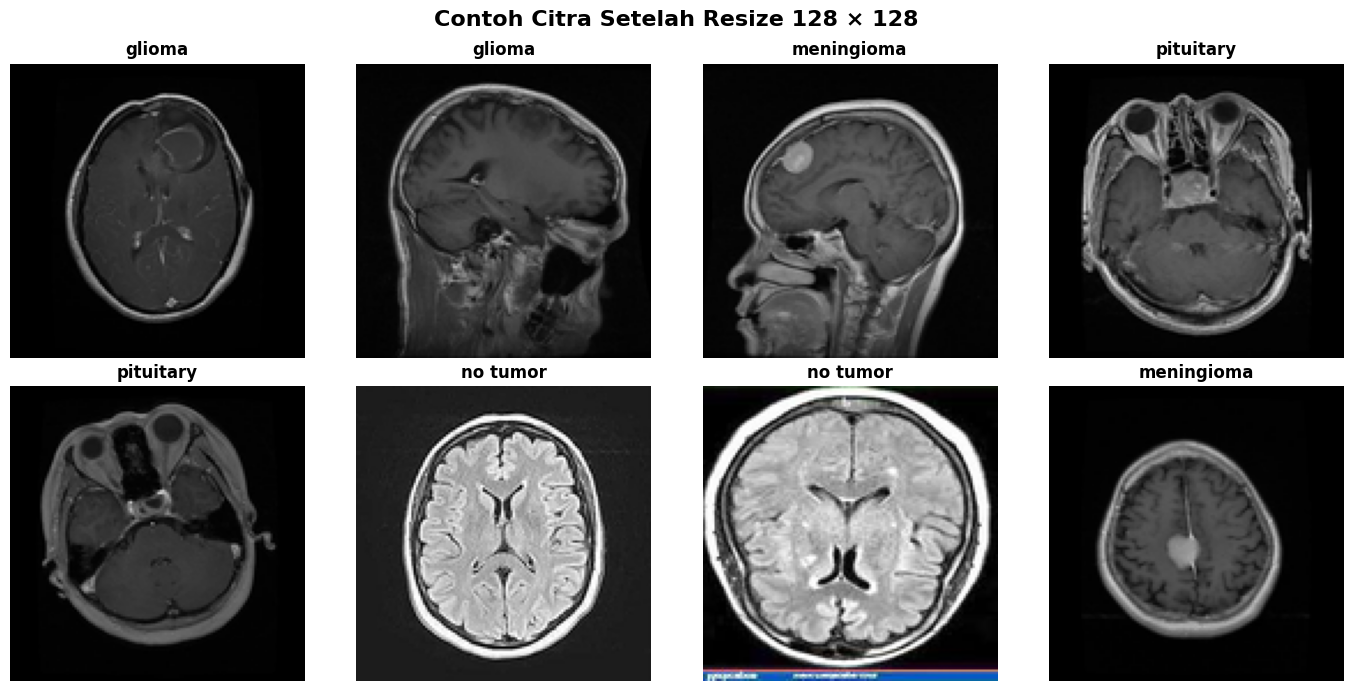


✅ PART 3 SELESAI

X shape      : (7200, 128, 128, 3)
y shape      : (7200,)
Image size   : (128, 128)
Channel      : RGB (3 channel)
X dtype      : uint8
Nilai pixel  : 0 - 255
Gagal        : 0

💾 X dan y sudah disimpan ke Google Drive.
➡️ Jika semua valid, lanjut ke PART 4.


In [ ]:
# ============================================================
# PART 3 — PREPROCESSING CITRA
# BRAIN TUMOR MRI CNN
# ============================================================

print("=" * 70)
print("🧠 PART 3 — PREPROCESSING CITRA")
print("=" * 70)


# ------------------------------------------------------------
# 1. IMPORT LIBRARY GAMBAR
# ------------------------------------------------------------

from PIL import Image


# ------------------------------------------------------------
# 2. CEK DATA PART 2
# ------------------------------------------------------------

if "dataset_df" not in globals():

    raise ValueError(
        "dataset_df belum tersedia. "
        "Jalankan Part 2 terlebih dahulu."
    )


if len(dataset_df) == 0:

    raise ValueError(
        "dataset_df kosong. "
        "Periksa kembali dataset pada Part 2."
    )


# ------------------------------------------------------------
# 3. INFORMASI AWAL
# ------------------------------------------------------------

total_images = len(
    dataset_df
)


print("\n📊 INFORMASI DATA")
print("-" * 70)

print(
    "Jumlah gambar :",
    total_images
)

print(
    "Ukuran target :",
    IMAGE_SIZE
)

print(
    "Format input  : RGB"
)


# ------------------------------------------------------------
# 4. SIAPKAN ARRAY X DAN y
# ------------------------------------------------------------

# uint8 digunakan agar penggunaan RAM lebih hemat.
#
# Nilai pixel:
# 0   = hitam
# 255 = putih
#
# Normalisasi menjadi 0–1 akan dilakukan nanti
# saat data dimasukkan ke TensorFlow Dataset.

X = np.zeros(
    (
        total_images,
        IMAGE_SIZE[0],
        IMAGE_SIZE[1],
        3
    ),
    dtype=np.uint8
)


y = dataset_df[
    "label"
].values.astype(
    np.int32
)


# ------------------------------------------------------------
# 5. BACA DAN RESIZE SEMUA GAMBAR
# ------------------------------------------------------------

failed_images = []

successful_images = 0


print("\n⏳ Mulai preprocessing...")
print("Mohon tunggu sampai selesai.\n")


for index, row in dataset_df.iterrows():

    image_path = row[
        "filepath"
    ]

    try:

        # --------------------------------------------
        # Buka gambar
        # --------------------------------------------

        image = Image.open(
            image_path
        )


        # --------------------------------------------
        # Ubah ke RGB
        # --------------------------------------------

        image = image.convert(
            "RGB"
        )


        # --------------------------------------------
        # Resize ke 128 × 128
        # --------------------------------------------

        image = image.resize(
            IMAGE_SIZE,
            Image.Resampling.LANCZOS
        )


        # --------------------------------------------
        # Ubah menjadi NumPy array
        # --------------------------------------------

        image_array = np.array(
            image,
            dtype=np.uint8
        )


        # --------------------------------------------
        # Pastikan ukuran benar
        # --------------------------------------------

        if image_array.shape != (
            IMAGE_SIZE[0],
            IMAGE_SIZE[1],
            3
        ):

            raise ValueError(
                f"Ukuran gambar tidak sesuai: "
                f"{image_array.shape}"
            )


        # --------------------------------------------
        # Simpan ke X
        # --------------------------------------------

        X[index] = image_array


        successful_images += 1


    except Exception as error:

        failed_images.append({

            "index":
                int(index),

            "filepath":
                image_path,

            "error":
                str(error)

        })


# ------------------------------------------------------------
# 6. HASIL PREPROCESSING
# ------------------------------------------------------------

print("=" * 70)
print("📊 HASIL PREPROCESSING")
print("=" * 70)

print(
    "\nBerhasil diproses :",
    successful_images
)

print(
    "Gagal diproses    :",
    len(failed_images)
)

print(
    "Shape X           :",
    X.shape
)

print(
    "Shape y           :",
    y.shape
)

print(
    "Tipe data X       :",
    X.dtype
)

print(
    "Tipe data y       :",
    y.dtype
)


# ------------------------------------------------------------
# 7. JIKA ADA GAMBAR GAGAL
# ------------------------------------------------------------

if len(failed_images) > 0:

    print(
        "\n⚠️ Ada gambar yang gagal diproses."
    )

    failed_df = pd.DataFrame(
        failed_images
    )

    display(
        failed_df.head(20)
    )


else:

    failed_df = pd.DataFrame(
        columns=[
            "index",
            "filepath",
            "error"
        ]
    )

    print(
        "\n✅ Semua gambar berhasil diproses."
    )


# ------------------------------------------------------------
# 8. VALIDASI X
# ------------------------------------------------------------

print("\n🔍 VALIDASI ARRAY")
print("-" * 70)


print(
    "Jumlah nilai minimum:",
    X.min()
)

print(
    "Jumlah nilai maksimum:",
    X.max()
)


# Cek NaN
x_nan = np.isnan(
    X.astype(
        np.float32
    )
).sum()


print(
    "Jumlah NaN pada X:",
    x_nan
)


# Cek infinite
x_inf = np.isinf(
    X.astype(
        np.float32
    )
).sum()


print(
    "Jumlah Inf pada X:",
    x_inf
)


if x_nan == 0 and x_inf == 0:

    print(
        "✅ X tidak memiliki NaN atau Inf."
    )

else:

    print(
        "⚠️ X memiliki nilai bermasalah."
    )


# ------------------------------------------------------------
# 9. VALIDASI LABEL
# ------------------------------------------------------------

print("\n🏷️ DISTRIBUSI LABEL")
print("-" * 70)


label_counts = (

    pd.Series(y)
    .value_counts()
    .sort_index()

)


label_table = pd.DataFrame({

    "Label":
        label_counts.index,

    "Nama Kelas":
        [
            class_names[
                int(label)
            ]

            for label
            in label_counts.index
        ],

    "Jumlah":
        label_counts.values

})


display(
    label_table
)


# ------------------------------------------------------------
# 10. CEK LABEL VALID
# ------------------------------------------------------------

valid_labels = set(
    range(
        NUM_CLASSES
    )
)


actual_labels = set(
    y.tolist()
)


if actual_labels.issubset(
    valid_labels
):

    print(
        "✅ Semua label valid."
    )

else:

    print(
        "⚠️ Ditemukan label yang tidak valid:"
    )

    print(
        actual_labels
        - valid_labels
    )


# ------------------------------------------------------------
# 11. TAMPILKAN CONTOH CITRA
# ------------------------------------------------------------

print("\n🖼️ CONTOH HASIL PREPROCESSING")
print("-" * 70)


# Ambil maksimal 8 gambar
sample_count = min(
    8,
    len(X)
)


# Gunakan index yang tersebar
sample_indices = np.linspace(
    0,
    len(X) - 1,
    sample_count,
    dtype=int
)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)


axes = axes.flatten()


for plot_index, data_index in enumerate(
    sample_indices
):

    axes[
        plot_index
    ].imshow(
        X[data_index]
    )

    label_index = int(
        y[data_index]
    )

    axes[
        plot_index
    ].set_title(
        class_names[label_index],
        fontsize=12,
        fontweight="bold"
    )

    axes[
        plot_index
    ].axis(
        "off"
    )


# Jika jumlah gambar kurang dari 8
for empty_index in range(
    sample_count,
    len(axes)
):

    axes[
        empty_index
    ].axis(
        "off"
    )


plt.suptitle(
    "Contoh Citra Setelah Resize 128 × 128",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()


preprocessing_sample_path = save_figure(
    "preprocessing_sample.png"
)


# ------------------------------------------------------------
# 12. SIMPAN DATA GAMBAR GAGAL
# ------------------------------------------------------------

failed_path = os.path.join(

    RESULT_DIR,
    "failed_images.csv"

)


failed_df.to_csv(

    failed_path,
    index=False

)


# ------------------------------------------------------------
# 13. SIMPAN HASIL PREPROCESSING KE CACHE
# ------------------------------------------------------------

cache = load_cache()


cache["preprocessing"] = {

    "total_images":
        int(len(X)),

    "successful_images":
        int(successful_images),

    "failed_images":
        int(len(failed_images)),

    "image_size":
        list(IMAGE_SIZE),

    "input_shape":
        list(INPUT_SHAPE),

    "x_dtype":
        str(X.dtype),

    "y_dtype":
        str(y.dtype),

    "x_min":
        int(X.min()),

    "x_max":
        int(X.max())

}


# ------------------------------------------------------------
# 14. SIMPAN X DAN y SECARA TEMPORER
# ------------------------------------------------------------
#
# X dan y disimpan sebagai file NumPy di Google Drive.
# Jadi jika runtime Colab restart, kita tidak harus
# membaca dan resize semua gambar dari awal.
#
# ------------------------------------------------------------

X_FILE = os.path.join(
    CACHE_DIR,
    "X_images.npy"
)

Y_FILE = os.path.join(
    CACHE_DIR,
    "y_labels.npy"
)


np.save(
    X_FILE,
    X
)

np.save(
    Y_FILE,
    y
)


cache["preprocessing"]["X_file"] = X_FILE
cache["preprocessing"]["y_file"] = Y_FILE


save_cache(
    cache
)


# ------------------------------------------------------------
# 15. RINGKASAN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ PART 3 SELESAI")
print("=" * 70)

print(
    "\nX shape      :",
    X.shape
)

print(
    "y shape      :",
    y.shape
)

print(
    "Image size   :",
    IMAGE_SIZE
)

print(
    "Channel      : RGB (3 channel)"
)

print(
    "X dtype      :",
    X.dtype
)

print(
    "Nilai pixel  :",
    f"{X.min()} - {X.max()}"
)

print(
    "Gagal        :",
    len(failed_images)
)

print(
    "\n💾 X dan y sudah disimpan ke Google Drive."
)

print(
    "➡️ Jika semua valid, lanjut ke PART 4."
)

🧠 PART 4 — EKSPLORASI DATASET & VISUALISASI

📊 INFORMASI DATASET
----------------------------------------------------------------------
Total gambar        : 7200
Ukuran gambar       : 128 × 128
Jumlah channel      : 3
Format              : RGB
Jumlah kelas        : 4

📋 DISTRIBUSI DATASET PER KELAS
----------------------------------------------------------------------


,Label,Kelas,Jumlah Gambar,Persentase
0,0,glioma,1800,25.0
1,1,meningioma,1800,25.0
2,2,no tumor,1800,25.0
3,3,pituitary,1800,25.0



🔍 VALIDASI DISTRIBUSI
----------------------------------------------------------------------
✅ Semua kelas memiliki data.

📊 MEMBUAT GRAFIK DISTRIBUSI...
----------------------------------------------------------------------


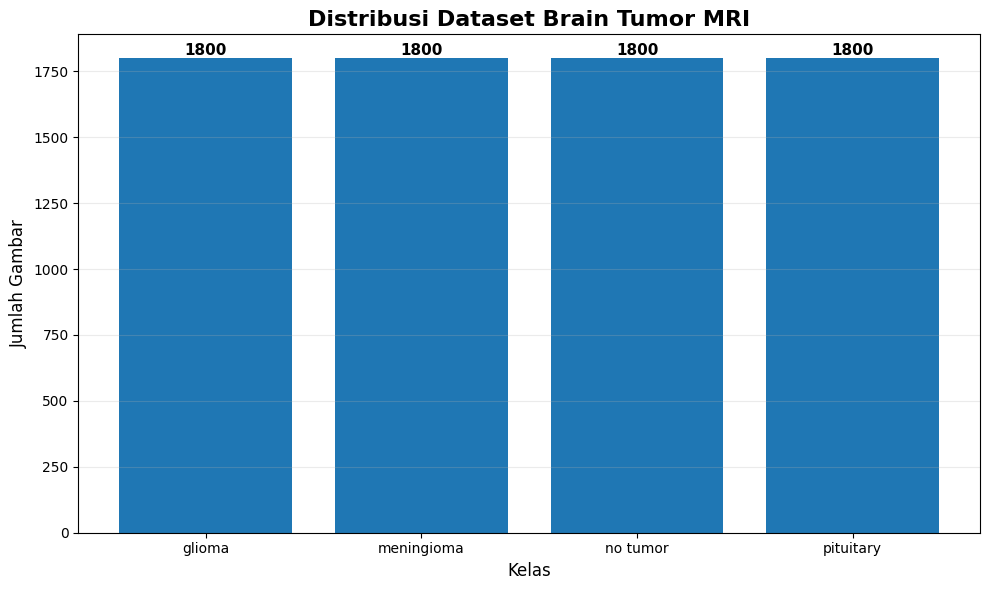


📊 MEMBUAT GRAFIK PERSENTASE...
----------------------------------------------------------------------


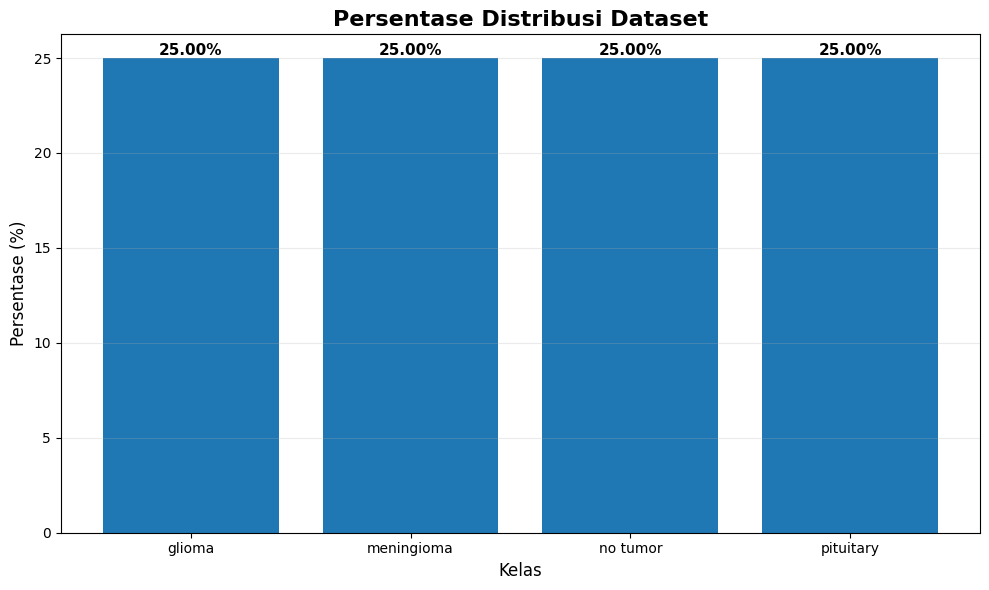


🖼️ MEMBUAT GRAFIK CONTOH CITRA...
----------------------------------------------------------------------


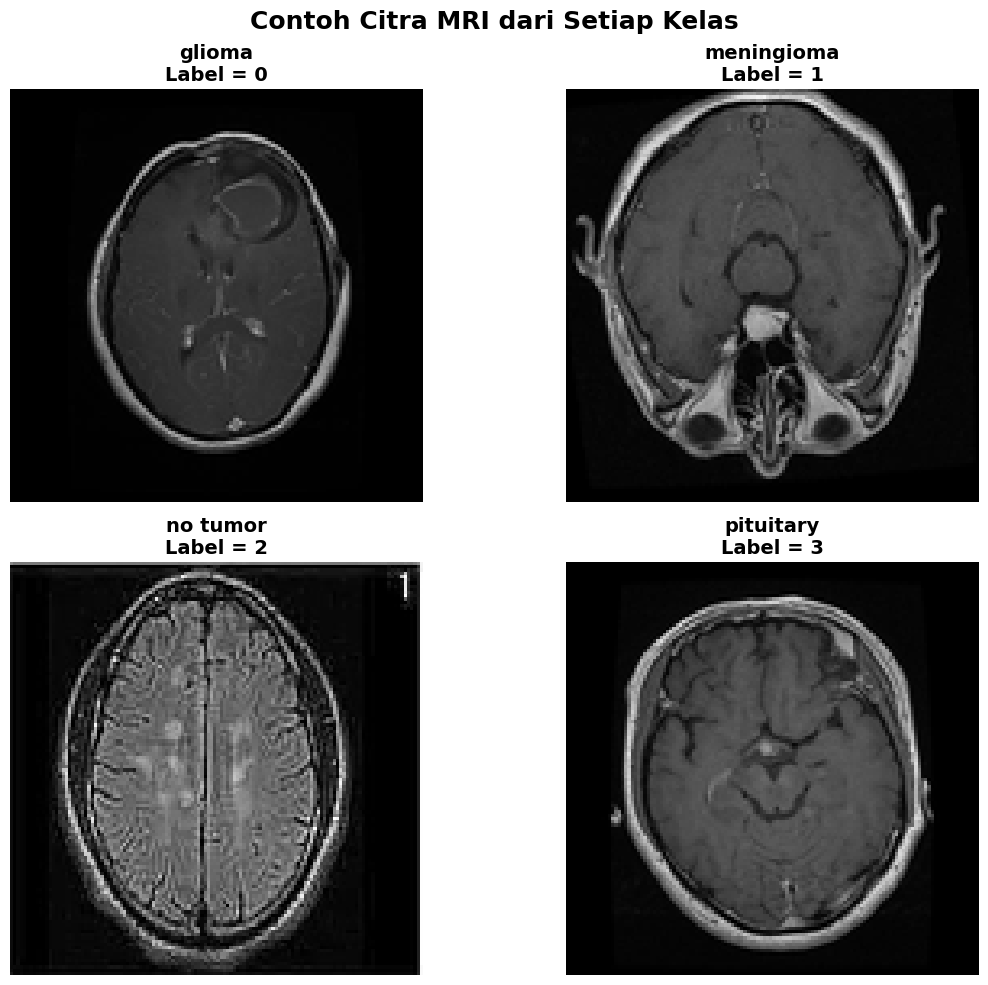


🖼️ MEMBUAT GRID CITRA ACAK...
----------------------------------------------------------------------


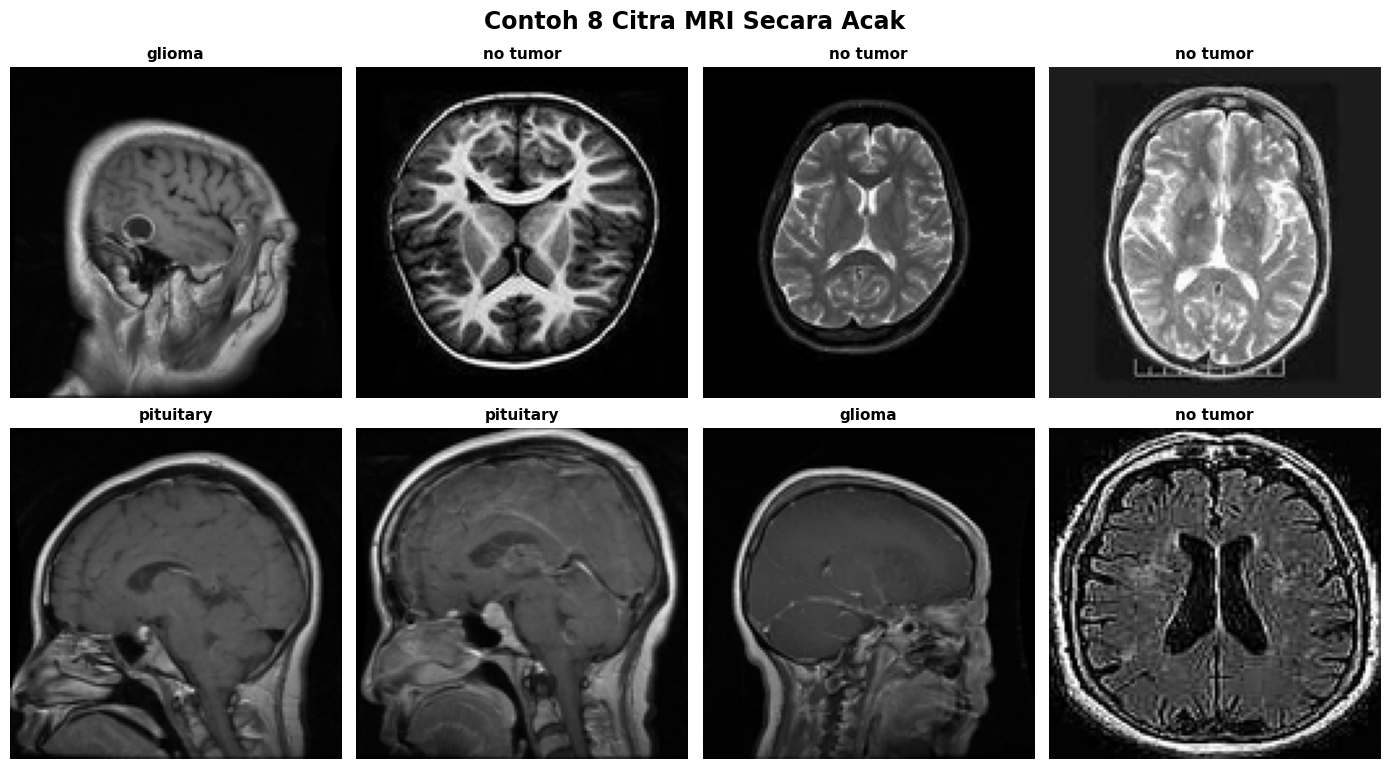


📈 STATISTIK NILAI PIXEL
----------------------------------------------------------------------


,Statistik,Nilai
0,Minimum pixel,0.00
1,Maximum pixel,255.00
2,Rata-rata pixel,47.57
3,Standar deviasi pixel,51.21



⚖️ CEK KESEIMBANGAN DATA
----------------------------------------------------------------------
Jumlah terbanyak : 1800
Jumlah tersedikit: 1800
Rasio max/min    : 1.0
Keterangan       : Distribusi relatif seimbang.

✅ PART 4 SELESAI

📊 Total gambar : 7200
🖼️ Ukuran       : 128 × 128
🎨 Channel      : 3
🏷️ Kelas        : glioma, meningioma, no tumor, pituitary

💾 File grafik tersimpan di:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik

💾 File tabel tersimpan di:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil

➡️ Jika semua grafik dan tabel muncul tanpa error,
   lanjut ke PART 5 — Arsitektur CNN.


In [ ]:
# ============================================================
# PART 4 — EKSPLORASI DATASET & VISUALISASI
# BRAIN TUMOR MRI CNN
# ============================================================

print("=" * 70)
print("🧠 PART 4 — EKSPLORASI DATASET & VISUALISASI")
print("=" * 70)


# ------------------------------------------------------------
# 1. CEK DATA PART 2 DAN PART 3
# ------------------------------------------------------------

if "dataset_df" not in globals():

    raise ValueError(
        "dataset_df belum tersedia. "
        "Jalankan Part 2 terlebih dahulu."
    )


if "X" not in globals() or "y" not in globals():

    raise ValueError(
        "X atau y belum tersedia. "
        "Jalankan Part 3 terlebih dahulu."
    )


if len(X) != len(y):

    raise ValueError(
        "Jumlah X dan y tidak sama."
    )


# ------------------------------------------------------------
# 2. INFORMASI DATASET
# ------------------------------------------------------------

total_images = len(X)

image_height = X.shape[1]
image_width = X.shape[2]
image_channels = X.shape[3]


print("\n📊 INFORMASI DATASET")
print("-" * 70)

print(
    "Total gambar        :",
    total_images
)

print(
    "Ukuran gambar       :",
    f"{image_height} × {image_width}"
)

print(
    "Jumlah channel      :",
    image_channels
)

print(
    "Format              : RGB"
)

print(
    "Jumlah kelas        :",
    NUM_CLASSES
)


# ------------------------------------------------------------
# 3. DISTRIBUSI KELAS
# ------------------------------------------------------------

class_counts = (

    dataset_df[
        "class_name"
    ]
    .value_counts()
    .reindex(
        class_names,
        fill_value=0
    )

)


distribution_df = pd.DataFrame({

    "Kelas":
        class_names,

    "Jumlah Gambar":
        [
            int(
                class_counts[
                    class_name
                ]
            )

            for class_name
            in class_names
        ]

})


# ------------------------------------------------------------
# 4. HITUNG PERSENTASE
# ------------------------------------------------------------

distribution_df[
    "Persentase"
] = (

    distribution_df[
        "Jumlah Gambar"
    ]
    / total_images
    * 100

).round(2)


# ------------------------------------------------------------
# 5. TAMBAHKAN LABEL NUMERIK
# ------------------------------------------------------------

distribution_df.insert(

    0,

    "Label",

    [
        class_to_index[
            class_name
        ]

        for class_name
        in class_names
    ]

)


# ------------------------------------------------------------
# 6. TAMPILKAN TABEL DISTRIBUSI
# ------------------------------------------------------------

print("\n📋 DISTRIBUSI DATASET PER KELAS")
print("-" * 70)

display(
    distribution_df
)


# ------------------------------------------------------------
# 7. VALIDASI DISTRIBUSI
# ------------------------------------------------------------

print("\n🔍 VALIDASI DISTRIBUSI")
print("-" * 70)


zero_classes = distribution_df[
    distribution_df[
        "Jumlah Gambar"
    ] == 0
]


if len(zero_classes) == 0:

    print(
        "✅ Semua kelas memiliki data."
    )

else:

    print(
        "⚠️ Ada kelas yang jumlah datanya 0:"
    )

    display(
        zero_classes
    )


# ------------------------------------------------------------
# 8. GRAFIK DISTRIBUSI DATASET
# ------------------------------------------------------------

print("\n📊 MEMBUAT GRAFIK DISTRIBUSI...")
print("-" * 70)


plt.figure(
    figsize=(10, 6)
)


bars = plt.bar(

    distribution_df[
        "Kelas"
    ],

    distribution_df[
        "Jumlah Gambar"
    ]

)


plt.title(
    "Distribusi Dataset Brain Tumor MRI",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Kelas",
    fontsize=12
)

plt.ylabel(
    "Jumlah Gambar",
    fontsize=12
)


plt.xticks(
    rotation=0
)


# Tambahkan angka di atas batang
for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        height,

        f"{int(height)}",

        ha="center",

        va="bottom",

        fontsize=11,

        fontweight="bold"

    )


plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


distribution_graph_path = save_figure(
    "distribusi_dataset.png"
)


# ------------------------------------------------------------
# 9. GRAFIK PERSENTASE
# ------------------------------------------------------------

print("\n📊 MEMBUAT GRAFIK PERSENTASE...")
print("-" * 70)


plt.figure(
    figsize=(10, 6)
)


bars = plt.bar(

    distribution_df[
        "Kelas"
    ],

    distribution_df[
        "Persentase"
    ]

)


plt.title(
    "Persentase Distribusi Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Kelas",
    fontsize=12
)

plt.ylabel(
    "Persentase (%)",
    fontsize=12
)


for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        height,

        f"{height:.2f}%",

        ha="center",

        va="bottom",

        fontsize=11,

        fontweight="bold"

    )


plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


percentage_graph_path = save_figure(
    "persentase_dataset.png"
)


# ------------------------------------------------------------
# 10. CONTOH SATU GAMBAR DARI SETIAP KELAS
# ------------------------------------------------------------

print("\n🖼️ MEMBUAT GRAFIK CONTOH CITRA...")
print("-" * 70)


fig, axes = plt.subplots(

    2,
    2,

    figsize=(12, 10)

)


axes = axes.flatten()


for class_index, class_name in enumerate(
    class_names
):

    # Cari index gambar dari kelas tersebut
    class_indices = np.where(
        y == class_index
    )[0]


    if len(class_indices) == 0:

        axes[
            class_index
        ].text(

            0.5,
            0.5,

            "Data tidak tersedia",

            ha="center",
            va="center",

            fontsize=13

        )

        axes[
            class_index
        ].set_title(
            class_name,
            fontsize=14,
            fontweight="bold"
        )

        axes[
            class_index
        ].axis("off")

        continue


    # Ambil gambar pertama
    selected_index = class_indices[0]


    axes[
        class_index
    ].imshow(
        X[selected_index]
    )


    axes[
        class_index
    ].set_title(

        f"{class_name}\n"
        f"Label = {class_index}",

        fontsize=14,

        fontweight="bold"

    )


    axes[
        class_index
    ].axis("off")


plt.suptitle(

    "Contoh Citra MRI dari Setiap Kelas",

    fontsize=18,

    fontweight="bold"

)

plt.tight_layout()


sample_classes_path = save_figure(
    "sampel_citra_per_kelas.png"
)


# ------------------------------------------------------------
# 11. BUAT GRID 8 CITRA ACAK
# ------------------------------------------------------------

print("\n🖼️ MEMBUAT GRID CITRA ACAK...")
print("-" * 70)


sample_count = min(
    8,
    total_images
)


rng = np.random.default_rng(
    RANDOM_STATE
)


random_indices = rng.choice(

    total_images,

    size=sample_count,

    replace=False

)


fig, axes = plt.subplots(

    2,
    4,

    figsize=(14, 8)

)


axes = axes.flatten()


for plot_index, data_index in enumerate(
    random_indices
):

    label_index = int(
        y[data_index]
    )


    axes[
        plot_index
    ].imshow(
        X[data_index]
    )


    axes[
        plot_index
    ].set_title(

        class_names[
            label_index
        ],

        fontsize=11,

        fontweight="bold"

    )


    axes[
        plot_index
    ].axis("off")


for empty_index in range(

    sample_count,

    len(axes)

):

    axes[
        empty_index
    ].axis("off")


plt.suptitle(

    "Contoh 8 Citra MRI Secara Acak",

    fontsize=17,

    fontweight="bold"

)

plt.tight_layout()


random_sample_path = save_figure(
    "sampel_citra_acak.png"
)


# ------------------------------------------------------------
# 12. STATISTIK PIXEL
# ------------------------------------------------------------

print("\n📈 STATISTIK NILAI PIXEL")
print("-" * 70)


pixel_mean = float(
    X.mean()
)


pixel_std = float(
    X.std()
)


pixel_min = int(
    X.min()
)


pixel_max = int(
    X.max()
)


pixel_statistics_df = pd.DataFrame({

    "Statistik": [

        "Minimum pixel",
        "Maximum pixel",
        "Rata-rata pixel",
        "Standar deviasi pixel"

    ],

    "Nilai": [

        pixel_min,
        pixel_max,
        round(pixel_mean, 2),
        round(pixel_std, 2)

    ]

})


display(
    pixel_statistics_df
)


# ------------------------------------------------------------
# 13. CEK KESEIMBANGAN DATA
# ------------------------------------------------------------

print("\n⚖️ CEK KESEIMBANGAN DATA")
print("-" * 70)


max_count = distribution_df[
    "Jumlah Gambar"
].max()


min_count = distribution_df[
    "Jumlah Gambar"
].min()


if min_count == 0:

    print(
        "⚠️ Ada kelas tanpa data."
    )

else:

    imbalance_ratio = (
        max_count / min_count
    )


    print(
        "Jumlah terbanyak :",
        max_count
    )

    print(
        "Jumlah tersedikit:",
        min_count
    )

    print(
        "Rasio max/min    :",
        round(
            imbalance_ratio,
            3
        )
    )


    if imbalance_ratio <= 1.5:

        print(
            "Keterangan       : Distribusi relatif seimbang."
        )

    elif imbalance_ratio <= 2:

        print(
            "Keterangan       : Terdapat sedikit ketidakseimbangan."
        )

    else:

        print(
            "Keterangan       : Terdapat ketidakseimbangan yang cukup besar."
        )


# ------------------------------------------------------------
# 14. SIMPAN TABEL DISTRIBUSI
# ------------------------------------------------------------

distribution_csv_path = os.path.join(

    RESULT_DIR,

    "distribusi_dataset.csv"

)


distribution_df.to_csv(

    distribution_csv_path,

    index=False

)


# ------------------------------------------------------------
# 15. SIMPAN STATISTIK PIXEL
# ------------------------------------------------------------

pixel_csv_path = os.path.join(

    RESULT_DIR,

    "statistik_pixel.csv"

)


pixel_statistics_df.to_csv(

    pixel_csv_path,

    index=False

)


# ------------------------------------------------------------
# 16. SIMPAN INFORMASI EKSPLORASI KE CACHE
# ------------------------------------------------------------

cache = load_cache()


cache["exploration"] = {

    "total_images":
        int(total_images),

    "image_height":
        int(image_height),

    "image_width":
        int(image_width),

    "image_channels":
        int(image_channels),

    "pixel_mean":
        pixel_mean,

    "pixel_std":
        pixel_std,

    "pixel_min":
        pixel_min,

    "pixel_max":
        pixel_max,

    "distribution":
        distribution_df.to_dict(
            orient="records"
        ),

    "graphs": {

        "distribution":
            distribution_graph_path,

        "percentage":
            percentage_graph_path,

        "sample_classes":
            sample_classes_path,

        "random_samples":
            random_sample_path

    }

}


save_cache(
    cache
)


# ------------------------------------------------------------
# 17. RINGKASAN PART 4
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ PART 4 SELESAI")
print("=" * 70)


print(
    "\n📊 Total gambar :",
    total_images
)

print(
    "🖼️ Ukuran       :",
    f"{image_height} × {image_width}"
)

print(
    "🎨 Channel      :",
    image_channels
)

print(
    "🏷️ Kelas        :",
    ", ".join(class_names)
)


print("\n💾 File grafik tersimpan di:")
print(
    GRAPH_DIR
)


print("\n💾 File tabel tersimpan di:")
print(
    RESULT_DIR
)


print(
    "\n➡️ Jika semua grafik dan tabel muncul tanpa error,"
)

print(
    "   lanjut ke PART 5 — Arsitektur CNN."
)

🧠 PART 5 — ARSITEKTUR CNN BASELINE

⚙️ KONFIGURASI MODEL BASELINE
----------------------------------------------------------------------
Input shape      : (128, 128, 3)
Jumlah kelas     : 4
Dropout          : 0.3
Optimizer        : Adam
Learning rate    : 0.0005

📋 RINGKASAN ARSITEKTUR CNN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_block1 (Conv2D)            │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_block1 (MaxPooling2D)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block2 (Conv2D)            │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_block2 (MaxPooling2D)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block3 (Conv2D)            │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_block3 (MaxPooling2D)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block4 (Conv2D)            │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_block4 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,290,052 (4.92 MB)

 Trainable params: 1,290,052 (4.92 MB)

 Non-trainable params: 0 (0.00 B)


📊 JUMLAH PARAMETER
----------------------------------------------------------------------
Total parameter: 1,290,052

📋 TABEL ARSITEKTUR CNN
----------------------------------------------------------------------


,No,Layer,Tipe Layer,Output Shape,Parameter
0,1,conv_block1,Conv2D,"(None, 128, 128, 32)",896
1,2,pool_block1,MaxPooling2D,"(None, 64, 64, 32)",0
2,3,conv_block2,Conv2D,"(None, 64, 64, 64)",18496
3,4,pool_block2,MaxPooling2D,"(None, 32, 32, 64)",0
4,5,conv_block3,Conv2D,"(None, 32, 32, 128)",73856
5,6,pool_block3,MaxPooling2D,"(None, 16, 16, 128)",0
6,7,conv_block4,Conv2D,"(None, 16, 16, 128)",147584
7,8,pool_block4,MaxPooling2D,"(None, 8, 8, 128)",0
8,9,flatten,Flatten,"(None, 8192)",0
9,10,dense_128,Dense,"(None, 128)",1048704



🎨 MEMBUAT DIAGRAM ARSITEKTUR...
----------------------------------------------------------------------


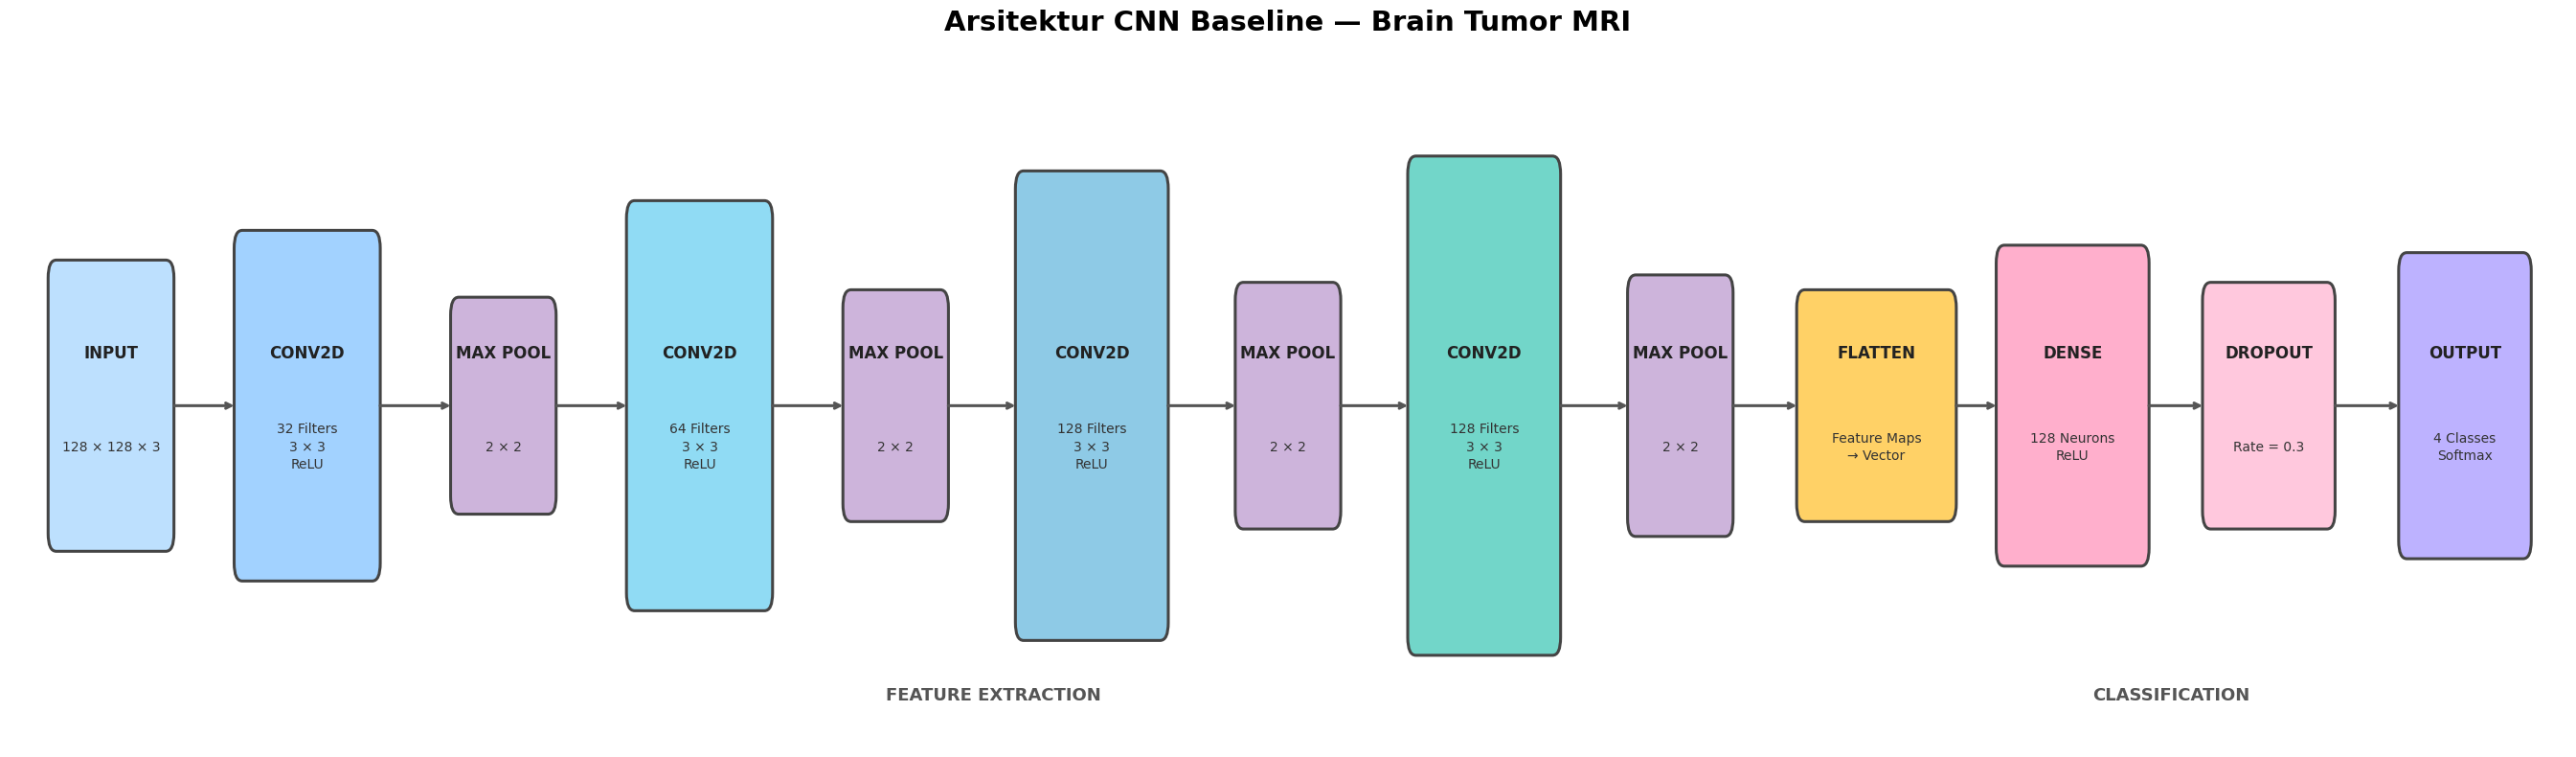


🧠 RINGKASAN ARSITEKTUR CNN

Input → Conv2D 32 → MaxPooling → Conv2D 64 → MaxPooling
 → Conv2D 128 → MaxPooling → Conv2D 128 → MaxPooling
 → Flatten → Dense 128 → Dropout 0.3 → Output 4 Softmax

📊 Total parameter:
1,290,052

📁 File model:
/content/drive/MyDrive/Brain_Tumor_CNN/models/cnn_baseline.keras

📁 Diagram:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/arsitektur_cnn_baseline_berwarna.png

📁 Tabel arsitektur:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/arsitektur_cnn_baseline.csv

✅ PART 5 SELESAI

➡️ Berikutnya: PART 6 — Pipeline TensorFlow + Checkpoint & Resume Training.


In [ ]:
# ============================================================
# PART 5 — ARSITEKTUR CNN BASELINE
# BRAIN TUMOR MRI CNN
# ============================================================

print("=" * 70)
print("🧠 PART 5 — ARSITEKTUR CNN BASELINE")
print("=" * 70)


# ------------------------------------------------------------
# 1. IMPORT LAYER CNN
# ------------------------------------------------------------

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from matplotlib.patches import FancyBboxPatch


# ------------------------------------------------------------
# 2. CEK KONFIGURASI PART 1
# ------------------------------------------------------------

if "INPUT_SHAPE" not in globals():

    raise ValueError(
        "INPUT_SHAPE belum tersedia. "
        "Jalankan Part 1 terlebih dahulu."
    )


if "NUM_CLASSES" not in globals():

    raise ValueError(
        "NUM_CLASSES belum tersedia. "
        "Jalankan Part 1 terlebih dahulu."
    )


# ------------------------------------------------------------
# 3. KONFIGURASI BASELINE
# ------------------------------------------------------------

BASELINE_DROPOUT = 0.3

BASELINE_OPTIMIZER = "Adam"

BASELINE_LEARNING_RATE = 0.0005


print("\n⚙️ KONFIGURASI MODEL BASELINE")
print("-" * 70)

print(
    "Input shape      :",
    INPUT_SHAPE
)

print(
    "Jumlah kelas     :",
    NUM_CLASSES
)

print(
    "Dropout          :",
    BASELINE_DROPOUT
)

print(
    "Optimizer        :",
    BASELINE_OPTIMIZER
)

print(
    "Learning rate    :",
    BASELINE_LEARNING_RATE
)


# ------------------------------------------------------------
# 4. FUNGSI MEMBUAT MODEL CNN
# ------------------------------------------------------------

def build_cnn_model(
    dropout_rate=0.3
):

    model = Sequential([

        # ====================================================
        # INPUT
        # ====================================================

        Input(
            shape=INPUT_SHAPE,
            name="input_mri"
        ),


        # ====================================================
        # CONVOLUTION BLOCK 1
        # ====================================================

        Conv2D(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_block1"
        ),

        MaxPooling2D(
            pool_size=(2, 2),
            name="pool_block1"
        ),


        # ====================================================
        # CONVOLUTION BLOCK 2
        # ====================================================

        Conv2D(
            filters=64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_block2"
        ),

        MaxPooling2D(
            pool_size=(2, 2),
            name="pool_block2"
        ),


        # ====================================================
        # CONVOLUTION BLOCK 3
        # ====================================================

        Conv2D(
            filters=128,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_block3"
        ),

        MaxPooling2D(
            pool_size=(2, 2),
            name="pool_block3"
        ),


        # ====================================================
        # CONVOLUTION BLOCK 4
        # ====================================================

        Conv2D(
            filters=128,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_block4"
        ),

        MaxPooling2D(
            pool_size=(2, 2),
            name="pool_block4"
        ),


        # ====================================================
        # FLATTEN
        # ====================================================

        Flatten(
            name="flatten"
        ),


        # ====================================================
        # DENSE
        # ====================================================

        Dense(
            128,
            activation="relu",
            name="dense_128"
        ),


        # ====================================================
        # DROPOUT
        # ====================================================

        Dropout(
            dropout_rate,
            name="dropout"
        ),


        # ====================================================
        # OUTPUT
        # ====================================================

        Dense(
            NUM_CLASSES,
            activation="softmax",
            name="output"
        )

    ])

    return model


# ------------------------------------------------------------
# 5. BUAT MODEL BASELINE
# ------------------------------------------------------------

model = build_cnn_model(
    dropout_rate=BASELINE_DROPOUT
)


# ------------------------------------------------------------
# 6. TAMPILKAN RINGKASAN MODEL
# ------------------------------------------------------------

print("\n📋 RINGKASAN ARSITEKTUR CNN")
print("=" * 70)

model.summary()


# ------------------------------------------------------------
# 7. HITUNG TOTAL PARAMETER
# ------------------------------------------------------------

total_params = model.count_params()


print("\n📊 JUMLAH PARAMETER")
print("-" * 70)

print(
    "Total parameter:",
    f"{total_params:,}"
)


# ------------------------------------------------------------
# 8. BUAT TABEL ARSITEKTUR
# ------------------------------------------------------------

architecture_records = []


for layer_number, layer in enumerate(
    model.layers,
    start=1
):

    output_shape = tuple(
        layer.output.shape
    )


    architecture_records.append({

        "No":
            layer_number,

        "Layer":
            layer.name,

        "Tipe Layer":
            layer.__class__.__name__,

        "Output Shape":
            str(output_shape),

        "Parameter":
            layer.count_params()

    })


architecture_df = pd.DataFrame(
    architecture_records
)


# ------------------------------------------------------------
# 9. TAMPILKAN TABEL ARSITEKTUR
# ------------------------------------------------------------

print("\n📋 TABEL ARSITEKTUR CNN")
print("-" * 70)

display(
    architecture_df
)


# ------------------------------------------------------------
# 10. DIAGRAM ARSITEKTUR CNN BERWARNA
# ------------------------------------------------------------

print("\n🎨 MEMBUAT DIAGRAM ARSITEKTUR...")
print("-" * 70)


layers = [

    {
        "name": "INPUT",
        "detail": "128 × 128 × 3",
        "width": 1.7,
        "height": 1.8,
        "color": "#BDE0FE"
    },

    {
        "name": "CONV2D",
        "detail": "32 Filters\n3 × 3\nReLU",
        "width": 2.0,
        "height": 2.2,
        "color": "#A2D2FF"
    },

    {
        "name": "MAX POOL",
        "detail": "2 × 2",
        "width": 1.4,
        "height": 1.3,
        "color": "#CDB4DB"
    },

    {
        "name": "CONV2D",
        "detail": "64 Filters\n3 × 3\nReLU",
        "width": 2.0,
        "height": 2.6,
        "color": "#90DBF4"
    },

    {
        "name": "MAX POOL",
        "detail": "2 × 2",
        "width": 1.4,
        "height": 1.4,
        "color": "#CDB4DB"
    },

    {
        "name": "CONV2D",
        "detail": "128 Filters\n3 × 3\nReLU",
        "width": 2.1,
        "height": 3.0,
        "color": "#8ECAE6"
    },

    {
        "name": "MAX POOL",
        "detail": "2 × 2",
        "width": 1.4,
        "height": 1.5,
        "color": "#CDB4DB"
    },

    {
        "name": "CONV2D",
        "detail": "128 Filters\n3 × 3\nReLU",
        "width": 2.1,
        "height": 3.2,
        "color": "#72D6C9"
    },

    {
        "name": "MAX POOL",
        "detail": "2 × 2",
        "width": 1.4,
        "height": 1.6,
        "color": "#CDB4DB"
    },

    {
        "name": "FLATTEN",
        "detail": "Feature Maps\n→ Vector",
        "width": 2.2,
        "height": 1.4,
        "color": "#FFD166"
    },

    {
        "name": "DENSE",
        "detail": "128 Neurons\nReLU",
        "width": 2.1,
        "height": 2.0,
        "color": "#FFAFCC"
    },

    {
        "name": "DROPOUT",
        "detail": "Rate = 0.3",
        "width": 1.8,
        "height": 1.5,
        "color": "#FFC8DD"
    },

    {
        "name": "OUTPUT",
        "detail": "4 Classes\nSoftmax",
        "width": 1.8,
        "height": 1.9,
        "color": "#BDB2FF"
    }

]


# ------------------------------------------------------------
# 11. POSISI SETIAP LAYER
# ------------------------------------------------------------

x_positions = np.arange(
    len(layers)
) * 2.9


fig, ax = plt.subplots(
    figsize=(27, 8)
)


# ------------------------------------------------------------
# 12. GAMBAR KOTAK SETIAP LAYER
# ------------------------------------------------------------

for index, layer in enumerate(
    layers
):

    x = x_positions[index]

    width = layer["width"]

    height = layer["height"]

    y = -height / 2


    # Kotak rounded
    box = FancyBboxPatch(

        (
            x - width / 2,
            y
        ),

        width,

        height,

        boxstyle=(
            "round,pad=0.08,"
            "rounding_size=0.12"
        ),

        facecolor=layer["color"],

        edgecolor="#444444",

        linewidth=2.2

    )


    ax.add_patch(
        box
    )


    # Nama layer
    ax.text(

        x,

        0.35,

        layer["name"],

        ha="center",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="#222222"

    )


    # Detail layer
    ax.text(

        x,

        -0.28,

        layer["detail"],

        ha="center",

        va="center",

        fontsize=10,

        color="#333333",

        linespacing=1.4

    )


# ------------------------------------------------------------
# 13. PANAH ANTAR LAYER
# ------------------------------------------------------------

for index in range(
    len(layers) - 1
):

    current_layer = layers[
        index
    ]

    next_layer = layers[
        index + 1
    ]


    start_x = (

        x_positions[index]
        + current_layer["width"] / 2

    )


    end_x = (

        x_positions[index + 1]
        - next_layer["width"] / 2

    )


    ax.annotate(

        "",

        xy=(
            end_x,
            0
        ),

        xytext=(
            start_x,
            0
        ),

        arrowprops=dict(

            arrowstyle="->",

            linewidth=2.2,

            color="#555555",

            shrinkA=4,

            shrinkB=4

        )

    )


# ------------------------------------------------------------
# 14. LABEL FEATURE EXTRACTION
# ------------------------------------------------------------

ax.text(

    (
        x_positions[1]
        + x_positions[8]
    ) / 2,

    -1.95,

    "FEATURE EXTRACTION",

    ha="center",

    va="center",

    fontsize=13,

    fontweight="bold",

    color="#555555"

)


# ------------------------------------------------------------
# 15. LABEL CLASSIFICATION
# ------------------------------------------------------------

ax.text(

    (
        x_positions[9]
        + x_positions[12]
    ) / 2,

    -1.95,

    "CLASSIFICATION",

    ha="center",

    va="center",

    fontsize=13,

    fontweight="bold",

    color="#555555"

)


# ------------------------------------------------------------
# 16. JUDUL DIAGRAM
# ------------------------------------------------------------

ax.set_title(

    "Arsitektur CNN Baseline — Brain Tumor MRI",

    fontsize=21,

    fontweight="bold",

    pad=25

)


# ------------------------------------------------------------
# 17. ATUR AREA GRAFIK
# ------------------------------------------------------------

ax.set_xlim(

    -1.5,

    x_positions[-1] + 1.5

)


ax.set_ylim(

    -2.3,

    2.3

)


ax.axis(
    "off"
)


plt.tight_layout()


# ------------------------------------------------------------
# 18. SIMPAN DIAGRAM
# ------------------------------------------------------------

architecture_graph_path = save_figure(

    "arsitektur_cnn_baseline_berwarna.png"

)


# ------------------------------------------------------------
# 19. SIMPAN TABEL ARSITEKTUR
# ------------------------------------------------------------

architecture_csv_path = os.path.join(

    RESULT_DIR,

    "arsitektur_cnn_baseline.csv"

)


architecture_df.to_csv(

    architecture_csv_path,

    index=False

)


# ------------------------------------------------------------
# 20. KONFIGURASI ARSITEKTUR
# ------------------------------------------------------------

architecture_config = {

    "input_shape":
        list(INPUT_SHAPE),

    "convolution_layers": [

        {
            "filters": 32,
            "kernel_size": [3, 3],
            "activation": "relu",
            "padding": "same"
        },

        {
            "filters": 64,
            "kernel_size": [3, 3],
            "activation": "relu",
            "padding": "same"
        },

        {
            "filters": 128,
            "kernel_size": [3, 3],
            "activation": "relu",
            "padding": "same"
        },

        {
            "filters": 128,
            "kernel_size": [3, 3],
            "activation": "relu",
            "padding": "same"
        }

    ],

    "pooling":
        "MaxPooling2D(2,2)",

    "flatten":
        True,

    "dense_units":
        128,

    "dense_activation":
        "relu",

    "dropout":
        BASELINE_DROPOUT,

    "output_units":
        NUM_CLASSES,

    "output_activation":
        "softmax",

    "optimizer":
        BASELINE_OPTIMIZER,

    "learning_rate":
        BASELINE_LEARNING_RATE

}


# ------------------------------------------------------------
# 21. SIMPAN KONFIGURASI KE JSON
# ------------------------------------------------------------

architecture_json_path = os.path.join(

    RESULT_DIR,

    "arsitektur_cnn_baseline.json"

)


save_json(

    architecture_config,

    architecture_json_path

)


# ------------------------------------------------------------
# 22. SIMPAN MODEL BASELINE
# ------------------------------------------------------------

baseline_model_path = os.path.join(

    MODEL_DIR,

    "cnn_baseline.keras"

)


model.save(
    baseline_model_path
)


# ------------------------------------------------------------
# 23. SIMPAN INFORMASI KE CACHE
# ------------------------------------------------------------

cache = load_cache()


cache["architecture"] = {

    "model_path":
        baseline_model_path,

    "total_params":
        int(total_params),

    "dropout":
        BASELINE_DROPOUT,

    "optimizer":
        BASELINE_OPTIMIZER,

    "learning_rate":
        BASELINE_LEARNING_RATE,

    "config":
        architecture_config

}


save_cache(
    cache
)


# ------------------------------------------------------------
# 24. RINGKASAN ARSITEKTUR
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("🧠 RINGKASAN ARSITEKTUR CNN")
print("=" * 70)

print(
    "\nInput"
    " → Conv2D 32"
    " → MaxPooling"
    " → Conv2D 64"
    " → MaxPooling"
)

print(
    " → Conv2D 128"
    " → MaxPooling"
    " → Conv2D 128"
    " → MaxPooling"
)

print(
    " → Flatten"
    " → Dense 128"
    " → Dropout 0.3"
    " → Output 4 Softmax"
)


print("\n📊 Total parameter:")
print(
    f"{total_params:,}"
)


print("\n📁 File model:")
print(
    baseline_model_path
)


print("\n📁 Diagram:")
print(
    architecture_graph_path
)


print("\n📁 Tabel arsitektur:")
print(
    architecture_csv_path
)


print("\n" + "=" * 70)
print("✅ PART 5 SELESAI")
print("=" * 70)

print(
    "\n➡️ Berikutnya: PART 6 — "
    "Pipeline TensorFlow + Checkpoint & Resume Training."
)

In [ ]:
# ============================================================
# BAGIAN 6 — DATA PIPELINE, TRAINING, CHECKPOINT & EVALUASI
# VERSI PERBAIKAN
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. CEK DATA X DAN y
# ============================================================

print("=" * 70)
print("CEK DATA SEBELUM TRAINING")
print("=" * 70)

print("Tipe X sebelum diperbaiki :", type(X))
print("Tipe y sebelum diperbaiki :", type(y))

# ------------------------------------------------------------
# X harus berupa array gambar
# ------------------------------------------------------------

if not isinstance(X, np.ndarray):

    X = np.array(X)

# ------------------------------------------------------------
# y harus berupa array label
# Jika y tertimpa float, ambil kembali dari dataset_df
# ------------------------------------------------------------

if not isinstance(y, np.ndarray):

    print("\n⚠ Variabel y bukan NumPy array.")
    print("Mengambil ulang label dari dataset_df...")

    y = dataset_df["label"].values.astype(np.int32)

else:

    # Jika y berupa array tetapi bentuknya aneh
    y = np.asarray(y).astype(np.int32).reshape(-1)


# ============================================================
# 2. VALIDASI X DAN y
# ============================================================

print("\nTipe X setelah diperbaiki :", type(X))
print("Shape X                  :", X.shape)

print("Tipe y setelah diperbaiki :", type(y))
print("Shape y                  :", y.shape)

print("\nJumlah gambar :", len(X))
print("Jumlah label  :", len(y))

if len(X) != len(y):

    raise ValueError(
        f"Jumlah X ({len(X)}) tidak sama dengan jumlah y ({len(y)})."
    )

if X.ndim != 4:

    raise ValueError(
        f"Shape X tidak sesuai. Diharapkan 4 dimensi "
        f"(jumlah, tinggi, lebar, channel), tetapi ditemukan {X.shape}"
    )

if X.shape[1:] != INPUT_SHAPE:

    raise ValueError(
        f"Ukuran gambar X adalah {X.shape[1:]}, "
        f"sedangkan INPUT_SHAPE adalah {INPUT_SHAPE}"
    )

print("\n✓ Data X dan y valid.")


# ============================================================
# 3. KONFIGURASI TRAINING
# ============================================================

print("\n" + "=" * 70)
print("KONFIGURASI TRAINING")
print("=" * 70)

print(f"Ukuran input       : {INPUT_SHAPE}")
print(f"Jumlah kelas       : {NUM_CLASSES}")
print(f"Nama kelas         : {class_names}")
print(f"Epoch maksimum     : {EPOCHS}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Learning rate      : {LEARNING_RATE}")

print("\nLoss function:")
print("Sparse Categorical Crossentropy")

print("\nMetrik utama:")
print("Accuracy")
print("Precision Macro")
print("Recall Macro")
print("F1 Macro")


# ============================================================
# 4. NORMALISASI
# ============================================================

def normalize_image(image, label):

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image, label


# ============================================================
# 5. DATA AUGMENTATION
# ============================================================

augmentation_layer = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip(
            mode="horizontal"
        ),

        tf.keras.layers.RandomRotation(
            factor=0.10,
            fill_mode="nearest"
        ),

        tf.keras.layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10,
            fill_mode="nearest"
        )
    ],
    name="data_augmentation"
)


# ============================================================
# 6. MEMBUAT TF.DATASET
# ============================================================

def create_tf_dataset(
    X_data,
    y_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augmentation=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_data,
            y_data
        )
    )

    # --------------------------------------------------------
    # SHUFFLE
    # --------------------------------------------------------

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(X_data),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    # --------------------------------------------------------
    # NORMALISASI
    # --------------------------------------------------------

    dataset = dataset.map(
        normalize_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # --------------------------------------------------------
    # AUGMENTATION
    # --------------------------------------------------------

    if augmentation:

        def apply_augmentation(
            image,
            label
        ):

            image = augmentation_layer(
                image,
                training=True
            )

            return image, label

        dataset = dataset.map(
            apply_augmentation,
            num_parallel_calls=tf.data.AUTOTUNE
        )

    # --------------------------------------------------------
    # BATCH
    # --------------------------------------------------------

    dataset = dataset.batch(
        batch_size,
        drop_remainder=False
    )

    # --------------------------------------------------------
    # PREFETCH
    # --------------------------------------------------------

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


print("\n✓ Fungsi data pipeline berhasil dibuat.")


# ============================================================
# 7. OPTIMIZER
# ============================================================

def get_optimizer(
    optimizer_name="Adam",
    learning_rate=LEARNING_RATE
):

    optimizer_name = optimizer_name.lower()

    if optimizer_name == "adam":

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    elif optimizer_name == "rmsprop":

        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    elif optimizer_name in [
        "sgd",
        "sgd momentum"
    ]:

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    else:

        raise ValueError(
            "Optimizer harus Adam, RMSprop, "
            "atau SGD Momentum."
        )

    return optimizer


# ============================================================
# 8. COMPILE MODEL
# ============================================================

def compile_model(
    model,
    optimizer_name="Adam",
    learning_rate=LEARNING_RATE
):

    optimizer = get_optimizer(
        optimizer_name,
        learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=[
            "accuracy"
        ]
    )

    return model


print("✓ Fungsi optimizer dan compile berhasil dibuat.")


# ============================================================
# 9. CHECKPOINT
# ============================================================

class ResumeCheckpoint(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        checkpoint_path,
        state_path,
        history_path
    ):

        super().__init__()

        self.checkpoint_path = checkpoint_path
        self.state_path = state_path
        self.history_path = history_path

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        logs = logs or {}

        current_epoch = epoch + 1

        # ----------------------------------------------------
        # SIMPAN MODEL
        # ----------------------------------------------------

        self.model.save(
            self.checkpoint_path
        )

        # ----------------------------------------------------
        # LOAD HISTORY LAMA
        # ----------------------------------------------------

        history_data = {}

        if os.path.exists(
            self.history_path
        ):

            try:

                with open(
                    self.history_path,
                    "r"
                ) as file:

                    history_data = json.load(
                        file
                    )

            except:

                history_data = {}

        # ----------------------------------------------------
        # TAMBAHKAN HASIL EPOCH
        # ----------------------------------------------------

        for key, value in logs.items():

            if key not in history_data:

                history_data[key] = []

            history_data[key].append(
                float(value)
            )

        # ----------------------------------------------------
        # SIMPAN HISTORY
        # ----------------------------------------------------

        with open(
            self.history_path,
            "w"
        ) as file:

            json.dump(
                history_data,
                file,
                indent=4
            )

        # ----------------------------------------------------
        # SIMPAN STATUS
        # ----------------------------------------------------

        state = {
            "last_completed_epoch": current_epoch,
            "logs": {
                key: float(value)
                for key, value in logs.items()
            }
        }

        with open(
            self.state_path,
            "w"
        ) as file:

            json.dump(
                state,
                file,
                indent=4
            )

        print(
            f"\n✓ Checkpoint tersimpan "
            f"— Epoch {current_epoch}/{EPOCHS}"
        )


print("✓ Sistem checkpoint berhasil dibuat.")


# ============================================================
# 10. MEMBACA EPOCH TERAKHIR
# ============================================================

def get_last_epoch(
    state_path
):

    if not os.path.exists(
        state_path
    ):

        return 0

    try:

        with open(
            state_path,
            "r"
        ) as file:

            state = json.load(
                file
            )

        return int(
            state.get(
                "last_completed_epoch",
                0
            )
        )

    except:

        return 0


# ============================================================
# 11. TRAINING DENGAN RESUME
# ============================================================

def train_with_resume(
    model,
    train_dataset,
    validation_dataset,
    experiment_name,
    optimizer_name="Adam",
    learning_rate=LEARNING_RATE,
    epochs=EPOCHS
):

    safe_name = (
        experiment_name
        .replace(" ", "_")
        .replace("/", "_")
        .replace(":", "_")
    )

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{safe_name}.keras"
    )

    state_path = os.path.join(
        CHECKPOINT_DIR,
        f"{safe_name}_state.json"
    )

    history_path = os.path.join(
        CHECKPOINT_DIR,
        f"{safe_name}_history.json"
    )

    # --------------------------------------------------------
    # CEK EPOCH TERAKHIR
    # --------------------------------------------------------

    last_epoch = get_last_epoch(
        state_path
    )

    # --------------------------------------------------------
    # CHECKPOINT ADA
    # --------------------------------------------------------

    if (
        os.path.exists(checkpoint_path)
        and last_epoch < epochs
    ):

        print("\n" + "=" * 70)
        print("CHECKPOINT DITEMUKAN")
        print("=" * 70)

        print(
            f"Experiment       : {experiment_name}"
        )

        print(
            f"Epoch terakhir   : "
            f"{last_epoch}/{epochs}"
        )

        print(
            f"Melanjutkan dari : "
            f"epoch {last_epoch + 1}"
        )

        model = tf.keras.models.load_model(
            checkpoint_path
        )

        initial_epoch = last_epoch

    # --------------------------------------------------------
    # TRAINING SUDAH SELESAI
    # --------------------------------------------------------

    elif (
        os.path.exists(checkpoint_path)
        and last_epoch >= epochs
    ):

        print("\n" + "=" * 70)
        print("TRAINING SUDAH SELESAI")
        print("=" * 70)

        print(
            f"Experiment : {experiment_name}"
        )

        print(
            f"Epoch      : {last_epoch}/{epochs}"
        )

        model = tf.keras.models.load_model(
            checkpoint_path
        )

        return model

    # --------------------------------------------------------
    # TRAINING BARU
    # --------------------------------------------------------

    else:

        print("\n" + "=" * 70)
        print("MEMULAI TRAINING BARU")
        print("=" * 70)

        print(
            f"Experiment : {experiment_name}"
        )

        print(
            f"Optimizer  : {optimizer_name}"
        )

        print(
            f"Epoch      : {epochs}"
        )

        model = compile_model(
            model,
            optimizer_name,
            learning_rate
        )

        initial_epoch = 0

        if os.path.exists(
            history_path
        ):

            os.remove(
                history_path
            )

        if os.path.exists(
            state_path
        ):

            os.remove(
                state_path
            )

    # --------------------------------------------------------
    # CALLBACK
    # --------------------------------------------------------

    checkpoint_callback = ResumeCheckpoint(
        checkpoint_path,
        state_path,
        history_path
    )

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    if initial_epoch < epochs:

        history = model.fit(
            train_dataset,
            validation_data=validation_dataset,
            epochs=epochs,
            initial_epoch=initial_epoch,
            callbacks=[
                checkpoint_callback
            ],
            verbose=1
        )

        print(
            "\n✓ Training selesai."
        )

    return model


# ============================================================
# 12. LOAD HISTORY
# ============================================================

def load_training_history(
    experiment_name
):

    safe_name = (
        experiment_name
        .replace(" ", "_")
        .replace("/", "_")
        .replace(":", "_")
    )

    history_path = os.path.join(
        CHECKPOINT_DIR,
        f"{safe_name}_history.json"
    )

    if not os.path.exists(
        history_path
    ):

        return {}

    try:

        with open(
            history_path,
            "r"
        ) as file:

            return json.load(
                file
            )

    except:

        return {}


# ============================================================
# 13. EVALUASI MODEL
# ============================================================

def evaluate_model(
    model,
    test_dataset,
    class_names=class_names
):

    y_true = []
    y_pred = []

    # --------------------------------------------------------
    # PREDIKSI
    # --------------------------------------------------------

    for batch_images, batch_labels in test_dataset:

        predictions = model.predict(
            batch_images,
            verbose=0
        )

        predicted_labels = np.argmax(
            predictions,
            axis=1
        )

        y_true.extend(
            batch_labels.numpy()
        )

        y_pred.extend(
            predicted_labels
        )

    y_true = np.asarray(
        y_true
    ).astype(int)

    y_pred = np.asarray(
        y_pred
    ).astype(int)

    # --------------------------------------------------------
    # METRIK
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(
            len(class_names)
        )
    )

    # --------------------------------------------------------
    # CLASSIFICATION REPORT
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=range(
            len(class_names)
        ),
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    metrics = {
        "Accuracy": accuracy,
        "Precision Macro": precision,
        "Recall Macro": recall,
        "F1 Macro": f1
    }

    return {
        "metrics": metrics,
        "confusion_matrix": cm,
        "classification_report": report_df,
        "y_true": y_true,
        "y_pred": y_pred
    }


# ============================================================
# 14. SIMPAN HASIL EVALUASI
# ============================================================

def save_evaluation_results(
    evaluation,
    experiment_name
):

    safe_name = (
        experiment_name
        .replace(" ", "_")
        .replace("/", "_")
        .replace(":", "_")
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    metrics_df = pd.DataFrame(
        [evaluation["metrics"]]
    )

    metrics_df.insert(
        0,
        "Experiment",
        experiment_name
    )

    metrics_path = os.path.join(
        RESULT_DIR,
        f"{safe_name}_metrics.csv"
    )

    metrics_df.to_csv(
        metrics_path,
        index=False
    )

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    cm_df = pd.DataFrame(
        evaluation["confusion_matrix"],
        index=class_names,
        columns=class_names
    )

    cm_path = os.path.join(
        RESULT_DIR,
        f"{safe_name}_confusion_matrix.csv"
    )

    cm_df.to_csv(
        cm_path
    )

    # --------------------------------------------------------
    # CLASSIFICATION REPORT
    # --------------------------------------------------------

    report_path = os.path.join(
        RESULT_DIR,
        f"{safe_name}_classification_report.csv"
    )

    evaluation[
        "classification_report"
    ].to_csv(
        report_path
    )

    print("\n✓ Hasil evaluasi tersimpan:")
    print(
        f"- {metrics_path}"
    )
    print(
        f"- {cm_path}"
    )
    print(
        f"- {report_path}"
    )


# ============================================================
# 15. TES DATA PIPELINE
# ============================================================

print("\n" + "=" * 70)
print("TES DATA PIPELINE")
print("=" * 70)

test_sample_size = min(
    32,
    len(X)
)

X_sample = X[
    :test_sample_size
]

y_sample = y[
    :test_sample_size
]

sample_dataset = create_tf_dataset(
    X_sample,
    y_sample,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augmentation=False
)

for sample_images, sample_labels in sample_dataset:

    print(
        "Shape batch gambar :",
        sample_images.shape
    )

    print(
        "Shape batch label  :",
        sample_labels.shape
    )

    print(
        "Tipe data gambar   :",
        sample_images.dtype
    )

    print(
        "Nilai pixel minimum:",
        float(
            tf.reduce_min(
                sample_images
            ).numpy()
        )
    )

    print(
        "Nilai pixel maksimum:",
        float(
            tf.reduce_max(
                sample_images
            ).numpy()
        )
    )

    break


# ============================================================
# 16. TES AUGMENTATION
# ============================================================

print("\n" + "=" * 70)
print("TES AUGMENTATION")
print("=" * 70)

augmentation_dataset = create_tf_dataset(
    X_sample,
    y_sample,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augmentation=True
)

for aug_images, aug_labels in augmentation_dataset:

    print(
        "Shape batch setelah augmentation:",
        aug_images.shape
    )

    print(
        "Jumlah label:",
        len(aug_labels)
    )

    print(
        "Nilai pixel minimum:",
        float(
            tf.reduce_min(
                aug_images
            ).numpy()
        )
    )

    print(
        "Nilai pixel maksimum:",
        float(
            tf.reduce_max(
                aug_images
            ).numpy()
        )
    )

    break


# ============================================================
# 17. TES OPTIMIZER
# ============================================================

print("\n" + "=" * 70)
print("TES OPTIMIZER")
print("=" * 70)

optimizer_test = [
    "Adam",
    "RMSprop",
    "SGD Momentum"
]

optimizer_table = []

for optimizer_name in optimizer_test:

    optimizer = get_optimizer(
        optimizer_name
    )

    optimizer_table.append(
        {
            "Optimizer": optimizer_name,
            "Learning Rate": LEARNING_RATE,
            "Momentum": (
                0.9
                if optimizer_name == "SGD Momentum"
                else "-"
            )
        }
    )

optimizer_df = pd.DataFrame(
    optimizer_table
)

display(
    optimizer_df
)


# ============================================================
# 18. SIMPAN KONFIGURASI
# ============================================================

part6_config = {

    "image_size": list(
        IMAGE_SIZE
    ),

    "input_shape": list(
        INPUT_SHAPE
    ),

    "num_classes": int(
        NUM_CLASSES
    ),

    "class_names": class_names,

    "epochs": int(
        EPOCHS
    ),

    "batch_size": int(
        BATCH_SIZE
    ),

    "learning_rate": float(
        LEARNING_RATE
    ),

    "normalization": "pixel / 255.0",

    "loss": (
        "sparse_categorical_crossentropy"
    ),

    "metrics": [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ],

    "optimizers": [
        "Adam",
        "RMSprop",
        "SGD Momentum"
    ],

    "augmentation": [
        "RandomFlip(horizontal)",
        "RandomRotation(0.10)",
        "RandomZoom(0.10)"
    ],

    "checkpoint": True
}

part6_config_path = os.path.join(
    RESULT_DIR,
    "bagian_6_konfigurasi_training.json"
)

with open(
    part6_config_path,
    "w"
) as file:

    json.dump(
        part6_config,
        file,
        indent=4
    )


# ============================================================
# 19. CACHE
# ============================================================

try:

    cache = load_cache()

except:

    cache = {}

cache["part6_training"] = {
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "normalization": "0-1",
    "optimizers": optimizer_test,
    "augmentation": True,
    "checkpoint_enabled": True
}

try:

    save_cache(
        cache
    )

    print(
        "\n✓ Cache Bagian 6 berhasil diperbarui."
    )

except:

    print(
        "\n⚠ Cache tidak dapat diperbarui."
    )


# ============================================================
# 20. SELESAI
# ============================================================

print("\n" + "=" * 70)
print("BAGIAN 6 SELESAI")
print("=" * 70)

print("""
✓ Data X tervalidasi
✓ Label y tervalidasi
✓ Normalisasi 0–1
✓ TensorFlow Dataset
✓ Data augmentation
✓ Optimizer Adam
✓ Optimizer RMSprop
✓ Optimizer SGD Momentum
✓ Compile model
✓ Checkpoint otomatis
✓ Resume training
✓ Evaluasi Accuracy
✓ Evaluasi Precision Macro
✓ Evaluasi Recall Macro
✓ Evaluasi F1 Macro
✓ Confusion Matrix
✓ Classification Report

Siap lanjut ke BAGIAN 7 — SCENARIO 1:
OPTIMASI DATA SPLIT
""")

CEK DATA SEBELUM TRAINING
Tipe X sebelum diperbaiki : <class 'numpy.ndarray'>
Tipe y sebelum diperbaiki : <class 'float'>

⚠ Variabel y bukan NumPy array.
Mengambil ulang label dari dataset_df...

Tipe X setelah diperbaiki : <class 'numpy.ndarray'>
Shape X                  : (7200, 128, 128, 3)
Tipe y setelah diperbaiki : <class 'numpy.ndarray'>
Shape y                  : (7200,)

Jumlah gambar : 7200
Jumlah label  : 7200

✓ Data X dan y valid.

KONFIGURASI TRAINING
Ukuran input       : (128, 128, 3)
Jumlah kelas       : 4
Nama kelas         : ['glioma', 'meningioma', 'no tumor', 'pituitary']
Epoch maksimum     : 20
Batch size         : 32
Learning rate      : 0.0005

Loss function:
Sparse Categorical Crossentropy

Metrik utama:
Accuracy
Precision Macro
Recall Macro
F1 Macro

✓ Fungsi data pipeline berhasil dibuat.
✓ Fungsi optimizer dan compile berhasil dibuat.
✓ Sistem checkpoint berhasil dibuat.

TES DATA PIPELINE
Shape batch gambar : (32, 128, 128, 3)
Shape batch label  : (32,)
Tip

,Optimizer,Learning Rate,Momentum
0,Adam,0.0005,-
1,RMSprop,0.0005,-
2,SGD Momentum,0.0005,0.9



✓ Cache Bagian 6 berhasil diperbarui.

BAGIAN 6 SELESAI

✓ Data X tervalidasi
✓ Label y tervalidasi
✓ Normalisasi 0–1
✓ TensorFlow Dataset
✓ Data augmentation
✓ Optimizer Adam
✓ Optimizer RMSprop
✓ Optimizer SGD Momentum
✓ Compile model
✓ Checkpoint otomatis
✓ Resume training
✓ Evaluasi Accuracy
✓ Evaluasi Precision Macro
✓ Evaluasi Recall Macro
✓ Evaluasi F1 Macro
✓ Confusion Matrix
✓ Classification Report

Siap lanjut ke BAGIAN 7 — SCENARIO 1:
OPTIMASI DATA SPLIT



SCENARIO 1 — OPTIMASI DATA SPLIT
✓ Semua komponen dari Bagian 1–6 tersedia.

Jumlah total gambar : 7200
Jumlah total label  : 7200
Distribusi label: {'glioma': np.int64(1800), 'meningioma': np.int64(1800), 'no tumor': np.int64(1800), 'pituitary': np.int64(1800)}

KONFIGURASI DATA SPLIT


,train,validation,test
70:15:15,0.7,0.15,0.15
80:10:10,0.8,0.10,0.10
90:05:05,0.9,0.05,0.05





######################################################################
SCENARIO 1 — SPLIT 70:15:15
######################################################################

Jumlah data:
Train      : 5040
Validation : 1080
Test       : 1080
Total      : 7200

Distribusi Train:


,Kelas,Jumlah,Persentase
0,glioma,1260,25.0
1,meningioma,1260,25.0
2,no tumor,1260,25.0
3,pituitary,1260,25.0


Distribusi Validation:


,Kelas,Jumlah,Persentase
0,glioma,270,25.0
1,meningioma,270,25.0
2,no tumor,270,25.0
3,pituitary,270,25.0


Distribusi Test:


,Kelas,Jumlah,Persentase
0,glioma,270,25.0
1,meningioma,270,25.0
2,no tumor,270,25.0
3,pituitary,270,25.0


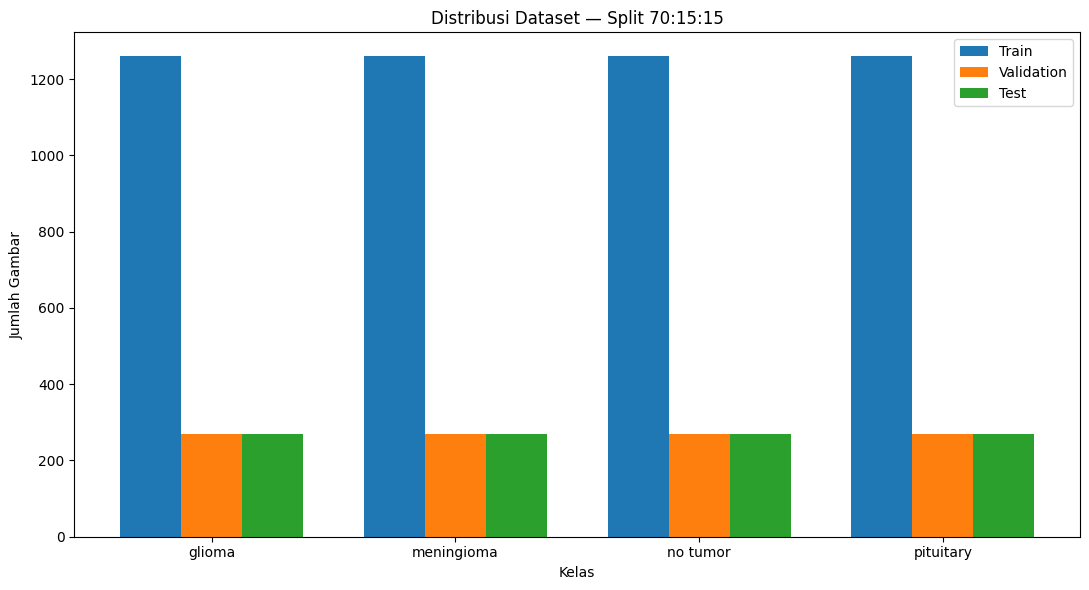


TRAINING SUDAH SELESAI
Experiment : S1_Split_70:15:15
Epoch      : 20/20

----------------------------------------------------------------------
EVALUASI TEST — 70:15:15
----------------------------------------------------------------------
Accuracy       : 0.9815
Precision Macro: 0.9816
Recall Macro   : 0.9815
F1 Macro       : 0.9815

✓ Hasil evaluasi tersimpan:
- /content/drive/MyDrive/Brain_Tumor_CNN/hasil/S1_Split_70_15_15_metrics.csv
- /content/drive/MyDrive/Brain_Tumor_CNN/hasil/S1_Split_70_15_15_confusion_matrix.csv
- /content/drive/MyDrive/Brain_Tumor_CNN/hasil/S1_Split_70_15_15_classification_report.csv


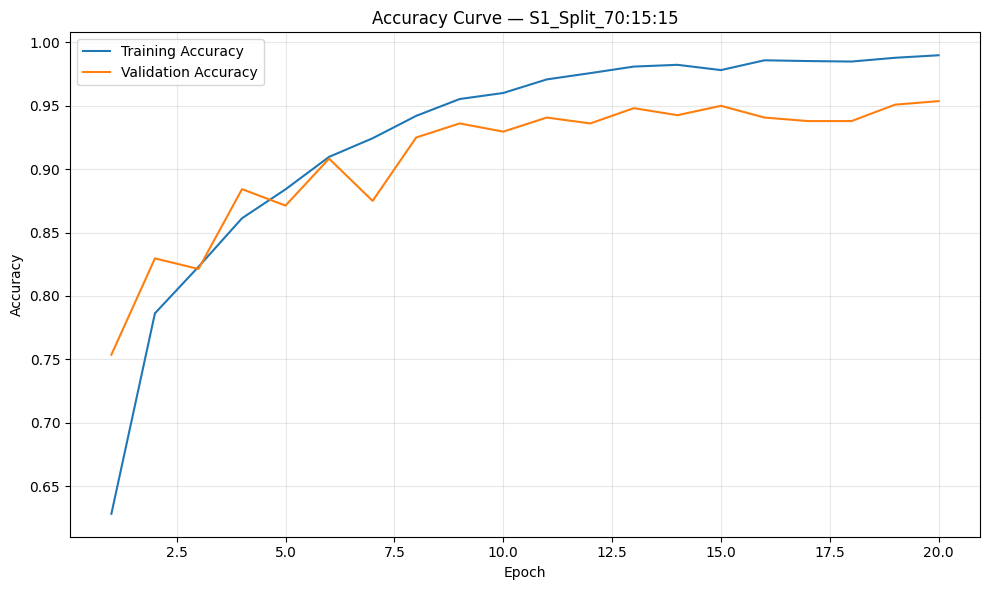

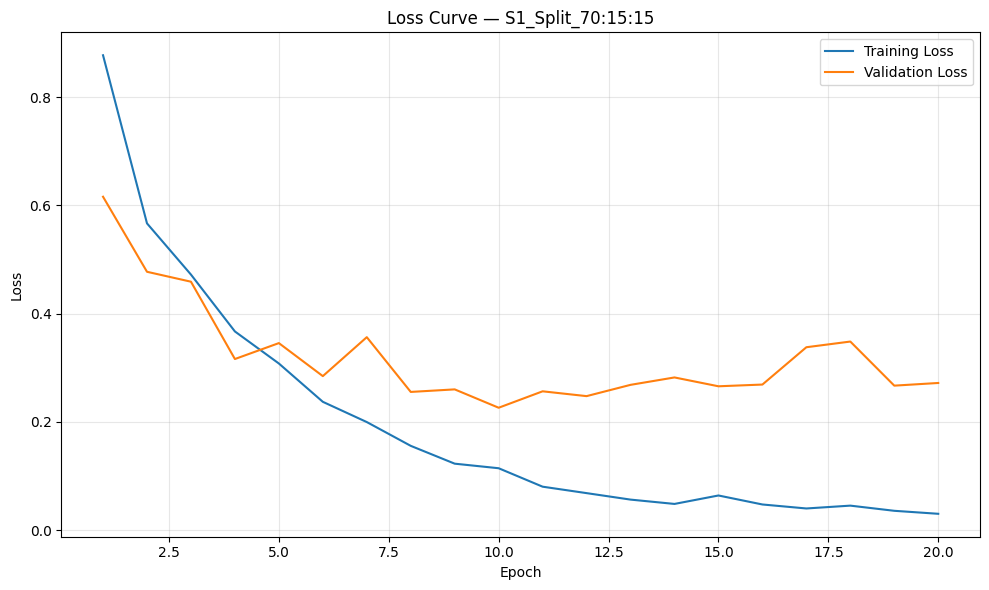

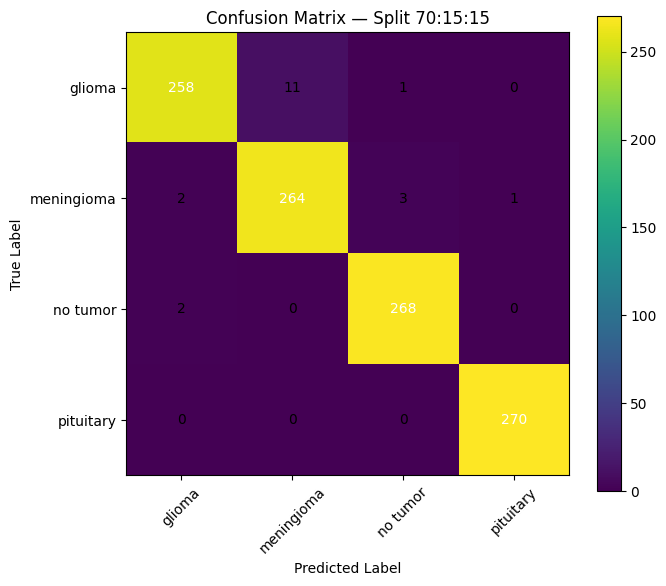


✓ Split 70:15:15 selesai.



######################################################################
SCENARIO 1 — SPLIT 80:10:10
######################################################################

Jumlah data:
Train      : 5760
Validation : 720
Test       : 720
Total      : 7200

Distribusi Train:


,Kelas,Jumlah,Persentase
0,glioma,1440,25.0
1,meningioma,1440,25.0
2,no tumor,1440,25.0
3,pituitary,1440,25.0


Distribusi Validation:


,Kelas,Jumlah,Persentase
0,glioma,180,25.0
1,meningioma,180,25.0
2,no tumor,180,25.0
3,pituitary,180,25.0


Distribusi Test:


,Kelas,Jumlah,Persentase
0,glioma,180,25.0
1,meningioma,180,25.0
2,no tumor,180,25.0
3,pituitary,180,25.0


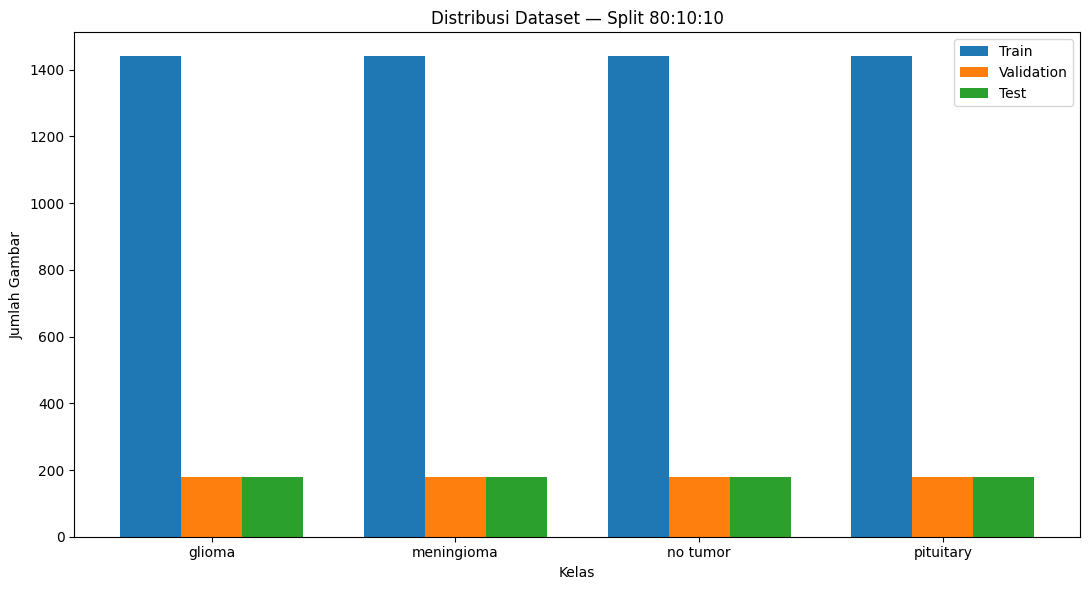


TRAINING SUDAH SELESAI
Experiment : S1_Split_80:10:10
Epoch      : 20/20

----------------------------------------------------------------------
EVALUASI TEST — 80:10:10
----------------------------------------------------------------------
Accuracy       : 0.9875
Precision Macro: 0.9879
Recall Macro   : 0.9875
F1 Macro       : 0.9876

✓ Hasil evaluasi tersimpan:
- /content/drive/MyDrive/Brain_Tumor_CNN/hasil/S1_Split_80_10_10_metrics.csv
- /content/drive/MyDrive/Brain_Tumor_CNN/hasil/S1_Split_80_10_10_confusion_matrix.csv
- /content/drive/MyDrive/Brain_Tumor_CNN/hasil/S1_Split_80_10_10_classification_report.csv


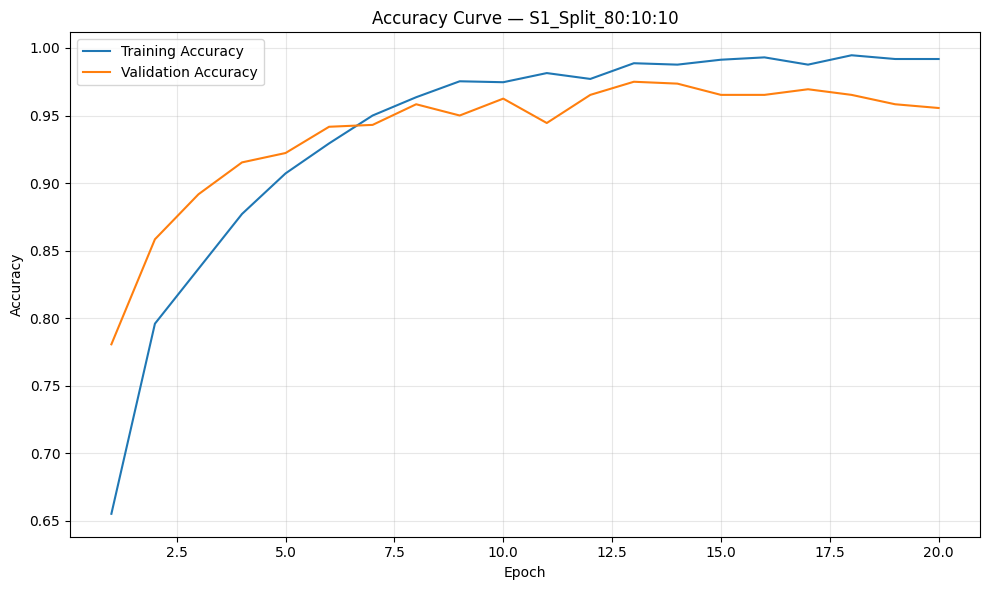

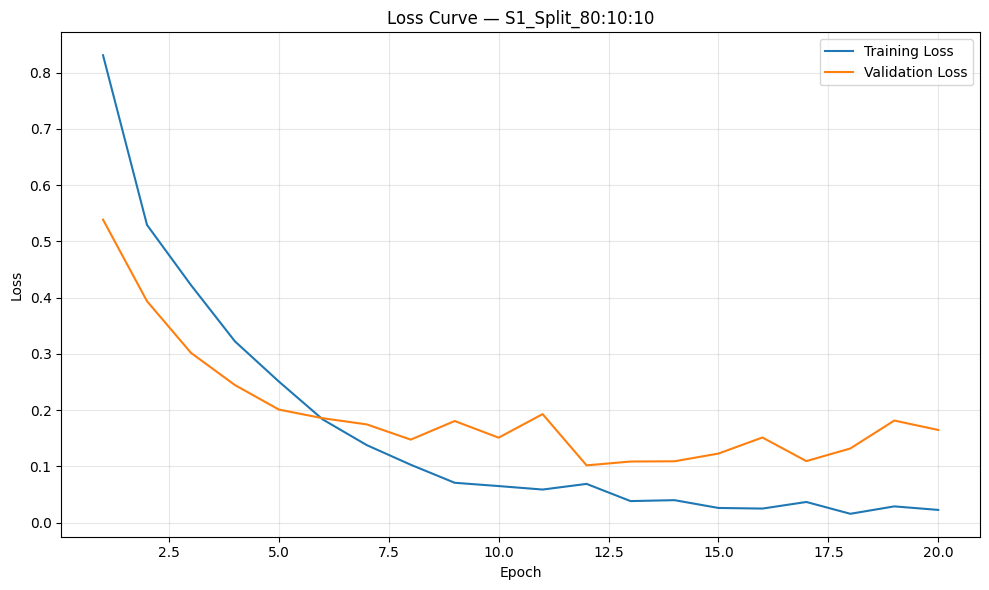

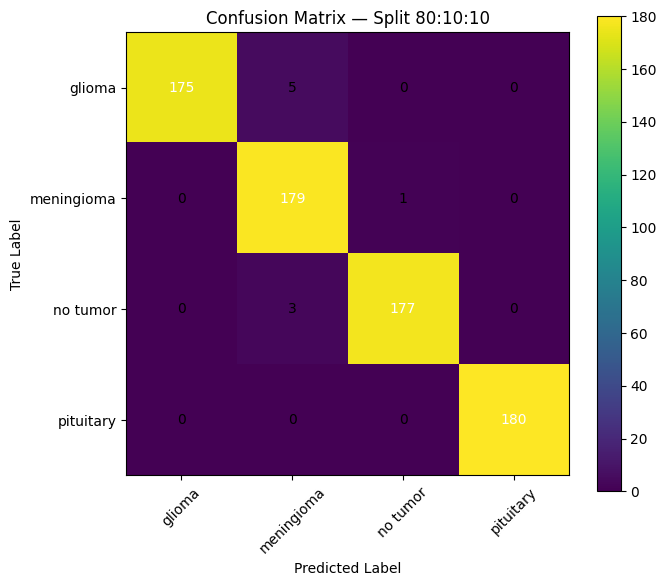


✓ Split 80:10:10 selesai.



######################################################################
SCENARIO 1 — SPLIT 90:05:05
######################################################################

Jumlah data:
Train      : 6480
Validation : 360
Test       : 360
Total      : 7200

Distribusi Train:


,Kelas,Jumlah,Persentase
0,glioma,1620,25.0
1,meningioma,1620,25.0
2,no tumor,1620,25.0
3,pituitary,1620,25.0


Distribusi Validation:


,Kelas,Jumlah,Persentase
0,glioma,90,25.0
1,meningioma,90,25.0
2,no tumor,90,25.0
3,pituitary,90,25.0


Distribusi Test:


,Kelas,Jumlah,Persentase
0,glioma,90,25.0
1,meningioma,90,25.0
2,no tumor,90,25.0
3,pituitary,90,25.0


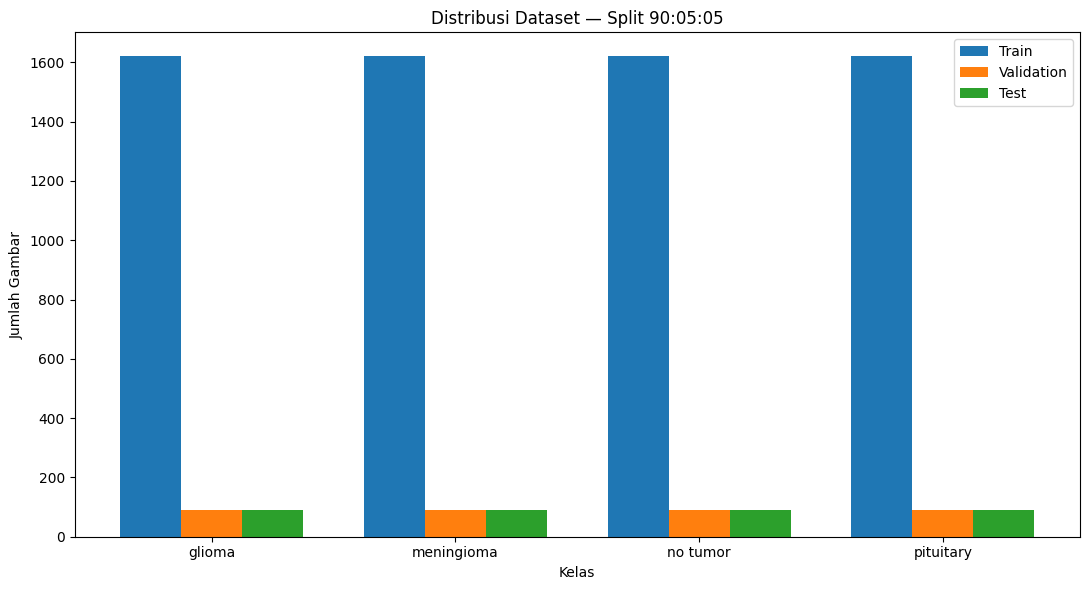


CHECKPOINT DITEMUKAN
Experiment       : S1_Split_90:05:05
Epoch terakhir   : 16/20
Melanjutkan dari : epoch 17
Epoch 17/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9809 - loss: 0.0665
✓ Checkpoint tersimpan — Epoch 17/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 339s 2s/step - accuracy: 0.9847 - loss: 0.0558 - val_accuracy: 0.9917 - val_loss: 0.0255
Epoch 18/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9795 - loss: 0.0571
✓ Checkpoint tersimpan — Epoch 18/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 339s 2s/step - accuracy: 0.9856 - loss: 0.0427 - val_accuracy: 0.9889 - val_loss: 0.0264
Epoch 19/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9880 - loss: 0.0330
✓ Checkpoint tersimpan — Epoch 19/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 382s 2s/step - accuracy: 0.9872 - loss: 0.0333 - val_accuracy: 0.9833 - val_loss: 0.0298
Epoch 20/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9905 - loss: 0.0301
✓ Checkpoint tersimpan — Epoch 20/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 387s 2s/step 

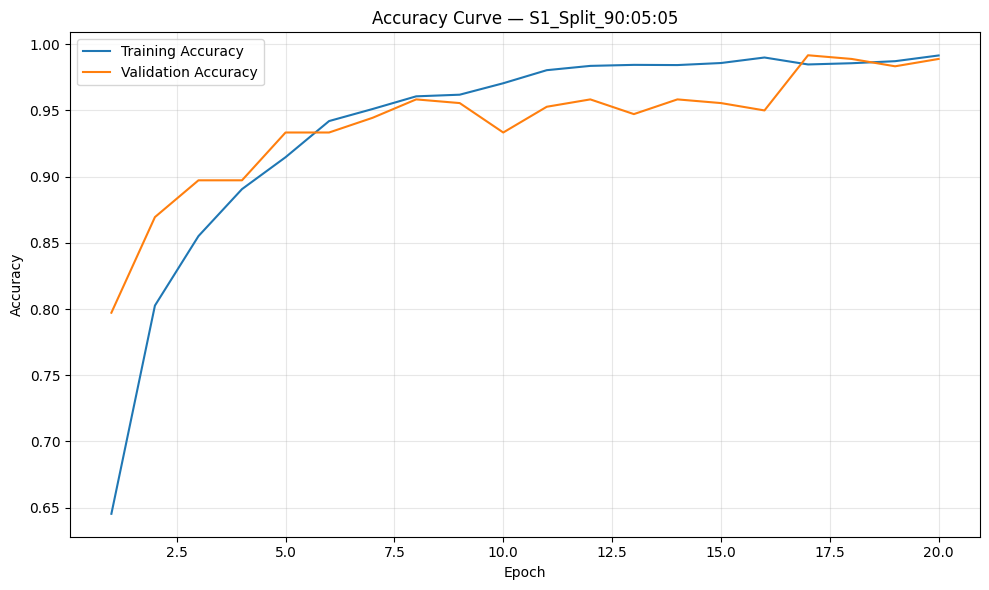

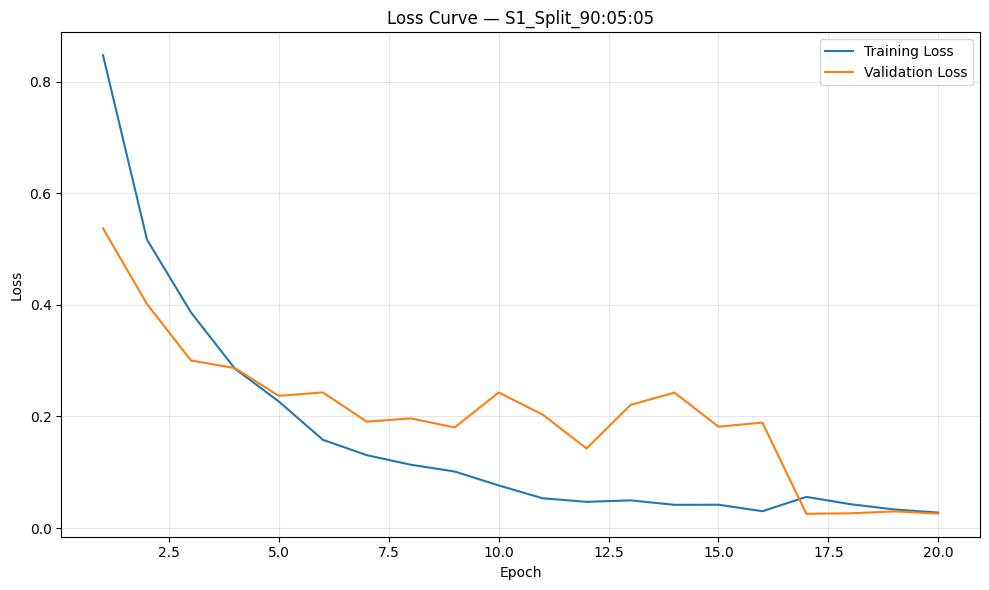

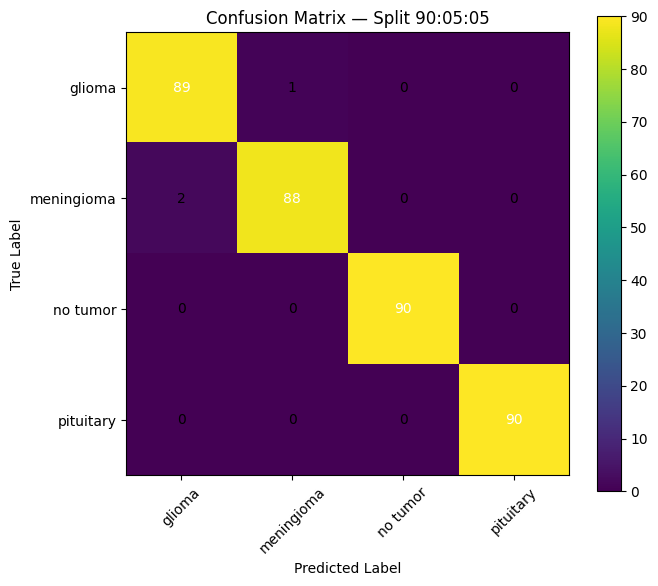


✓ Split 90:05:05 selesai.


HASIL SCENARIO 1 — OPTIMASI DATA SPLIT


,Scenario,Split,Train,Validation,Test,Jumlah Train,Jumlah Validation,Jumlah Test,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Scenario 1,70:15:15,0.7,0.15,0.15,5040,1080,1080,0.981481,0.981584,0.981481,0.981453
1,Scenario 1,80:10:10,0.8,0.10,0.10,5760,720,720,0.987500,0.987900,0.987500,0.987555
2,Scenario 1,90:05:05,0.9,0.05,0.05,6480,360,360,0.991667,0.991697,0.991667,0.991666



Tabel perbandingan:


,Split,Train,Validation,Test,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,70:15:15,0.7,0.15,0.15,0.9815,0.9816,0.9815,0.9815
1,80:10:10,0.8,0.10,0.10,0.9875,0.9879,0.9875,0.9876
2,90:05:05,0.9,0.05,0.05,0.9917,0.9917,0.9917,0.9917


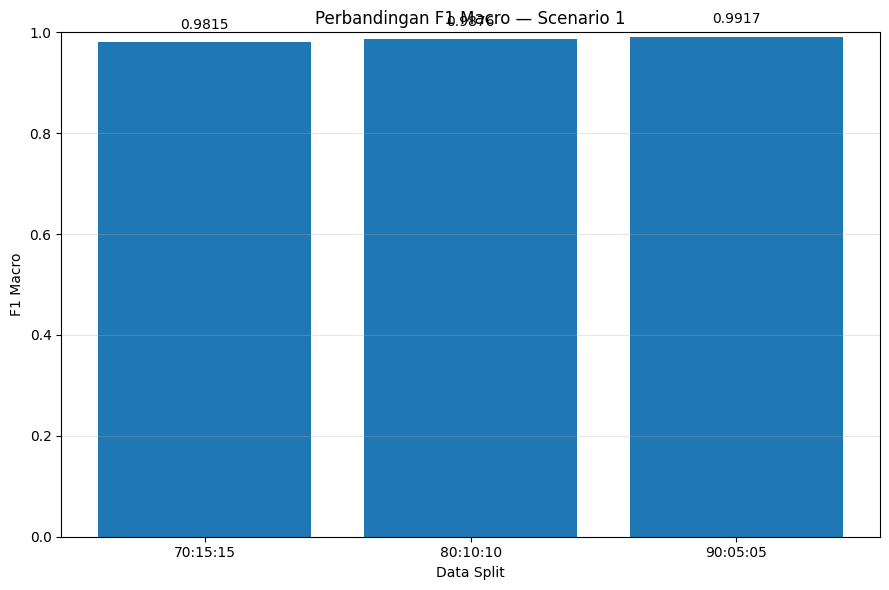


HASIL PEMILIHAN SCENARIO 1
BEST_SPLIT = 90:05:05
F1 Macro   = 0.9917

Split ini akan digunakan untuk Scenario 2.
✓ Hasil Scenario 1 masuk cache.

✓ Data split terbaik berhasil disimpan.

BAGIAN 7 SELESAI

Scenario 1:
70:15:15
80:10:10
90:05:05

Semua menggunakan:
- CNN baseline yang sama
- Dropout = 0.3
- Optimizer = Adam
- Learning rate = 0.0005
- Tanpa augmentation

Kriteria pemilihan:
F1 Macro tertinggi

BEST SPLIT:
90:05:05

Hasil tersebut akan digunakan pada:
SCENARIO 2 — OPTIMASI DATA AUGMENTATION



In [ ]:
# ============================================================
# BAGIAN 7
# SCENARIO 1 — OPTIMASI DATA SPLIT
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


# ============================================================
# 1. CEK DATA DAN FUNGSI
# ============================================================

print("=" * 70)
print("SCENARIO 1 — OPTIMASI DATA SPLIT")
print("=" * 70)

required_variables = [
    "X",
    "y",
    "class_names",
    "INPUT_SHAPE",
    "NUM_CLASSES",
    "EPOCHS",
    "BATCH_SIZE",
    "LEARNING_RATE",
    "CHECKPOINT_DIR",
    "RESULT_DIR",
    "GRAPH_DIR",
    "build_cnn_model",
    "create_tf_dataset",
    "train_with_resume",
    "evaluate_model",
    "save_evaluation_results"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if len(missing_variables) > 0:

    raise ValueError(
        "Variabel/fungsi berikut belum tersedia:\n"
        + ", ".join(missing_variables)
        + "\n\nPastikan Bagian 1–6 sudah dijalankan."
    )

print("✓ Semua komponen dari Bagian 1–6 tersedia.")


# ============================================================
# 2. PASTIKAN X DAN y VALID
# ============================================================

X = np.asarray(X)

if not isinstance(y, np.ndarray):

    y = np.asarray(
        y
    )

y = y.astype(
    np.int32
).reshape(-1)


if len(X) != len(y):

    raise ValueError(
        f"Jumlah X ({len(X)}) tidak sama "
        f"dengan jumlah y ({len(y)})."
    )


print("\nJumlah total gambar :", len(X))
print("Jumlah total label  :", len(y))

print(
    "Distribusi label:",
    dict(
        zip(
            class_names,
            np.bincount(
                y,
                minlength=NUM_CLASSES
            )
        )
    )
)


# ============================================================
# 3. KONFIGURASI SCENARIO 1
# ============================================================

SPLIT_SCENARIOS = {

    "70:15:15": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },

    "80:10:10": {
        "train": 0.80,
        "validation": 0.10,
        "test": 0.10
    },

    "90:05:05": {
        "train": 0.90,
        "validation": 0.05,
        "test": 0.05
    }
}


print("\n" + "=" * 70)
print("KONFIGURASI DATA SPLIT")
print("=" * 70)

split_config_df = pd.DataFrame(
    SPLIT_SCENARIOS
).T

display(
    split_config_df
)


# ============================================================
# 4. FUNGSI STRATIFIED SPLIT
# ============================================================

def create_stratified_split(
    X_data,
    y_data,
    train_ratio,
    validation_ratio,
    test_ratio,
    random_state=42
):
    """
    Membagi dataset menjadi train, validation, dan test.

    Stratified split digunakan agar proporsi setiap kelas
    tetap relatif terjaga pada masing-masing subset.
    """

    # --------------------------------------------------------
    # VALIDASI TOTAL
    # --------------------------------------------------------

    total_ratio = (
        train_ratio
        + validation_ratio
        + test_ratio
    )

    if not np.isclose(
        total_ratio,
        1.0
    ):

        raise ValueError(
            "Total rasio split harus = 1.0"
        )

    # --------------------------------------------------------
    # TRAIN VS TEMP
    # --------------------------------------------------------

    X_train, X_temp, y_train, y_temp = train_test_split(
        X_data,
        y_data,
        test_size=(
            validation_ratio
            + test_ratio
        ),
        stratify=y_data,
        random_state=random_state
    )

    # --------------------------------------------------------
    # VALIDATION VS TEST
    # --------------------------------------------------------

    test_relative_ratio = (
        test_ratio
        / (
            validation_ratio
            + test_ratio
        )
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=test_relative_ratio,
        stratify=y_temp,
        random_state=random_state
    )

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )


# ============================================================
# 5. FUNGSI DISTRIBUSI KELAS
# ============================================================

def get_class_distribution(
    labels,
    class_names
):

    counts = np.bincount(
        labels,
        minlength=len(class_names)
    )

    total = len(labels)

    result = []

    for index, class_name in enumerate(
        class_names
    ):

        percentage = (
            counts[index]
            / total
            * 100
        )

        result.append(
            {
                "Kelas": class_name,
                "Jumlah": int(
                    counts[index]
                ),
                "Persentase": round(
                    percentage,
                    2
                )
            }
        )

    return pd.DataFrame(
        result
    )


# ============================================================
# 6. FUNGSI PLOT DISTRIBUSI SPLIT
# ============================================================

def plot_split_distribution(
    y_train,
    y_val,
    y_test,
    scenario_name
):

    train_counts = np.bincount(
        y_train,
        minlength=NUM_CLASSES
    )

    val_counts = np.bincount(
        y_val,
        minlength=NUM_CLASSES
    )

    test_counts = np.bincount(
        y_test,
        minlength=NUM_CLASSES
    )

    x = np.arange(
        len(class_names)
    )

    width = 0.25

    plt.figure(
        figsize=(11, 6)
    )

    plt.bar(
        x - width,
        train_counts,
        width,
        label="Train"
    )

    plt.bar(
        x,
        val_counts,
        width,
        label="Validation"
    )

    plt.bar(
        x + width,
        test_counts,
        width,
        label="Test"
    )

    plt.xticks(
        x,
        class_names
    )

    plt.xlabel(
        "Kelas"
    )

    plt.ylabel(
        "Jumlah Gambar"
    )

    plt.title(
        f"Distribusi Dataset — Split {scenario_name}"
    )

    plt.legend()

    plt.tight_layout()

    filename = (
        f"distribusi_split_{scenario_name.replace(':', '_')}.png"
    )

    path = os.path.join(
        GRAPH_DIR,
        filename
    )

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    return path


# ============================================================
# 7. FUNGSI PLOT TRAINING CURVE
# ============================================================

def plot_training_history(
    history,
    experiment_name
):

    if not history:

        print(
            "⚠ History belum tersedia."
        )

        return None

    safe_name = (
        experiment_name
        .replace(" ", "_")
        .replace("/", "_")
        .replace(":", "_")
    )

    # --------------------------------------------------------
    # ACCURACY
    # --------------------------------------------------------

    if (
        "accuracy" in history
        and "val_accuracy" in history
    ):

        plt.figure(
            figsize=(10, 6)
        )

        epochs_range = range(
            1,
            len(
                history["accuracy"]
            ) + 1
        )

        plt.plot(
            epochs_range,
            history["accuracy"],
            label="Training Accuracy"
        )

        plt.plot(
            epochs_range,
            history["val_accuracy"],
            label="Validation Accuracy"
        )

        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Accuracy"
        )

        plt.title(
            f"Accuracy Curve — {experiment_name}"
        )

        plt.legend()

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        accuracy_path = os.path.join(
            GRAPH_DIR,
            f"{safe_name}_accuracy.png"
        )

        plt.savefig(
            accuracy_path,
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        plt.close()

    # --------------------------------------------------------
    # LOSS
    # --------------------------------------------------------

    if (
        "loss" in history
        and "val_loss" in history
    ):

        plt.figure(
            figsize=(10, 6)
        )

        epochs_range = range(
            1,
            len(
                history["loss"]
            ) + 1
        )

        plt.plot(
            epochs_range,
            history["loss"],
            label="Training Loss"
        )

        plt.plot(
            epochs_range,
            history["val_loss"],
            label="Validation Loss"
        )

        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Loss"
        )

        plt.title(
            f"Loss Curve — {experiment_name}"
        )

        plt.legend()

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        loss_path = os.path.join(
            GRAPH_DIR,
            f"{safe_name}_loss.png"
        )

        plt.savefig(
            loss_path,
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        plt.close()


# ============================================================
# 8. MENYIAPKAN HASIL
# ============================================================

scenario_results = []

scenario_data = {}


# ============================================================
# 9. LOOP 3 DATA SPLIT
# ============================================================

for scenario_name, config in SPLIT_SCENARIOS.items():

    print("\n\n")
    print("#" * 70)
    print(
        f"SCENARIO 1 — SPLIT {scenario_name}"
    )
    print("#" * 70)

    # --------------------------------------------------------
    # SPLIT DATA
    # --------------------------------------------------------

    (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    ) = create_stratified_split(

        X,
        y,

        train_ratio=config["train"],
        validation_ratio=config["validation"],
        test_ratio=config["test"],

        random_state=RANDOM_STATE
    )

    # --------------------------------------------------------
    # INFORMASI JUMLAH DATA
    # --------------------------------------------------------

    print("\nJumlah data:")

    print(
        f"Train      : {len(X_train)}"
    )

    print(
        f"Validation : {len(X_val)}"
    )

    print(
        f"Test       : {len(X_test)}"
    )

    print(
        f"Total      : "
        f"{len(X_train) + len(X_val) + len(X_test)}"
    )

    # --------------------------------------------------------
    # DISTRIBUSI KELAS
    # --------------------------------------------------------

    print("\nDistribusi Train:")

    display(
        get_class_distribution(
            y_train,
            class_names
        )
    )

    print("Distribusi Validation:")

    display(
        get_class_distribution(
            y_val,
            class_names
        )
    )

    print("Distribusi Test:")

    display(
        get_class_distribution(
            y_test,
            class_names
        )
    )

    # --------------------------------------------------------
    # PLOT DISTRIBUSI
    # --------------------------------------------------------

    plot_split_distribution(
        y_train,
        y_val,
        y_test,
        scenario_name
    )

    # --------------------------------------------------------
    # SIMPAN DATA SPLIT DALAM MEMORY
    # --------------------------------------------------------

    scenario_data[
        scenario_name
    ] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

    # --------------------------------------------------------
    # DATASET TENSORFLOW
    # --------------------------------------------------------

    train_dataset = create_tf_dataset(
        X_train,
        y_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        augmentation=False
    )

    val_dataset = create_tf_dataset(
        X_val,
        y_val,
        batch_size=BATCH_SIZE,
        shuffle=False,
        augmentation=False
    )

    test_dataset = create_tf_dataset(
        X_test,
        y_test,
        batch_size=BATCH_SIZE,
        shuffle=False,
        augmentation=False
    )

    # --------------------------------------------------------
    # NAMA EXPERIMENT
    # --------------------------------------------------------

    experiment_name = (
        f"S1_Split_{scenario_name}"
    )

    # --------------------------------------------------------
    # BUAT MODEL BARU
    # --------------------------------------------------------
    # Setiap split menggunakan model baru
    # agar eksperimen tidak saling memengaruhi.

    model = build_cnn_model(
        dropout_rate=0.3
    )

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------
    # Optimizer:
    # Adam
    #
    # Augmentation:
    # Tidak digunakan
    #
    # Dropout:
    # 0.3
    #
    # Semua kondisi dibuat sama selain split.

    model = train_with_resume(
        model=model,

        train_dataset=train_dataset,

        validation_dataset=val_dataset,

        experiment_name=experiment_name,

        optimizer_name="Adam",

        learning_rate=LEARNING_RATE,

        epochs=EPOCHS
    )

    # --------------------------------------------------------
    # EVALUASI TEST
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print(
        f"EVALUASI TEST — {scenario_name}"
    )
    print("-" * 70)

    evaluation = evaluate_model(
        model,
        test_dataset,
        class_names
    )

    metrics = evaluation[
        "metrics"
    ]

    # --------------------------------------------------------
    # TAMPILKAN METRIK
    # --------------------------------------------------------

    print(
        f"Accuracy       : "
        f"{metrics['Accuracy']:.4f}"
    )

    print(
        f"Precision Macro: "
        f"{metrics['Precision Macro']:.4f}"
    )

    print(
        f"Recall Macro   : "
        f"{metrics['Recall Macro']:.4f}"
    )

    print(
        f"F1 Macro       : "
        f"{metrics['F1 Macro']:.4f}"
    )

    # --------------------------------------------------------
    # SIMPAN HASIL
    # --------------------------------------------------------

    save_evaluation_results(
        evaluation,
        experiment_name
    )

    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------

    history = load_training_history(
        experiment_name
    )

    plot_training_history(
        history,
        experiment_name
    )

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    cm = evaluation[
        "confusion_matrix"
    ]

    plt.figure(
        figsize=(7, 6)
    )

    plt.imshow(
        cm
    )

    plt.title(
        f"Confusion Matrix — Split {scenario_name}"
    )

    plt.colorbar()

    plt.xticks(
        range(NUM_CLASSES),
        class_names,
        rotation=45
    )

    plt.yticks(
        range(NUM_CLASSES),
        class_names
    )

    plt.xlabel(
        "Predicted Label"
    )

    plt.ylabel(
        "True Label"
    )

    # --------------------------------------------------------
    # ANGKA DALAM CONFUSION MATRIX
    # --------------------------------------------------------

    threshold = cm.max() / 2

    for row in range(
        cm.shape[0]
    ):

        for col in range(
            cm.shape[1]
        ):

            plt.text(
                col,
                row,
                str(
                    cm[row, col]
                ),
                ha="center",
                va="center",
                color=(
                    "white"
                    if cm[row, col] > threshold
                    else "black"
                )
            )

    plt.tight_layout()

    cm_graph_path = os.path.join(
        GRAPH_DIR,
        f"confusion_matrix_{scenario_name.replace(':', '_')}.png"
    )

    plt.savefig(
        cm_graph_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    # --------------------------------------------------------
    # SIMPAN KE HASIL UTAMA
    # --------------------------------------------------------

    scenario_results.append(
        {
            "Scenario": "Scenario 1",
            "Split": scenario_name,
            "Train": config["train"],
            "Validation": config["validation"],
            "Test": config["test"],
            "Jumlah Train": len(X_train),
            "Jumlah Validation": len(X_val),
            "Jumlah Test": len(X_test),
            "Accuracy": metrics["Accuracy"],
            "Precision Macro": metrics["Precision Macro"],
            "Recall Macro": metrics["Recall Macro"],
            "F1 Macro": metrics["F1 Macro"]
        }
    )

    # --------------------------------------------------------
    # CLEAR MEMORY
    # --------------------------------------------------------

    del model
    del train_dataset
    del val_dataset
    del test_dataset

    tf.keras.backend.clear_session()

    print(
        f"\n✓ Split {scenario_name} selesai."
    )


# ============================================================
# 10. TABEL HASIL SCENARIO 1
# ============================================================

scenario1_results_df = pd.DataFrame(
    scenario_results
)

print("\n\n" + "=" * 70)
print("HASIL SCENARIO 1 — OPTIMASI DATA SPLIT")
print("=" * 70)

display(
    scenario1_results_df
)


# ============================================================
# 11. TABEL RINGKAS METRIK
# ============================================================

summary_columns = [
    "Split",
    "Train",
    "Validation",
    "Test",
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro"
]

summary_df = scenario1_results_df[
    summary_columns
].copy()

for column in [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro"
]:

    summary_df[column] = summary_df[
        column
    ].round(4)

print("\nTabel perbandingan:")

display(
    summary_df
)


# ============================================================
# 12. GRAFIK PERBANDINGAN F1 MACRO
# ============================================================

plt.figure(
    figsize=(9, 6)
)

bars = plt.bar(
    scenario1_results_df["Split"],
    scenario1_results_df["F1 Macro"]
)

plt.xlabel(
    "Data Split"
)

plt.ylabel(
    "F1 Macro"
)

plt.title(
    "Perbandingan F1 Macro — Scenario 1"
)

plt.ylim(
    0,
    1.0
)

# ------------------------------------------------------------
# ANGKA DI ATAS BAR
# ------------------------------------------------------------

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

f1_graph_path = os.path.join(
    GRAPH_DIR,
    "scenario_1_perbandingan_f1_macro.png"
)

plt.savefig(
    f1_graph_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 13. SIMPAN HASIL SCENARIO 1
# ============================================================

scenario1_csv_path = os.path.join(
    RESULT_DIR,
    "scenario_1_split_results.csv"
)

scenario1_results_df.to_csv(
    scenario1_csv_path,
    index=False
)


# ============================================================
# 14. MENENTUKAN BEST SPLIT
# ============================================================
# Kriteria:
# F1 Macro tertinggi.
#
# Tidak menggunakan Accuracy saja karena dataset klasifikasi
# memiliki beberapa kelas dan kita ingin melihat performa
# rata-rata antar kelas.

best_index = scenario1_results_df[
    "F1 Macro"
].idxmax()

BEST_SPLIT = scenario1_results_df.loc[
    best_index,
    "Split"
]

BEST_SPLIT_F1 = scenario1_results_df.loc[
    best_index,
    "F1 Macro"
]


# ============================================================
# 15. TAMPILKAN HASIL PEMILIHAN
# ============================================================

print("\n" + "=" * 70)
print("HASIL PEMILIHAN SCENARIO 1")
print("=" * 70)

print(
    f"BEST_SPLIT = {BEST_SPLIT}"
)

print(
    f"F1 Macro   = {BEST_SPLIT_F1:.4f}"
)

print(
    "\nSplit ini akan digunakan untuk Scenario 2."
)


# ============================================================
# 16. SIMPAN HASIL TERPILIH
# ============================================================

scenario1_selection = {

    "best_split": BEST_SPLIT,

    "best_f1_macro": float(
        BEST_SPLIT_F1
    ),

    "criterion": "F1 Macro tertinggi",

    "scenario": "Scenario 1"
}

selection_path = os.path.join(
    RESULT_DIR,
    "scenario_1_best_split.json"
)

with open(
    selection_path,
    "w"
) as file:

    json.dump(
        scenario1_selection,
        file,
        indent=4
    )


# ============================================================
# 17. CACHE
# ============================================================

try:

    cache = load_cache()

except:

    cache = {}


cache[
    "scenario_1_split_results"
] = scenario1_results_df.to_dict(
    orient="records"
)

cache[
    "best_split"
] = BEST_SPLIT

cache[
    "best_split_f1_macro"
] = float(
    BEST_SPLIT_F1
)


try:

    save_cache(
        cache
    )

    print(
        "✓ Hasil Scenario 1 masuk cache."
    )

except:

    print(
        "⚠ Cache tidak dapat diperbarui."
    )


# ============================================================
# 18. SIMPAN DATA SPLIT TERBAIK
# ============================================================
# Kita simpan indeks/data split terbaik agar Scenario 2
# tidak perlu melakukan split ulang.

best_split_data = scenario_data[
    BEST_SPLIT
]

np.save(
    os.path.join(
        CACHE_DIR,
        "X_train_best_split.npy"
    ),
    best_split_data["X_train"]
)

np.save(
    os.path.join(
        CACHE_DIR,
        "X_val_best_split.npy"
    ),
    best_split_data["X_val"]
)

np.save(
    os.path.join(
        CACHE_DIR,
        "X_test_best_split.npy"
    ),
    best_split_data["X_test"]
)

np.save(
    os.path.join(
        CACHE_DIR,
        "y_train_best_split.npy"
    ),
    best_split_data["y_train"]
)

np.save(
    os.path.join(
        CACHE_DIR,
        "y_val_best_split.npy"
    ),
    best_split_data["y_val"]
)

np.save(
    os.path.join(
        CACHE_DIR,
        "y_test_best_split.npy"
    ),
    best_split_data["y_test"]
)

print(
    "\n✓ Data split terbaik berhasil disimpan."
)


# ============================================================
# 19. SELESAI
# ============================================================

print("\n" + "=" * 70)
print("BAGIAN 7 SELESAI")
print("=" * 70)

print(
    f"""
Scenario 1:
70:15:15
80:10:10
90:05:05

Semua menggunakan:
- CNN baseline yang sama
- Dropout = 0.3
- Optimizer = Adam
- Learning rate = {LEARNING_RATE}
- Tanpa augmentation

Kriteria pemilihan:
F1 Macro tertinggi

BEST SPLIT:
{BEST_SPLIT}

Hasil tersebut akan digunakan pada:
SCENARIO 2 — OPTIMASI DATA AUGMENTATION
"""
)

SCENARIO 2 — OPTIMASI DATA AUGMENTATION
✓ Semua komponen dari Bagian 1–7 tersedia.

✓ BEST SPLIT dari Scenario 1: 90:05:05

DATA YANG DIGUNAKAN
Best Split : 90:05:05
Train      : 6480 gambar
Validation : 360 gambar
Test       : 360 gambar

KONFIGURASI SCENARIO 2


,Skenario,Augmentasi
0,Tanpa Augmentasi,Tidak
1,Dengan Augmentasi,Ya



Augmentasi yang digunakan:
1. Random Flip Horizontal
2. Random Rotation = 0.10
3. Random Zoom = 0.10

Catatan:
Augmentasi hanya diterapkan pada data TRAINING.
Validation dan Test TIDAK menggunakan augmentation.



######################################################################
SCENARIO 2 — TANPA AUGMENTASI
######################################################################

Experiment : S2_Augmentation_Tanpa_Augmentasi
Best Split: 90:05:05
Augmentasi: Tidak

MEMULAI TRAINING BARU
Experiment : S2_Augmentation_Tanpa_Augmentasi
Optimizer  : Adam
Epoch      : 20
Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5450 - loss: 1.0334
✓ Checkpoint tersimpan — Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 265s 1s/step - accuracy: 0.6622 - loss: 0.8297 - val_accuracy: 0.7639 - val_loss: 0.6030
Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7907 - loss: 0.5641
✓ Checkpoint tersimpan — Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 259s 1s/step - accuracy: 0.8011 - l

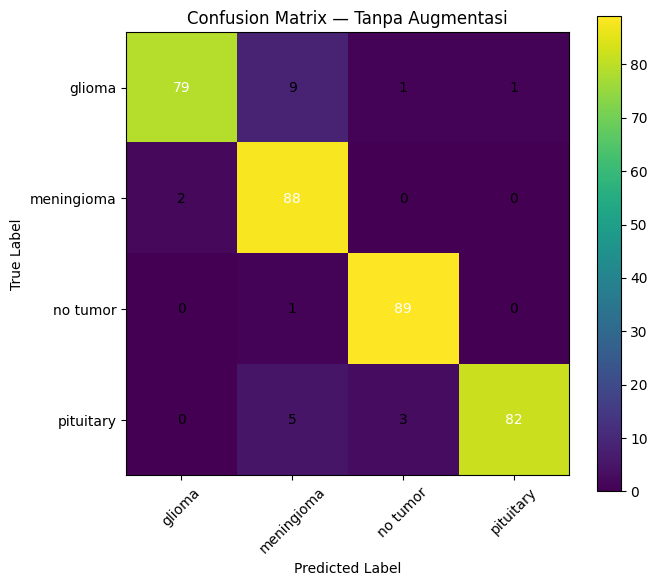

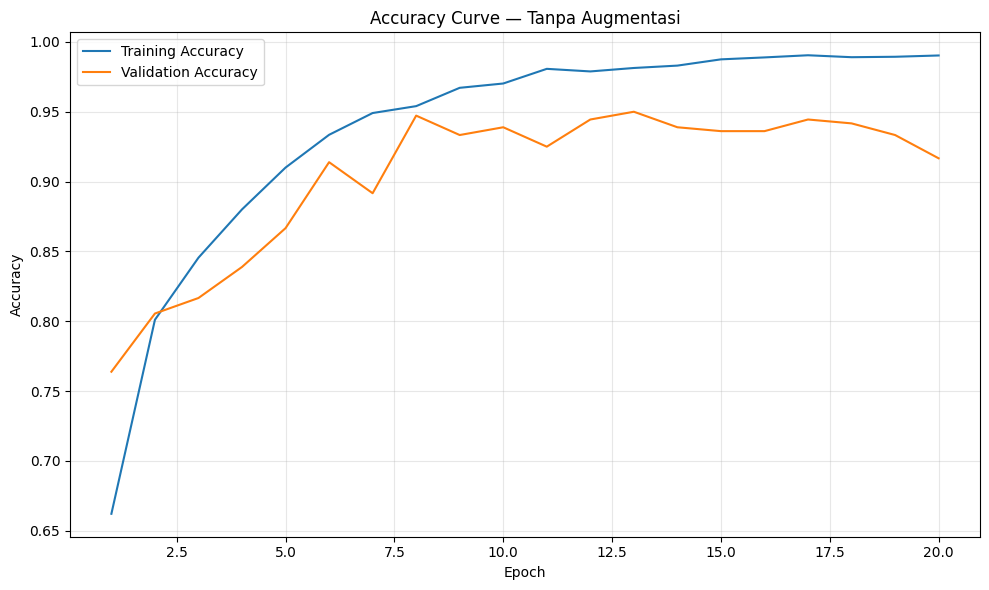

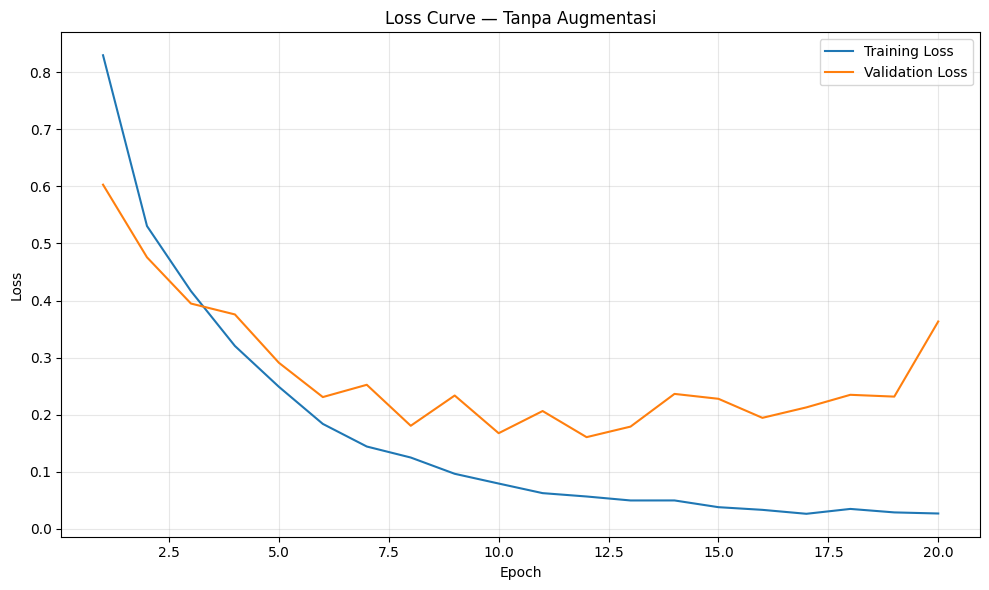


✓ Tanpa Augmentasi selesai.



######################################################################
SCENARIO 2 — DENGAN AUGMENTASI
######################################################################

Experiment : S2_Augmentation_Dengan_Augmentasi
Best Split: 90:05:05
Augmentasi: Ya

MEMULAI TRAINING BARU
Experiment : S2_Augmentation_Dengan_Augmentasi
Optimizer  : Adam
Epoch      : 20
Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5296 - loss: 1.0507
✓ Checkpoint tersimpan — Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 282s 1s/step - accuracy: 0.6313 - loss: 0.8828 - val_accuracy: 0.7556 - val_loss: 0.6427
Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7285 - loss: 0.6799
✓ Checkpoint tersimpan — Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 275s 1s/step - accuracy: 0.7451 - loss: 0.6527 - val_accuracy: 0.7778 - val_loss: 0.6036
Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7786 - loss: 0.5703
✓ Checkpoint tersimpan — Epoch 3/20
203/203 

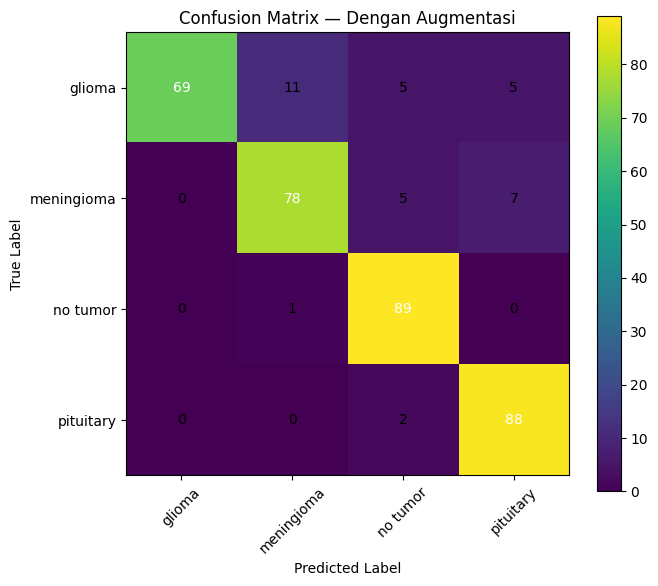

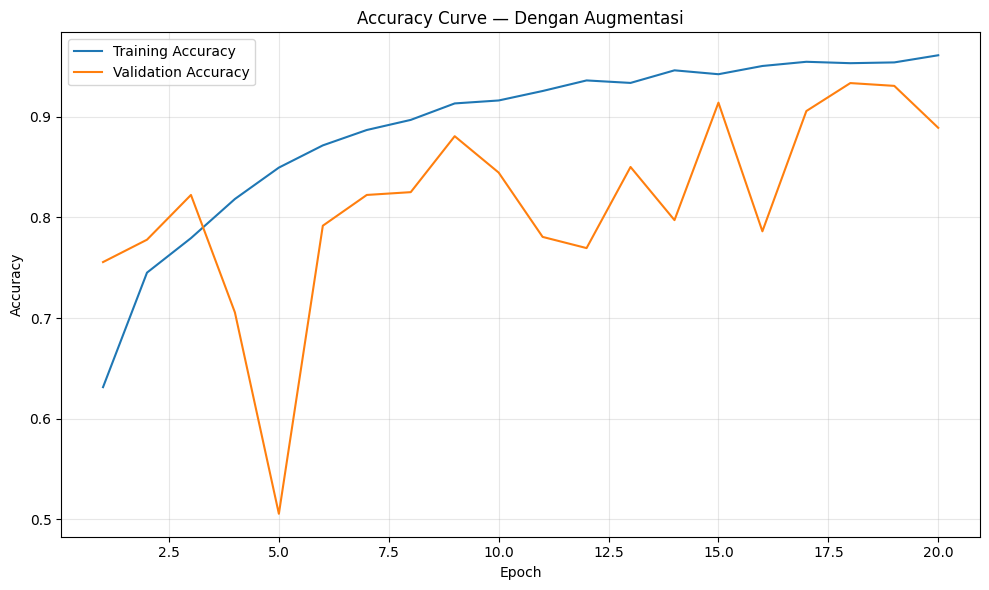

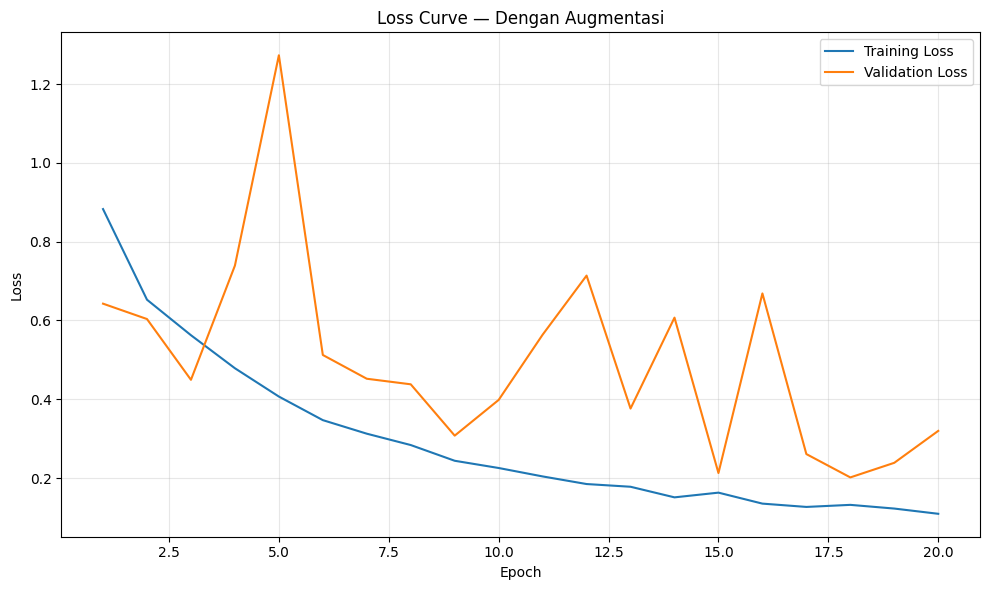


✓ Dengan Augmentasi selesai.


HASIL SCENARIO 2 — OPTIMASI DATA AUGMENTATION


,Scenario,Best Split,Augmentasi,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Scenario 2,90:05:05,Tanpa Augmentasi,0.938889,0.943655,0.938889,0.939137
1,Scenario 2,90:05:05,Dengan Augmentasi,0.900000,0.906964,0.900000,0.898211



Tabel perbandingan:


,Scenario,Best Split,Augmentasi,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Scenario 2,90:05:05,Tanpa Augmentasi,0.9389,0.9437,0.9389,0.9391
1,Scenario 2,90:05:05,Dengan Augmentasi,0.9000,0.9070,0.9000,0.8982


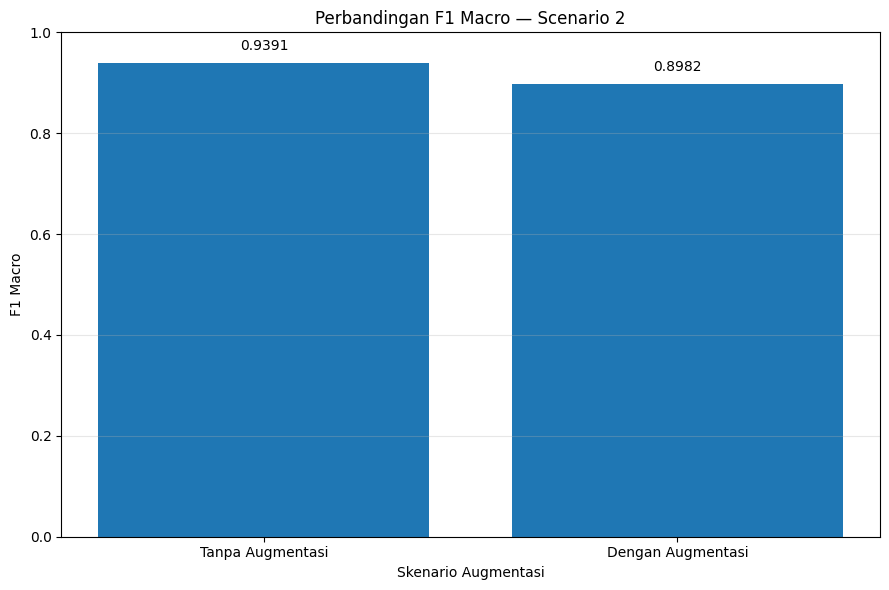


HASIL PEMILIHAN SCENARIO 2
BEST SPLIT        : 90:05:05
BEST AUGMENTATION : Tanpa Augmentasi
F1 Macro          : 0.9391

Konfigurasi tersebut akan digunakan untuk Scenario 3.

✓ Hasil Scenario 2 masuk cache.

BAGIAN 8 SELESAI

Scenario 2 telah membandingkan:

1. Tanpa Augmentasi
2. Dengan Augmentasi

Menggunakan BEST SPLIT:
90:05:05

Kondisi lainnya:
- CNN baseline
- Dropout = 0.3
- Optimizer = Adam
- Learning rate = 0.0005
- Epoch = 20

Kriteria pemilihan:
F1 Macro tertinggi

BEST AUGMENTATION:
Tanpa Augmentasi

F1 Macro:
0.9391

Konfigurasi ini akan digunakan untuk:
SCENARIO 3 — OPTIMASI OPTIMIZER



In [ ]:
# ============================================================
# BAGIAN 8
# SCENARIO 2 — OPTIMASI DATA AUGMENTATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


# ============================================================
# 1. CEK KOMPONEN DARI BAGIAN SEBELUMNYA
# ============================================================

print("=" * 70)
print("SCENARIO 2 — OPTIMASI DATA AUGMENTATION")
print("=" * 70)

required_variables = [
    "X",
    "y",
    "class_names",
    "INPUT_SHAPE",
    "NUM_CLASSES",
    "EPOCHS",
    "BATCH_SIZE",
    "LEARNING_RATE",
    "CHECKPOINT_DIR",
    "RESULT_DIR",
    "GRAPH_DIR",
    "CACHE_DIR",
    "build_cnn_model",
    "create_tf_dataset",
    "train_with_resume",
    "evaluate_model",
    "save_evaluation_results"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if len(missing_variables) > 0:

    raise ValueError(
        "Komponen berikut belum tersedia:\n"
        + ", ".join(missing_variables)
        + "\n\nPastikan Bagian 1–7 sudah dijalankan."
    )

print("✓ Semua komponen dari Bagian 1–7 tersedia.")


# ============================================================
# 2. MEMBACA BEST SPLIT DARI SCENARIO 1
# ============================================================

BEST_SPLIT = None

# ------------------------------------------------------------
# Coba ambil dari variabel hasil Bagian 7
# ------------------------------------------------------------

if "BEST_SPLIT" in globals():

    BEST_SPLIT = globals()["BEST_SPLIT"]


# ------------------------------------------------------------
# Jika variabel tidak ada, baca dari JSON
# ------------------------------------------------------------

if BEST_SPLIT is None:

    selection_path = os.path.join(
        RESULT_DIR,
        "scenario_1_best_split.json"
    )

    if os.path.exists(
        selection_path
    ):

        with open(
            selection_path,
            "r"
        ) as file:

            scenario1_selection = json.load(
                file
            )

        BEST_SPLIT = scenario1_selection[
            "best_split"
        ]


# ------------------------------------------------------------
# Jika tetap tidak ditemukan, hentikan
# ------------------------------------------------------------

if BEST_SPLIT is None:

    raise ValueError(
        "BEST_SPLIT dari Scenario 1 tidak ditemukan. "
        "Jalankan Bagian 7 terlebih dahulu."
    )


print(
    f"\n✓ BEST SPLIT dari Scenario 1: {BEST_SPLIT}"
)


# ============================================================
# 3. MEMUAT DATA SPLIT TERBAIK
# ============================================================

best_split_cache_files = {

    "X_train": "X_train_best_split.npy",

    "X_val": "X_val_best_split.npy",

    "X_test": "X_test_best_split.npy",

    "y_train": "y_train_best_split.npy",

    "y_val": "y_val_best_split.npy",

    "y_test": "y_test_best_split.npy"
}


best_split_data = {}

missing_cache_files = []


for key, filename in best_split_cache_files.items():

    filepath = os.path.join(
        CACHE_DIR,
        filename
    )

    if os.path.exists(
        filepath
    ):

        best_split_data[key] = np.load(
            filepath
        )

    else:

        missing_cache_files.append(
            filename
        )


# ============================================================
# 4. JIKA CACHE TIDAK ADA, BUAT ULANG SPLIT
# ============================================================

if len(missing_cache_files) > 0:

    print(
        "\n⚠ File split terbaik tidak lengkap."
    )

    print(
        "Mencoba mengambil data dari scenario_data..."
    )

    if (
        "scenario_data" in globals()
        and BEST_SPLIT in scenario_data
    ):

        best_split_data = scenario_data[
            BEST_SPLIT
        ]

    else:

        raise FileNotFoundError(
            "Data BEST_SPLIT tidak ditemukan. "
            "Jalankan kembali Bagian 7."
        )


# ============================================================
# 5. VALIDASI DATA
# ============================================================

X_train = np.asarray(
    best_split_data["X_train"]
)

X_val = np.asarray(
    best_split_data["X_val"]
)

X_test = np.asarray(
    best_split_data["X_test"]
)

y_train = np.asarray(
    best_split_data["y_train"]
).astype(np.int32)

y_val = np.asarray(
    best_split_data["y_val"]
).astype(np.int32)

y_test = np.asarray(
    best_split_data["y_test"]
).astype(np.int32)


print("\n" + "=" * 70)
print("DATA YANG DIGUNAKAN")
print("=" * 70)

print(
    f"Best Split : {BEST_SPLIT}"
)

print(
    f"Train      : {len(X_train)} gambar"
)

print(
    f"Validation : {len(X_val)} gambar"
)

print(
    f"Test       : {len(X_test)} gambar"
)


# ============================================================
# 6. KONFIGURASI SCENARIO 2
# ============================================================

AUGMENTATION_SCENARIOS = {

    "Tanpa Augmentasi": False,

    "Dengan Augmentasi": True
}


print("\n" + "=" * 70)
print("KONFIGURASI SCENARIO 2")
print("=" * 70)

augmentation_config_df = pd.DataFrame(
    [
        {
            "Skenario": "Tanpa Augmentasi",
            "Augmentasi": "Tidak"
        },
        {
            "Skenario": "Dengan Augmentasi",
            "Augmentasi": "Ya"
        }
    ]
)

display(
    augmentation_config_df
)


# ============================================================
# 7. INFORMASI AUGMENTATION
# ============================================================

print("\nAugmentasi yang digunakan:")

print(
    "1. Random Flip Horizontal"
)

print(
    "2. Random Rotation = 0.10"
)

print(
    "3. Random Zoom = 0.10"
)

print(
    "\nCatatan:"
)

print(
    "Augmentasi hanya diterapkan pada data TRAINING."
)

print(
    "Validation dan Test TIDAK menggunakan augmentation."
)


# ============================================================
# 8. HASIL EKSPERIMEN
# ============================================================

scenario2_results = []


# ============================================================
# 9. LOOP 2 SKENARIO
# ============================================================

for scenario_name, use_augmentation in AUGMENTATION_SCENARIOS.items():

    print("\n\n")

    print("#" * 70)

    print(
        f"SCENARIO 2 — {scenario_name.upper()}"
    )

    print("#" * 70)


    # --------------------------------------------------------
    # DATASET TRAIN
    # --------------------------------------------------------

    train_dataset = create_tf_dataset(

        X_train,

        y_train,

        batch_size=BATCH_SIZE,

        shuffle=True,

        augmentation=use_augmentation
    )


    # --------------------------------------------------------
    # DATASET VALIDATION
    # --------------------------------------------------------

    val_dataset = create_tf_dataset(

        X_val,

        y_val,

        batch_size=BATCH_SIZE,

        shuffle=False,

        augmentation=False
    )


    # --------------------------------------------------------
    # DATASET TEST
    # --------------------------------------------------------

    test_dataset = create_tf_dataset(

        X_test,

        y_test,

        batch_size=BATCH_SIZE,

        shuffle=False,

        augmentation=False
    )


    # --------------------------------------------------------
    # BUAT MODEL BARU
    # --------------------------------------------------------

    model = build_cnn_model(
        dropout_rate=0.3
    )


    # --------------------------------------------------------
    # NAMA EKSPERIMEN
    # --------------------------------------------------------

    experiment_name = (
        "S2_Augmentation_"
        + (
            "Tanpa_Augmentasi"
            if not use_augmentation
            else "Dengan_Augmentasi"
        )
    )


    print(
        f"\nExperiment : {experiment_name}"
    )

    print(
        f"Best Split: {BEST_SPLIT}"
    )

    print(
        f"Augmentasi: "
        f"{'Ya' if use_augmentation else 'Tidak'}"
    )


    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    model = train_with_resume(

        model=model,

        train_dataset=train_dataset,

        validation_dataset=val_dataset,

        experiment_name=experiment_name,

        optimizer_name="Adam",

        learning_rate=LEARNING_RATE,

        epochs=EPOCHS
    )


    # --------------------------------------------------------
    # EVALUASI
    # --------------------------------------------------------

    print("\n" + "-" * 70)

    print(
        f"EVALUASI TEST — {scenario_name}"
    )

    print("-" * 70)


    evaluation = evaluate_model(

        model,

        test_dataset,

        class_names
    )


    metrics = evaluation[
        "metrics"
    ]


    # --------------------------------------------------------
    # TAMPILKAN HASIL
    # --------------------------------------------------------

    print(
        f"Accuracy        : "
        f"{metrics['Accuracy']:.4f}"
    )

    print(
        f"Precision Macro : "
        f"{metrics['Precision Macro']:.4f}"
    )

    print(
        f"Recall Macro    : "
        f"{metrics['Recall Macro']:.4f}"
    )

    print(
        f"F1 Macro        : "
        f"{metrics['F1 Macro']:.4f}"
    )


    # --------------------------------------------------------
    # SIMPAN EVALUASI
    # --------------------------------------------------------

    save_evaluation_results(

        evaluation,

        experiment_name
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = evaluation[
        "confusion_matrix"
    ]


    plt.figure(
        figsize=(7, 6)
    )


    plt.imshow(
        cm
    )


    plt.title(
        f"Confusion Matrix — {scenario_name}"
    )


    plt.colorbar()


    plt.xticks(

        range(NUM_CLASSES),

        class_names,

        rotation=45
    )


    plt.yticks(

        range(NUM_CLASSES),

        class_names
    )


    plt.xlabel(
        "Predicted Label"
    )


    plt.ylabel(
        "True Label"
    )


    # --------------------------------------------------------
    # ANGKA CONFUSION MATRIX
    # --------------------------------------------------------

    threshold = cm.max() / 2


    for row in range(
        cm.shape[0]
    ):

        for col in range(
            cm.shape[1]
        ):

            plt.text(

                col,

                row,

                str(
                    cm[row, col]
                ),

                ha="center",

                va="center",

                color=(

                    "white"

                    if cm[row, col]
                    > threshold

                    else "black"
                )
            )


    plt.tight_layout()


    cm_graph_path = os.path.join(

        GRAPH_DIR,

        "scenario_2_"
        + scenario_name
        .replace(" ", "_")
        + "_confusion_matrix.png"
    )


    plt.savefig(

        cm_graph_path,

        dpi=200,

        bbox_inches="tight"
    )


    plt.show()


    plt.close()


    # ========================================================
    # TRAINING CURVE
    # ========================================================

    history = load_training_history(
        experiment_name
    )


    if history:

        # ----------------------------------------------------
        # ACCURACY
        # ----------------------------------------------------

        if (
            "accuracy" in history
            and "val_accuracy" in history
        ):

            plt.figure(
                figsize=(10, 6)
            )


            epochs_range = range(

                1,

                len(
                    history["accuracy"]
                ) + 1
            )


            plt.plot(

                epochs_range,

                history["accuracy"],

                label="Training Accuracy"
            )


            plt.plot(

                epochs_range,

                history["val_accuracy"],

                label="Validation Accuracy"
            )


            plt.xlabel(
                "Epoch"
            )


            plt.ylabel(
                "Accuracy"
            )


            plt.title(
                f"Accuracy Curve — {scenario_name}"
            )


            plt.legend()


            plt.grid(
                alpha=0.3
            )


            plt.tight_layout()


            accuracy_path = os.path.join(

                GRAPH_DIR,

                "scenario_2_"
                + scenario_name
                .replace(" ", "_")
                + "_accuracy.png"
            )


            plt.savefig(

                accuracy_path,

                dpi=200,

                bbox_inches="tight"
            )


            plt.show()


            plt.close()


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        if (
            "loss" in history
            and "val_loss" in history
        ):

            plt.figure(
                figsize=(10, 6)
            )


            epochs_range = range(

                1,

                len(
                    history["loss"]
                ) + 1
            )


            plt.plot(

                epochs_range,

                history["loss"],

                label="Training Loss"
            )


            plt.plot(

                epochs_range,

                history["val_loss"],

                label="Validation Loss"
            )


            plt.xlabel(
                "Epoch"
            )


            plt.ylabel(
                "Loss"
            )


            plt.title(
                f"Loss Curve — {scenario_name}"
            )


            plt.legend()


            plt.grid(
                alpha=0.3
            )


            plt.tight_layout()


            loss_path = os.path.join(

                GRAPH_DIR,

                "scenario_2_"
                + scenario_name
                .replace(" ", "_")
                + "_loss.png"
            )


            plt.savefig(

                loss_path,

                dpi=200,

                bbox_inches="tight"
            )


            plt.show()


            plt.close()


    # ========================================================
    # SIMPAN HASIL KE TABEL
    # ========================================================

    scenario2_results.append(

        {

            "Scenario": "Scenario 2",

            "Best Split": BEST_SPLIT,

            "Augmentasi": (
                "Dengan Augmentasi"
                if use_augmentation
                else "Tanpa Augmentasi"
            ),

            "Accuracy": metrics[
                "Accuracy"
            ],

            "Precision Macro": metrics[
                "Precision Macro"
            ],

            "Recall Macro": metrics[
                "Recall Macro"
            ],

            "F1 Macro": metrics[
                "F1 Macro"
            ]
        }
    )


    # ========================================================
    # BERSIHKAN MEMORY
    # ========================================================

    del model

    del train_dataset

    del val_dataset

    del test_dataset

    tf.keras.backend.clear_session()


    print(
        f"\n✓ {scenario_name} selesai."
    )


# ============================================================
# 10. TABEL HASIL SCENARIO 2
# ============================================================

scenario2_results_df = pd.DataFrame(
    scenario2_results
)


print("\n\n" + "=" * 70)

print(
    "HASIL SCENARIO 2 — OPTIMASI DATA AUGMENTATION"
)

print("=" * 70)


display(
    scenario2_results_df
)


# ============================================================
# 11. PEMBULATAN HASIL
# ============================================================

scenario2_summary_df = scenario2_results_df.copy()


for column in [

    "Accuracy",

    "Precision Macro",

    "Recall Macro",

    "F1 Macro"

]:

    scenario2_summary_df[
        column
    ] = scenario2_summary_df[
        column
    ].round(4)


print(
    "\nTabel perbandingan:"
)


display(
    scenario2_summary_df
)


# ============================================================
# 12. GRAFIK PERBANDINGAN F1 MACRO
# ============================================================

plt.figure(
    figsize=(9, 6)
)


bars = plt.bar(

    scenario2_results_df[
        "Augmentasi"
    ],

    scenario2_results_df[
        "F1 Macro"
    ]
)


plt.xlabel(
    "Skenario Augmentasi"
)


plt.ylabel(
    "F1 Macro"
)


plt.title(
    "Perbandingan F1 Macro — Scenario 2"
)


plt.ylim(
    0,
    1.0
)


# ------------------------------------------------------------
# LABEL NILAI
# ------------------------------------------------------------

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        height + 0.02,

        f"{height:.4f}",

        ha="center",

        va="bottom"
    )


plt.grid(

    axis="y",

    alpha=0.3
)


plt.tight_layout()


f1_graph_path = os.path.join(

    GRAPH_DIR,

    "scenario_2_perbandingan_f1_macro.png"
)


plt.savefig(

    f1_graph_path,

    dpi=200,

    bbox_inches="tight"
)


plt.show()


plt.close()


# ============================================================
# 13. MENENTUKAN BEST AUGMENTATION
# ============================================================

best_index = scenario2_results_df[
    "F1 Macro"
].idxmax()


BEST_AUGMENTATION = (
    scenario2_results_df.loc[
        best_index,
        "Augmentasi"
    ]
)


BEST_AUGMENTATION_F1 = (
    scenario2_results_df.loc[
        best_index,
        "F1 Macro"
    ]
)


# ============================================================
# 14. KONVERSI BEST AUGMENTATION KE BOOLEAN
# ============================================================

if BEST_AUGMENTATION == "Dengan Augmentasi":

    BEST_AUGMENTATION_BOOL = True

else:

    BEST_AUGMENTATION_BOOL = False


# ============================================================
# 15. TAMPILKAN HASIL PEMILIHAN
# ============================================================

print("\n" + "=" * 70)

print(
    "HASIL PEMILIHAN SCENARIO 2"
)

print("=" * 70)


print(
    f"BEST SPLIT        : {BEST_SPLIT}"
)


print(
    f"BEST AUGMENTATION : {BEST_AUGMENTATION}"
)


print(
    f"F1 Macro          : "
    f"{BEST_AUGMENTATION_F1:.4f}"
)


print(
    "\nKonfigurasi tersebut akan digunakan "
    "untuk Scenario 3."
)


# ============================================================
# 16. SIMPAN HASIL SCENARIO 2
# ============================================================

scenario2_csv_path = os.path.join(

    RESULT_DIR,

    "scenario_2_augmentation_results.csv"
)


scenario2_results_df.to_csv(

    scenario2_csv_path,

    index=False
)


# ============================================================
# 17. SIMPAN PEMILIHAN TERBAIK
# ============================================================

scenario2_selection = {

    "scenario": "Scenario 2",

    "best_split": BEST_SPLIT,

    "best_augmentation": BEST_AUGMENTATION,

    "best_augmentation_enabled": (
        BEST_AUGMENTATION_BOOL
    ),

    "best_f1_macro": float(
        BEST_AUGMENTATION_F1
    ),

    "criterion": "F1 Macro tertinggi"
}


scenario2_selection_path = os.path.join(

    RESULT_DIR,

    "scenario_2_best_augmentation.json"
)


with open(

    scenario2_selection_path,

    "w"

) as file:

    json.dump(

        scenario2_selection,

        file,

        indent=4
    )


# ============================================================
# 18. CACHE
# ============================================================

try:

    cache = load_cache()

except:

    cache = {}


cache[
    "scenario_2_augmentation_results"
] = scenario2_results_df.to_dict(
    orient="records"
)


cache[
    "best_augmentation"
] = BEST_AUGMENTATION


cache[
    "best_augmentation_enabled"
] = BEST_AUGMENTATION_BOOL


cache[
    "best_augmentation_f1_macro"
] = float(
    BEST_AUGMENTATION_F1
)


try:

    save_cache(
        cache
    )

    print(
        "\n✓ Hasil Scenario 2 masuk cache."
    )

except:

    print(
        "\n⚠ Cache tidak dapat diperbarui."
    )


# ============================================================
# 19. SELESAI
# ============================================================

print("\n" + "=" * 70)

print(
    "BAGIAN 8 SELESAI"
)

print("=" * 70)


print(
    f"""
Scenario 2 telah membandingkan:

1. Tanpa Augmentasi
2. Dengan Augmentasi

Menggunakan BEST SPLIT:
{BEST_SPLIT}

Kondisi lainnya:
- CNN baseline
- Dropout = 0.3
- Optimizer = Adam
- Learning rate = {LEARNING_RATE}
- Epoch = {EPOCHS}

Kriteria pemilihan:
F1 Macro tertinggi

BEST AUGMENTATION:
{BEST_AUGMENTATION}

F1 Macro:
{BEST_AUGMENTATION_F1:.4f}

Konfigurasi ini akan digunakan untuk:
SCENARIO 3 — OPTIMASI OPTIMIZER
"""
)

SCENARIO 3 — OPTIMASI OPTIMIZER
✓ Komponen Bagian 1–8 tersedia.
✓ Best Split : 90:05:05
✓ Best split dimuat dari cache.

Ukuran data:
Train      : (6480, 128, 128, 3)
Validation : (360, 128, 128, 3)
Test       : (360, 128, 128, 3)
✓ Best Augmentasi : Tanpa Augmentasi
✓ Dataset Scenario 3 siap.


SCENARIO 3 : Adam
→ Training Adam
Optimizer : Adam
Dropout   : 0.3
LR        : 0.0005

TRAINING SUDAH SELESAI
Experiment : S3_Optimizer_Adam
Epoch      : 20/20
✓ History ditemukan: /content/drive/MyDrive/Brain_Tumor_CNN/checkpoints/S3_Optimizer_Adam_history.json


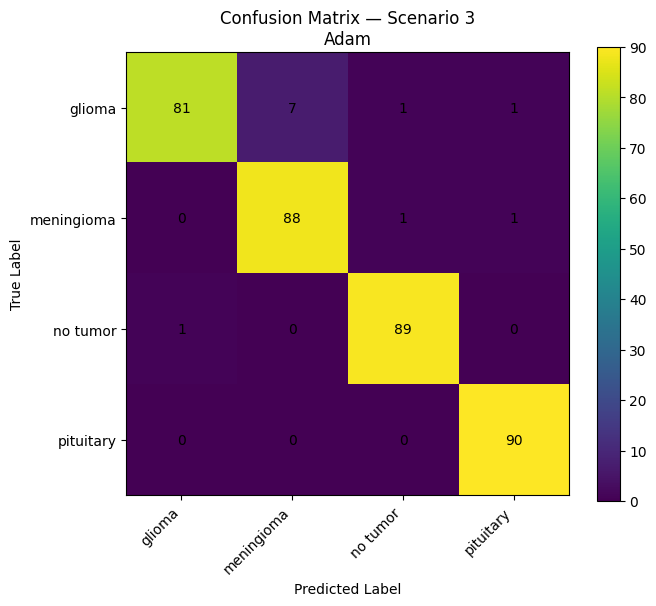


HASIL
Accuracy        : 0.9667
Precision Macro : 0.9676
Recall Macro    : 0.9667
F1 Macro        : 0.9664


SCENARIO 3 : RMSprop
→ Training RMSprop
Optimizer : RMSprop
Dropout   : 0.3
LR        : 0.0005

MEMULAI TRAINING BARU
Experiment : S3_Optimizer_RMSprop
Optimizer  : Adam
Epoch      : 20
Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5583 - loss: 1.0095
✓ Checkpoint tersimpan — Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 264s 1s/step - accuracy: 0.6681 - loss: 0.8065 - val_accuracy: 0.7833 - val_loss: 0.6040
Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8008 - loss: 0.5558
✓ Checkpoint tersimpan — Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 263s 1s/step - accuracy: 0.8071 - loss: 0.5296 - val_accuracy: 0.7944 - val_loss: 0.5376
Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8558 - loss: 0.4023
✓ Checkpoint tersimpan — Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 265s 1s/step - accuracy: 0.8597 - loss: 0.3894 - val_accuracy: 0.8278 - val_l

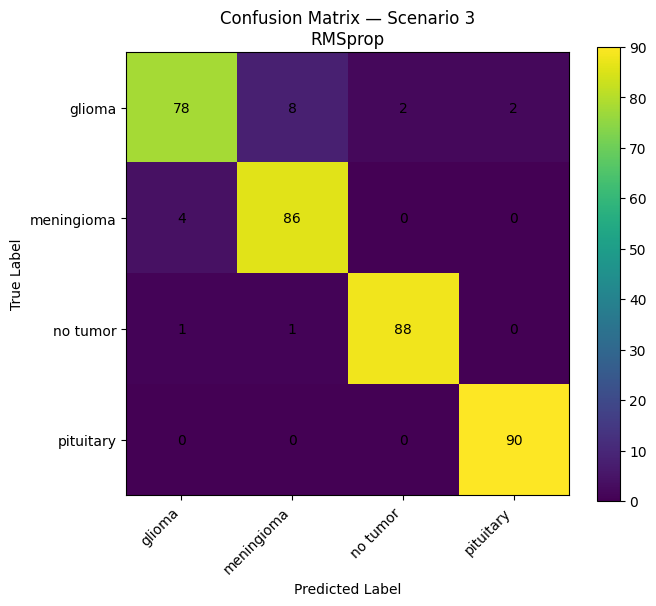


HASIL
Accuracy        : 0.9500
Precision Macro : 0.9503
Recall Macro    : 0.9500
F1 Macro        : 0.9496


SCENARIO 3 : SGD Momentum
→ Training SGD Momentum
Optimizer : SGD Momentum
Dropout   : 0.3
LR        : 0.0005

MEMULAI TRAINING BARU
Experiment : S3_Optimizer_SGD_Momentum
Optimizer  : Adam
Epoch      : 20
Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5198 - loss: 1.0276
✓ Checkpoint tersimpan — Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 274s 1s/step - accuracy: 0.6434 - loss: 0.8274 - val_accuracy: 0.7694 - val_loss: 0.6060
Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8014 - loss: 0.5392
✓ Checkpoint tersimpan — Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 270s 1s/step - accuracy: 0.8040 - loss: 0.5196 - val_accuracy: 0.8250 - val_loss: 0.4298
Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8514 - loss: 0.4107
✓ Checkpoint tersimpan — Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 268s 1s/step - accuracy: 0.8543 - loss: 0.3951 - val_accu

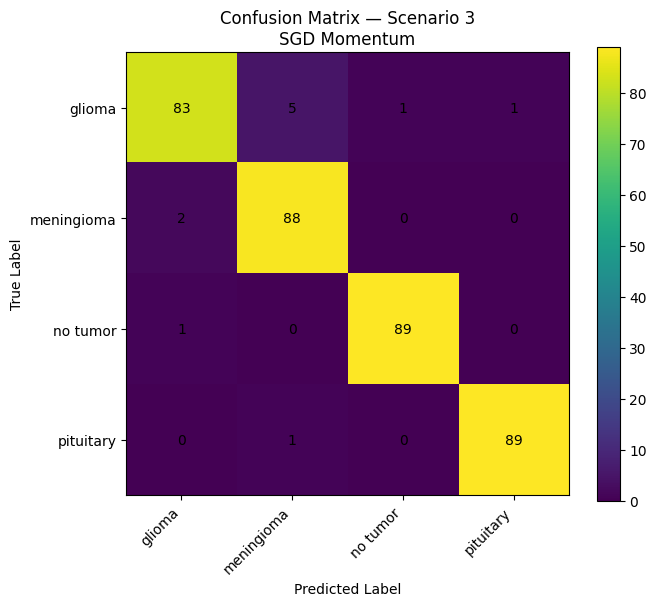


HASIL
Accuracy        : 0.9694
Precision Macro : 0.9698
Recall Macro    : 0.9694
F1 Macro        : 0.9694


HASIL SCENARIO 3 — OPTIMASI OPTIMIZER


,Optimizer,Learning Rate,Dropout,Split,Augmentasi,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,SGD Momentum,0.0005,0.300000,90:05:05,Tanpa Augmentasi,0.9694,0.9698,0.9694,0.9694
1,Adam,0.0005,0.300000,90:05:05,Tanpa Augmentasi,0.9667,0.9676,0.9667,0.9664
2,RMSprop,0.0005,0.300000,90:05:05,Tanpa Augmentasi,0.9500,0.9503,0.9500,0.9496




OPTIMIZER TERBAIK SCENARIO 3
Best Optimizer : SGD Momentum
Best F1 Macro  : 0.9694


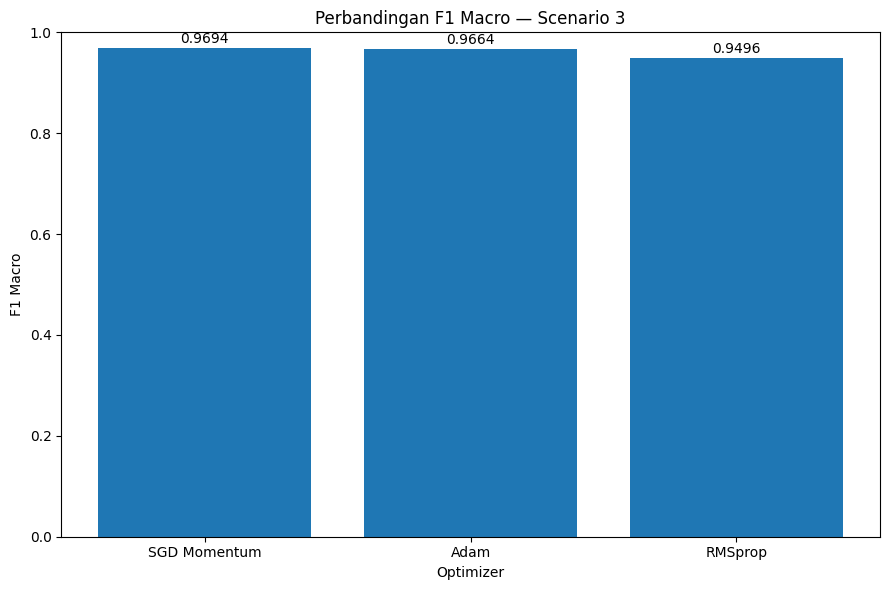

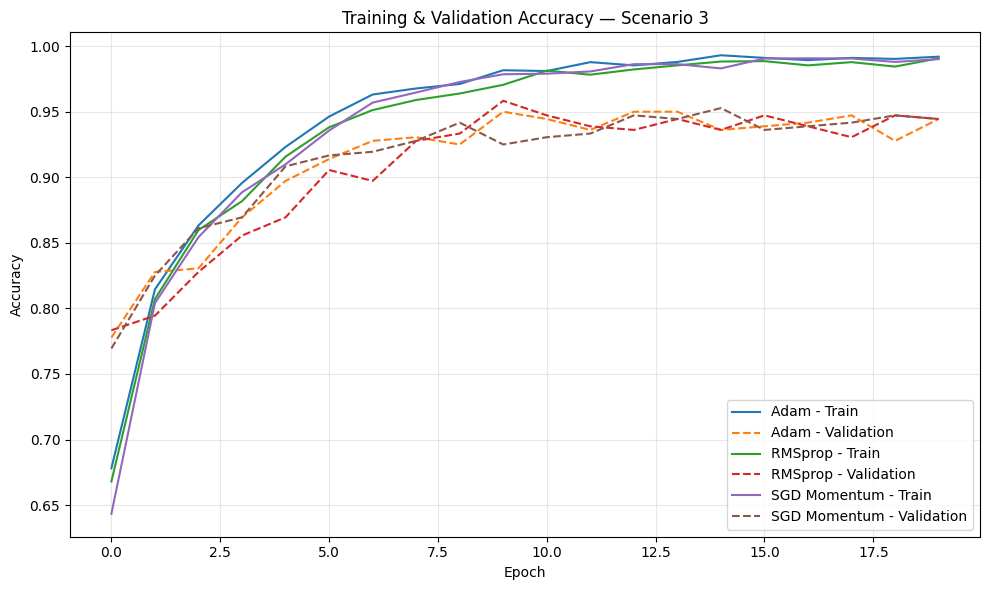

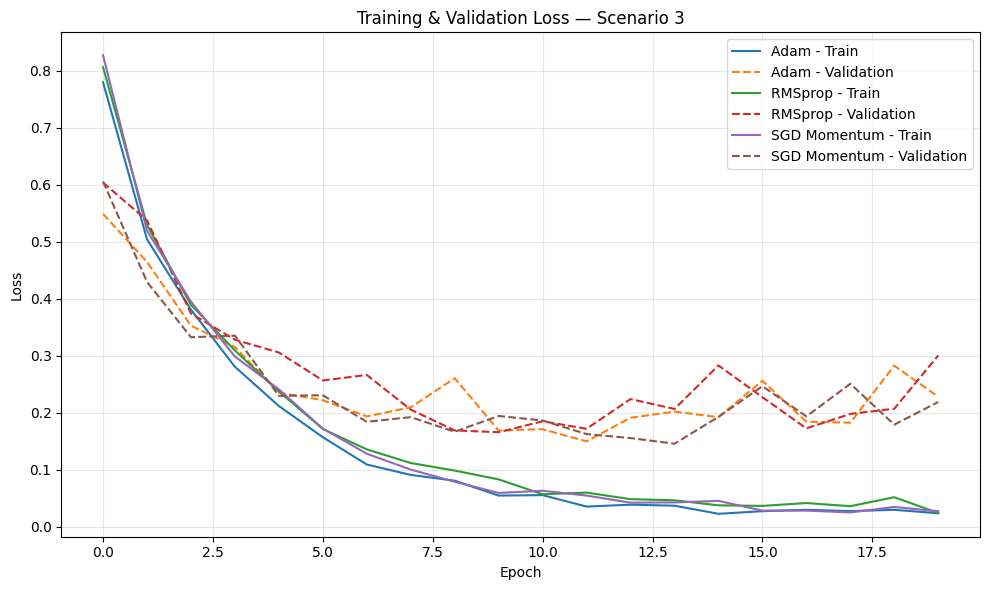



RINGKASAN SCENARIO 3
Scenario 1 → Best Split     : 90:05:05
Scenario 2 → Augmentasi     : Tanpa Augmentasi
Scenario 3 → Best Optimizer : SGD Momentum
Best F1 Macro               : 0.9694
Dropout                     : 0.3
Learning Rate               : 0.0005
Epoch                       : 20

✓ SCENARIO 3 SELESAI.
✓ Adam tidak diulang karena sudah 20/20.
✓ Adam dievaluasi ulang menggunakan evaluator yang kompatibel.
✓ RMSprop dan SGD Momentum akan dilatih.
✓ Best optimizer disimpan untuk Scenario 4.


In [ ]:
# ============================================================
# BAGIAN 9
# SCENARIO 3 — OPTIMASI OPTIMIZER

# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("=" * 70)
print("SCENARIO 3 — OPTIMASI OPTIMIZER")
print("=" * 70)


# ============================================================
# 1. VALIDASI KOMPONEN
# ============================================================

required_variables = [
    "X",
    "y",
    "IMAGE_SIZE",
    "INPUT_SHAPE",
    "NUM_CLASSES",
    "EPOCHS",
    "BATCH_SIZE",
    "LEARNING_RATE",
    "MODEL_DIR",
    "GRAPH_DIR",
    "RESULT_DIR",
    "CHECKPOINT_DIR",
    "CACHE_DIR",
    "class_names",
    "build_cnn_model",
    "create_tf_dataset",
    "train_with_resume",
    "evaluate_model"
]

missing_variables = [
    var for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Komponen berikut belum tersedia:\n"
        + "\n".join(missing_variables)
        + "\n\nJalankan Bagian 1 sampai Bagian 8."
    )

print("✓ Komponen Bagian 1–8 tersedia.")


# ============================================================
# 2. BEST SPLIT
# ============================================================

best_split_path = os.path.join(
    RESULT_DIR,
    "scenario_1_best_split.json"
)

if os.path.exists(best_split_path):

    with open(
        best_split_path,
        "r",
        encoding="utf-8"
    ) as f:

        split_info = json.load(f)

    BEST_SPLIT = split_info["best_split"]

elif "BEST_SPLIT" in globals():

    pass

else:

    raise FileNotFoundError(
        "Hasil Scenario 1 tidak ditemukan."
    )


print(
    f"✓ Best Split : {BEST_SPLIT}"
)


# ============================================================
# 3. LOAD BEST SPLIT
# ============================================================

split_cache_files = {

    "X_train": os.path.join(
        CACHE_DIR,
        "X_train_best_split.npy"
    ),

    "X_val": os.path.join(
        CACHE_DIR,
        "X_val_best_split.npy"
    ),

    "X_test": os.path.join(
        CACHE_DIR,
        "X_test_best_split.npy"
    ),

    "y_train": os.path.join(
        CACHE_DIR,
        "y_train_best_split.npy"
    ),

    "y_val": os.path.join(
        CACHE_DIR,
        "y_val_best_split.npy"
    ),

    "y_test": os.path.join(
        CACHE_DIR,
        "y_test_best_split.npy"
    )
}


if all(
    os.path.exists(path)
    for path in split_cache_files.values()
):

    X_train_best = np.load(
        split_cache_files["X_train"]
    )

    X_val_best = np.load(
        split_cache_files["X_val"]
    )

    X_test_best = np.load(
        split_cache_files["X_test"]
    )

    y_train_best = np.load(
        split_cache_files["y_train"]
    )

    y_val_best = np.load(
        split_cache_files["y_val"]
    )

    y_test_best = np.load(
        split_cache_files["y_test"]
    )

    print("✓ Best split dimuat dari cache.")

else:

    if "scenario_data" not in globals():

        raise FileNotFoundError(
            "Data best split tidak ditemukan."
        )

    best_data = scenario_data[BEST_SPLIT]

    X_train_best = best_data["X_train"]
    X_val_best = best_data["X_val"]
    X_test_best = best_data["X_test"]

    y_train_best = best_data["y_train"]
    y_val_best = best_data["y_val"]
    y_test_best = best_data["y_test"]

    print("✓ Best split dimuat dari memory.")


# ============================================================
# 4. RAPIIKAN DATA
# ============================================================

X_train_best = np.asarray(X_train_best)
X_val_best = np.asarray(X_val_best)
X_test_best = np.asarray(X_test_best)

y_train_best = np.asarray(
    y_train_best
).reshape(-1)

y_val_best = np.asarray(
    y_val_best
).reshape(-1)

y_test_best = np.asarray(
    y_test_best
).reshape(-1)


print("\nUkuran data:")
print(
    f"Train      : {X_train_best.shape}"
)

print(
    f"Validation : {X_val_best.shape}"
)

print(
    f"Test       : {X_test_best.shape}"
)


# ============================================================
# 5. BEST AUGMENTATION
# ============================================================

augmentation_path = os.path.join(
    RESULT_DIR,
    "scenario_2_best_augmentation.json"
)

if os.path.exists(augmentation_path):

    with open(
        augmentation_path,
        "r",
        encoding="utf-8"
    ) as f:

        augmentation_info = json.load(f)

    BEST_AUGMENTATION = (
        augmentation_info[
            "best_augmentation"
        ]
    )

elif "BEST_AUGMENTATION" in globals():

    pass

else:

    raise FileNotFoundError(
        "Hasil Scenario 2 tidak ditemukan."
    )


BEST_AUGMENTATION_BOOL = (
    BEST_AUGMENTATION ==
    "Dengan Augmentasi"
)


print(
    f"✓ Best Augmentasi : "
    f"{BEST_AUGMENTATION}"
)


# ============================================================
# 6. KONFIGURASI SCENARIO 3
# ============================================================

OPTIMIZER_SCENARIOS = {

    "Adam": {
        "learning_rate": LEARNING_RATE
    },

    "RMSprop": {
        "learning_rate": LEARNING_RATE
    },

    "SGD Momentum": {
        "learning_rate": LEARNING_RATE,
        "momentum": 0.9
    }
}


SCENARIO3_DROPOUT = 0.3


# ============================================================
# 7. TF.DATA
# ============================================================

train_ds_s3 = create_tf_dataset(
    X_train_best,
    y_train_best,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augmentation=BEST_AUGMENTATION_BOOL
)

val_ds_s3 = create_tf_dataset(
    X_val_best,
    y_val_best,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augmentation=False
)

test_ds_s3 = create_tf_dataset(
    X_test_best,
    y_test_best,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augmentation=False
)

print("✓ Dataset Scenario 3 siap.")


# ============================================================
# 8. OPTIMIZER
# ============================================================

def create_optimizer_scenario3(
    optimizer_name,
    learning_rate
):

    if optimizer_name == "Adam":

        return tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    elif optimizer_name == "RMSprop":

        return tf.keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    elif optimizer_name == "SGD Momentum":

        return tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    else:

        raise ValueError(
            f"Optimizer tidak dikenali: {optimizer_name}"
        )


# ============================================================
# 9. LOAD HISTORY
# ============================================================

def load_history_s3(experiment_name):

    history_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}_history.json"
    )

    if os.path.exists(history_path):

        with open(
            history_path,
            "r",
            encoding="utf-8"
        ) as f:

            history_data = json.load(f)

        print(
            f"✓ History ditemukan: "
            f"{history_path}"
        )

        return history_data

    print(
        f"⚠ History tidak ditemukan: "
        f"{experiment_name}"
    )

    return {}


# ============================================================
# 10. CARI CHECKPOINT
# ============================================================

def find_checkpoint_s3(experiment_name):

    possible_names = [

        f"{experiment_name}.keras",

        f"{experiment_name}_checkpoint.keras",

        f"{experiment_name}_best.keras"
    ]


    for filename in possible_names:

        path = os.path.join(
            CHECKPOINT_DIR,
            filename
        )

        if os.path.exists(path):

            return path


    if os.path.exists(CHECKPOINT_DIR):

        for filename in os.listdir(
            CHECKPOINT_DIR
        ):

            if (
                experiment_name.lower()
                in filename.lower()
                and
                filename.endswith(".keras")
            ):

                return os.path.join(
                    CHECKPOINT_DIR,
                    filename
                )


    return None


# ============================================================
# 11. CARI LAST EPOCH
# ============================================================

def get_last_epoch_s3(
    experiment_name
):

    state_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}_state.json"
    )


    if not os.path.exists(state_path):

        return 0


    try:

        with open(
            state_path,
            "r",
            encoding="utf-8"
        ) as f:

            state_info = json.load(f)

        return int(
            state_info.get(
                "last_epoch",
                0
            )
        )

    except Exception:

        return 0


# ============================================================
# 12. FUNGSI EVALUASI YANG LEBIH AMAN
# ============================================================

def evaluate_model_s3(
    model,
    test_dataset,
    class_names
):

    # --------------------------------------------------------
    # Prediksi
    # --------------------------------------------------------

    y_true = []
    y_pred = []


    for batch_x, batch_y in test_dataset:

        predictions = model.predict(
            batch_x,
            verbose=0
        )

        predicted_labels = np.argmax(
            predictions,
            axis=1
        )


        y_true.extend(
            batch_y.numpy().tolist()
        )

        y_pred.extend(
            predicted_labels.tolist()
        )


    y_true = np.asarray(
        y_true
    )

    y_pred = np.asarray(
        y_pred
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy_value = float(
        np.mean(
            y_true == y_pred
        )
    )


    precision_value = float(
        precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )


    recall_value = float(
        recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )


    f1_value = float(
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )


    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(class_names))
    )


    report = classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )


    return {

        "accuracy": accuracy_value,

        "precision_macro": precision_value,

        "recall_macro": recall_value,

        "f1_macro": f1_value,

        "confusion_matrix": cm,

        "classification_report": report
    }


# ============================================================
# 13. IMPORT METRIC
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 14. TRAIN / LOAD OPTIMIZER
# ============================================================

def run_optimizer_s3(
    optimizer_label
):

    safe_optimizer = (
        optimizer_label
        .replace(" ", "_")
        .replace("/", "_")
    )


    experiment_name = (
        f"S3_Optimizer_{safe_optimizer}"
    )


    print("\n")
    print("=" * 70)
    print(
        f"SCENARIO 3 : {optimizer_label}"
    )
    print("=" * 70)


    checkpoint_path = find_checkpoint_s3(
        experiment_name
    )


    last_epoch = get_last_epoch_s3(
        experiment_name
    )


    # --------------------------------------------------------
    # Kalau sudah selesai, LOAD
    # --------------------------------------------------------

    if (
        checkpoint_path is not None
        and
        last_epoch >= EPOCHS
    ):

        print(
            f"✓ {optimizer_label} sudah selesai "
            f"{last_epoch}/{EPOCHS}."
        )

        print(
            "✓ Tidak training ulang."
        )

        print(
            f"✓ Memuat checkpoint:\n"
            f"{checkpoint_path}"
        )


        model = tf.keras.models.load_model(
            checkpoint_path
        )


        history_data = load_history_s3(
            experiment_name
        )


        return (
            model,
            history_data
        )


    # --------------------------------------------------------
    # Kalau belum selesai → training
    # --------------------------------------------------------

    print(
        f"→ Training {optimizer_label}"
    )


    model = build_cnn_model(
        dropout_rate=SCENARIO3_DROPOUT
    )


    optimizer = create_optimizer_scenario3(
        optimizer_label,
        OPTIMIZER_SCENARIOS[
            optimizer_label
        ]["learning_rate"]
    )


    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )


    print(
        f"Optimizer : {optimizer_label}"
    )

    print(
        f"Dropout   : {SCENARIO3_DROPOUT}"
    )

    print(
        f"LR        : "
        f"{OPTIMIZER_SCENARIOS[optimizer_label]['learning_rate']}"
    )


    trained_model = train_with_resume(
        model=model,
        train_dataset=train_ds_s3,
        validation_dataset=val_ds_s3,
        experiment_name=experiment_name,
        epochs=EPOCHS
    )


    # train_with_resume hanya mengembalikan model

    if isinstance(
        trained_model,
        tuple
    ):

        model = trained_model[0]

    else:

        model = trained_model


    history_data = load_history_s3(
        experiment_name
    )


    return (
        model,
        history_data
    )


# ============================================================
# 15. JALANKAN SCENARIO 3
# ============================================================

scenario3_results = []

scenario3_histories = {}

scenario3_models = {}


for optimizer_label in OPTIMIZER_SCENARIOS.keys():

    model, history_data = run_optimizer_s3(
        optimizer_label
    )


    # --------------------------------------------------------
    # Evaluasi dengan evaluator kita sendiri
    # --------------------------------------------------------

    evaluation = evaluate_model_s3(
        model=model,
        test_dataset=test_ds_s3,
        class_names=class_names
    )


    accuracy_value = evaluation[
        "accuracy"
    ]

    precision_value = evaluation[
        "precision_macro"
    ]

    recall_value = evaluation[
        "recall_macro"
    ]

    f1_value = evaluation[
        "f1_macro"
    ]


    # --------------------------------------------------------
    # Simpan model
    # --------------------------------------------------------

    safe_optimizer = (
        optimizer_label
        .replace(" ", "_")
        .replace("/", "_")
    )


    model_path = os.path.join(
        MODEL_DIR,
        f"cnn_scenario3_{safe_optimizer}.keras"
    )


    model.save(
        model_path
    )


    # --------------------------------------------------------
    # Simpan memory
    # --------------------------------------------------------

    scenario3_models[
        optimizer_label
    ] = model


    scenario3_histories[
        optimizer_label
    ] = history_data


    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = evaluation[
        "confusion_matrix"
    ]


    plt.figure(
        figsize=(7, 6)
    )


    plt.imshow(cm)


    plt.title(
        f"Confusion Matrix — Scenario 3\n"
        f"{optimizer_label}"
    )


    plt.colorbar()


    plt.xticks(
        range(NUM_CLASSES),
        class_names,
        rotation=45,
        ha="right"
    )


    plt.yticks(
        range(NUM_CLASSES),
        class_names
    )


    plt.xlabel(
        "Predicted Label"
    )


    plt.ylabel(
        "True Label"
    )


    for i in range(NUM_CLASSES):

        for j in range(NUM_CLASSES):

            plt.text(
                j,
                i,
                int(cm[i, j]),
                ha="center",
                va="center"
            )


    plt.tight_layout()


    plt.savefig(
        os.path.join(
            GRAPH_DIR,
            f"confusion_matrix_scenario3_{safe_optimizer}.png"
        ),
        dpi=200,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    # --------------------------------------------------------
    # Classification Report
    # --------------------------------------------------------

    report_df = pd.DataFrame(
        evaluation[
            "classification_report"
        ]
    ).transpose()


    report_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"scenario3_{safe_optimizer}_classification_report.csv"
        )
    )


    # --------------------------------------------------------
    # Simpan JSON
    # --------------------------------------------------------

    evaluation_data = {

        "scenario":
            "Scenario 3",

        "optimizer":
            optimizer_label,

        "learning_rate":
            OPTIMIZER_SCENARIOS[
                optimizer_label
            ]["learning_rate"],

        "dropout":
            SCENARIO3_DROPOUT,

        "best_split":
            BEST_SPLIT,

        "augmentation":
            BEST_AUGMENTATION,

        "accuracy":
            accuracy_value,

        "precision_macro":
            precision_value,

        "recall_macro":
            recall_value,

        "f1_macro":
            f1_value
    }


    with open(
        os.path.join(
            RESULT_DIR,
            f"scenario3_{safe_optimizer}_evaluation.json"
        ),
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            evaluation_data,
            f,
            indent=4
        )


    # --------------------------------------------------------
    # Hasil sementara
    # --------------------------------------------------------

    scenario3_results.append({

        "Optimizer":
            optimizer_label,

        "Learning Rate":
            OPTIMIZER_SCENARIOS[
                optimizer_label
            ]["learning_rate"],

        "Dropout":
            SCENARIO3_DROPOUT,

        "Split":
            BEST_SPLIT,

        "Augmentasi":
            BEST_AUGMENTATION,

        "Accuracy":
            accuracy_value,

        "Precision Macro":
            precision_value,

        "Recall Macro":
            recall_value,

        "F1 Macro":
            f1_value
    })


    print("\nHASIL")

    print(
        f"Accuracy        : "
        f"{accuracy_value:.4f}"
    )

    print(
        f"Precision Macro : "
        f"{precision_value:.4f}"
    )

    print(
        f"Recall Macro    : "
        f"{recall_value:.4f}"
    )

    print(
        f"F1 Macro        : "
        f"{f1_value:.4f}"
    )


# ============================================================
# 16. TABEL HASIL
# ============================================================

scenario3_results_df = pd.DataFrame(
    scenario3_results
)


scenario3_results_df = (
    scenario3_results_df
    .sort_values(
        by="F1 Macro",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n")
print("=" * 70)
print(
    "HASIL SCENARIO 3 — OPTIMASI OPTIMIZER"
)
print("=" * 70)


display(
    scenario3_results_df.style.format({

        "Learning Rate":
            "{:.4f}",

        "Accuracy":
            "{:.4f}",

        "Precision Macro":
            "{:.4f}",

        "Recall Macro":
            "{:.4f}",

        "F1 Macro":
            "{:.4f}"
    })
)


# ============================================================
# 17. TENTUKAN BEST OPTIMIZER
# ============================================================

best_index = (
    scenario3_results_df[
        "F1 Macro"
    ].idxmax()
)


BEST_OPTIMIZER = (
    scenario3_results_df.loc[
        best_index,
        "Optimizer"
    ]
)


BEST_OPTIMIZER_F1 = float(
    scenario3_results_df.loc[
        best_index,
        "F1 Macro"
    ]
)


print("\n")
print("=" * 70)
print("OPTIMIZER TERBAIK SCENARIO 3")
print("=" * 70)


print(
    f"Best Optimizer : "
    f"{BEST_OPTIMIZER}"
)


print(
    f"Best F1 Macro  : "
    f"{BEST_OPTIMIZER_F1:.4f}"
)


# ============================================================
# 18. SIMPAN HASIL
# ============================================================

scenario3_results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "scenario_3_optimizer_results.csv"
    ),
    index=False
)


best_optimizer_info = {

    "scenario":
        "Scenario 3",

    "best_optimizer":
        BEST_OPTIMIZER,

    "best_f1_macro":
        BEST_OPTIMIZER_F1,

    "best_split":
        BEST_SPLIT,

    "augmentation":
        BEST_AUGMENTATION,

    "augmentation_enabled":
        BEST_AUGMENTATION_BOOL,

    "dropout":
        SCENARIO3_DROPOUT,

    "learning_rate":
        LEARNING_RATE,

    "epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "selection_metric":
        "F1 Macro"
}


with open(
    os.path.join(
        RESULT_DIR,
        "scenario_3_best_optimizer.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        best_optimizer_info,
        f,
        indent=4
    )


# ============================================================
# 19. GRAFIK F1
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.bar(
    scenario3_results_df[
        "Optimizer"
    ],
    scenario3_results_df[
        "F1 Macro"
    ]
)


plt.title(
    "Perbandingan F1 Macro — Scenario 3"
)


plt.xlabel(
    "Optimizer"
)


plt.ylabel(
    "F1 Macro"
)


max_f1 = max(
    scenario3_results_df[
        "F1 Macro"
    ]
)


plt.ylim(
    0,
    min(
        1.0,
        max_f1 + 0.10
    )
)


for i, value in enumerate(
    scenario3_results_df[
        "F1 Macro"
    ]
):

    plt.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )


plt.tight_layout()


plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "scenario_3_perbandingan_optimizer_f1.png"
    ),
    dpi=200,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 20. GRAFIK ACCURACY
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for optimizer_label, history_data in (
    scenario3_histories.items()
):

    if not isinstance(
        history_data,
        dict
    ):

        continue


    if (
        "accuracy" in history_data
        and
        "val_accuracy" in history_data
    ):

        plt.plot(
            history_data["accuracy"],
            label=f"{optimizer_label} - Train"
        )


        plt.plot(
            history_data["val_accuracy"],
            linestyle="--",
            label=f"{optimizer_label} - Validation"
        )


plt.title(
    "Training & Validation Accuracy — Scenario 3"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Accuracy"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.tight_layout()


plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "scenario_3_accuracy_all_optimizer.png"
    ),
    dpi=200,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 21. GRAFIK LOSS
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for optimizer_label, history_data in (
    scenario3_histories.items()
):

    if not isinstance(
        history_data,
        dict
    ):

        continue


    if (
        "loss" in history_data
        and
        "val_loss" in history_data
    ):

        plt.plot(
            history_data["loss"],
            label=f"{optimizer_label} - Train"
        )


        plt.plot(
            history_data["val_loss"],
            linestyle="--",
            label=f"{optimizer_label} - Validation"
        )


plt.title(
    "Training & Validation Loss — Scenario 3"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Loss"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.tight_layout()


plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "scenario_3_loss_all_optimizer.png"
    ),
    dpi=200,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 22. CACHE
# ============================================================

cache[
    "scenario_3_optimizer_results"
] = scenario3_results_df.to_dict(
    orient="records"
)


cache[
    "best_optimizer"
] = BEST_OPTIMIZER


cache[
    "best_optimizer_f1_macro"
] = BEST_OPTIMIZER_F1


cache[
    "scenario_3_best_config"
] = best_optimizer_info


save_cache(
    cache
)


# ============================================================
# 23. RINGKASAN
# ============================================================

print("\n")
print("=" * 70)
print("RINGKASAN SCENARIO 3")
print("=" * 70)


print(
    f"Scenario 1 → Best Split     : "
    f"{BEST_SPLIT}"
)


print(
    f"Scenario 2 → Augmentasi     : "
    f"{BEST_AUGMENTATION}"
)


print(
    f"Scenario 3 → Best Optimizer : "
    f"{BEST_OPTIMIZER}"
)


print(
    f"Best F1 Macro               : "
    f"{BEST_OPTIMIZER_F1:.4f}"
)


print(
    f"Dropout                     : "
    f"{SCENARIO3_DROPOUT}"
)


print(
    f"Learning Rate               : "
    f"{LEARNING_RATE}"
)


print(
    f"Epoch                       : "
    f"{EPOCHS}"
)


print("\n✓ SCENARIO 3 SELESAI.")
print("✓ Adam tidak diulang karena sudah 20/20.")
print("✓ Adam dievaluasi ulang menggunakan evaluator yang kompatibel.")
print("✓ RMSprop dan SGD Momentum akan dilatih.")
print("✓ Best optimizer disimpan untuk Scenario 4.")

print("=" * 70)

PERBAIKAN RESUME SCENARIO 4
✓ Best Split      : 90:05:05
✓ Augmentasi      : Tanpa Augmentasi
✓ Optimizer       : SGD Momentum
✓ Train: (6480, 128, 128, 3)
✓ Val  : (360, 128, 128, 3)
✓ Test : (360, 128, 128, 3)

SCENARIO 4 — Dropout 0.0
Dropout    : 0.0
Optimizer  : SGD Momentum
Augmentasi : Tanpa Augmentasi
Epoch      : 20
✓ Training baru: S4_Dropout_Dropout_0_0
Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 836ms/step - accuracy: 0.2818 - loss: 1.3499✓ Checkpoint disimpan Epoch 1/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 173s 850ms/step - accuracy: 0.3492 - loss: 1.3030 - val_accuracy: 0.5556 - val_loss: 1.1929
Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 810ms/step - accuracy: 0.5840 - loss: 1.0851✓ Checkpoint disimpan Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 167s 823ms/step - accuracy: 0.6114 - loss: 1.0151 - val_accuracy: 0.6583 - val_loss: 0.9161
Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 797ms/step - accuracy: 0.6696 - loss: 0.8622✓ Checkpoint disimpan Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 19

,Dropout,Dropout Rate,Optimizer,Augmentasi,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Dropout 0.0,0.0,SGD Momentum,Tanpa Augmentasi,0.875000,0.886486,0.875000,0.871160
1,Dropout 0.3,0.3,SGD Momentum,Tanpa Augmentasi,0.905556,0.906956,0.905556,0.904793
2,Dropout 0.5,0.5,SGD Momentum,Tanpa Augmentasi,0.883333,0.892202,0.883333,0.879607



DROPOUT TERBAIK
✓ Dropout terbaik : Dropout 0.3
✓ Rate            : 0.3
✓ F1 Macro        : 0.9048


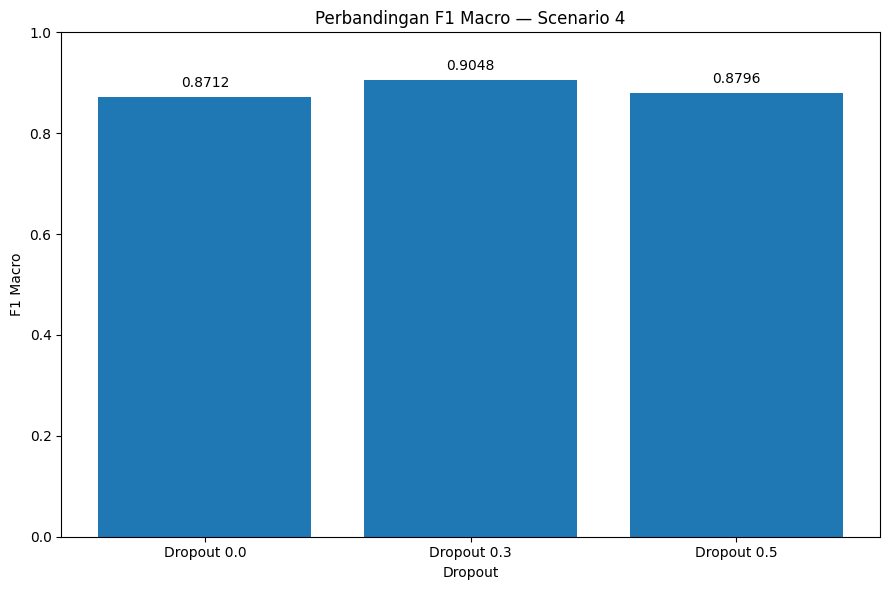


CHAMPION FINAL
Scenario 1 — Split      : 90:05:05
Scenario 2 — Augmentasi : Tanpa Augmentasi
Scenario 3 — Optimizer  : SGD Momentum
Scenario 4 — Dropout    : Dropout 0.3
Dropout Rate             : 0.3
F1 Macro                 : 0.9048
Model                    : /content/drive/MyDrive/Brain_Tumor_CNN/models/cnn_champion_final.keras
✓ SCENARIO 4 SELESAI.


In [ ]:
# ============================================================
# PERBAIKAN SCENARIO 4
# Membuat train_with_resume() kembali tersedia
# lalu melanjutkan Dropout 0.3 dan 0.5
# ============================================================

import os
import json
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("PERBAIKAN RESUME SCENARIO 4")
print("=" * 70)


# ============================================================
# 1. PASTIKAN PATH
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models"
)

GRAPH_DIR = os.path.join(
    BASE_DIR,
    "grafik"
)

CACHE_DIR = os.path.join(
    BASE_DIR,
    "cache"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "hasil"
)

CHECKPOINT_DIR = os.path.join(
    BASE_DIR,
    "checkpoints"
)

for folder in [
    MODEL_DIR,
    GRAPH_DIR,
    CACHE_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )


# ============================================================
# 2. KONFIGURASI
# ============================================================

IMAGE_SIZE = (128, 128)

INPUT_SHAPE = (
    128,
    128,
    3
)

NUM_CLASSES = 4

class_names = [
    "glioma",
    "meningioma",
    "no tumor",
    "pituitary"
]

RANDOM_STATE = 42

EPOCHS = 20

BATCH_SIZE = 32

LEARNING_RATE = 0.0005


# ============================================================
# 3. LOAD HASIL SCENARIO 1–3
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "scenario_1_best_split.json"
    ),
    "r"
) as f:

    split_info = json.load(f)


BEST_SPLIT = split_info[
    "best_split"
]


with open(
    os.path.join(
        RESULT_DIR,
        "scenario_2_best_augmentation.json"
    ),
    "r"
) as f:

    aug_info = json.load(f)


BEST_AUGMENTATION = aug_info[
    "best_augmentation"
]


if "best_augmentation_enabled" in aug_info:

    BEST_AUGMENTATION_BOOL = bool(
        aug_info[
            "best_augmentation_enabled"
        ]
    )

else:

    BEST_AUGMENTATION_BOOL = (
        BEST_AUGMENTATION ==
        "Dengan Augmentasi"
    )


with open(
    os.path.join(
        RESULT_DIR,
        "scenario_3_best_optimizer.json"
    ),
    "r"
) as f:

    optimizer_info = json.load(f)


BEST_OPTIMIZER = optimizer_info[
    "best_optimizer"
]


print(
    f"✓ Best Split      : {BEST_SPLIT}"
)

print(
    f"✓ Augmentasi      : {BEST_AUGMENTATION}"
)

print(
    f"✓ Optimizer       : {BEST_OPTIMIZER}"
)


# ============================================================
# 4. LOAD BEST SPLIT
# ============================================================

X_train = np.load(
    os.path.join(
        CACHE_DIR,
        "X_train_best_split.npy"
    )
)

X_val = np.load(
    os.path.join(
        CACHE_DIR,
        "X_val_best_split.npy"
    )
)

X_test = np.load(
    os.path.join(
        CACHE_DIR,
        "X_test_best_split.npy"
    )
)

y_train = np.load(
    os.path.join(
        CACHE_DIR,
        "y_train_best_split.npy"
    )
).reshape(-1).astype(np.int32)

y_val = np.load(
    os.path.join(
        CACHE_DIR,
        "y_val_best_split.npy"
    )
).reshape(-1).astype(np.int32)

y_test = np.load(
    os.path.join(
        CACHE_DIR,
        "y_test_best_split.npy"
    )
).reshape(-1).astype(np.int32)


print(
    f"✓ Train: {X_train.shape}"
)

print(
    f"✓ Val  : {X_val.shape}"
)

print(
    f"✓ Test : {X_test.shape}"
)


# ============================================================
# 5. AUGMENTATION
# ============================================================

augmentation_layer = tf.keras.Sequential(
    [

        tf.keras.layers.RandomFlip(
            "horizontal"
        ),

        tf.keras.layers.RandomRotation(
            0.10,
            fill_mode="nearest"
        ),

        tf.keras.layers.RandomZoom(
            0.10,
            fill_mode="nearest"
        )

    ],
    name="data_augmentation"
)


# ============================================================
# 6. DATASET
# ============================================================

def create_tf_dataset_s4_fix(
    X_data,
    y_data,
    batch_size=32,
    shuffle=False,
    augmentation=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_data,
            y_data
        )
    )

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(X_data),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    def preprocess(
        image,
        label
    ):

        image = tf.cast(
            image,
            tf.float32
        ) / 255.0

        if augmentation:

            image = augmentation_layer(
                image,
                training=True
            )

        return image, label

    dataset = dataset.map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        batch_size
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_dataset_s4 = create_tf_dataset_s4_fix(
    X_train,
    y_train,
    BATCH_SIZE,
    shuffle=True,
    augmentation=BEST_AUGMENTATION_BOOL
)

val_dataset_s4 = create_tf_dataset_s4_fix(
    X_val,
    y_val,
    BATCH_SIZE,
    shuffle=False,
    augmentation=False
)

test_dataset_s4 = create_tf_dataset_s4_fix(
    X_test,
    y_test,
    BATCH_SIZE,
    shuffle=False,
    augmentation=False
)


# ============================================================
# 7. MODEL
# ============================================================

def build_cnn_model_s4_fix(
    dropout_rate
):

    return tf.keras.Sequential(
        [

            tf.keras.layers.Input(
                shape=INPUT_SHAPE,
                name="input_mri"
            ),

            tf.keras.layers.Conv2D(
                32,
                (3, 3),
                padding="same",
                activation="relu"
            ),

            tf.keras.layers.MaxPooling2D(
                (2, 2)
            ),

            tf.keras.layers.Conv2D(
                64,
                (3, 3),
                padding="same",
                activation="relu"
            ),

            tf.keras.layers.MaxPooling2D(
                (2, 2)
            ),

            tf.keras.layers.Conv2D(
                128,
                (3, 3),
                padding="same",
                activation="relu"
            ),

            tf.keras.layers.MaxPooling2D(
                (2, 2)
            ),

            tf.keras.layers.Conv2D(
                128,
                (3, 3),
                padding="same",
                activation="relu"
            ),

            tf.keras.layers.MaxPooling2D(
                (2, 2)
            ),

            tf.keras.layers.Flatten(),

            tf.keras.layers.Dense(
                128,
                activation="relu"
            ),

            tf.keras.layers.Dropout(
                dropout_rate
            ),

            tf.keras.layers.Dense(
                NUM_CLASSES,
                activation="softmax"
            )

        ]
    )


# ============================================================
# 8. OPTIMIZER
# ============================================================

def create_optimizer_s4_fix():

    name = BEST_OPTIMIZER.lower()

    if name == "adam":

        return tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        )

    elif name == "rmsprop":

        return tf.keras.optimizers.RMSprop(
            learning_rate=LEARNING_RATE
        )

    elif name in [
        "sgd",
        "sgd momentum",
        "sgd_momentum"
    ]:

        return tf.keras.optimizers.SGD(
            learning_rate=LEARNING_RATE,
            momentum=0.9
        )

    else:

        raise ValueError(
            f"Optimizer tidak dikenal: "
            f"{BEST_OPTIMIZER}"
        )


# ============================================================
# 9. RESUME CHECKPOINT
# ============================================================

class ResumeCheckpointS4(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        experiment_name
    ):

        super().__init__()

        self.experiment_name = (
            experiment_name
        )

        self.checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            f"{experiment_name}.keras"
        )

        self.state_path = os.path.join(
            CHECKPOINT_DIR,
            f"{experiment_name}_state.json"
        )

        self.history_path = os.path.join(
            CHECKPOINT_DIR,
            f"{experiment_name}_history.json"
        )

        self.full_history = {}


    def on_train_begin(
        self,
        logs=None
    ):

        if os.path.exists(
            self.history_path
        ):

            try:

                with open(
                    self.history_path,
                    "r"
                ) as f:

                    self.full_history = json.load(f)

            except:

                self.full_history = {}


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        logs = logs or {}

        for key, value in logs.items():

            if key not in self.full_history:

                self.full_history[key] = []

            self.full_history[key].append(
                float(value)
            )


        self.model.save(
            self.checkpoint_path
        )


        with open(
            self.state_path,
            "w"
        ) as f:

            json.dump(
                {
                    "last_epoch":
                        epoch + 1
                },
                f,
                indent=4
            )


        with open(
            self.history_path,
            "w"
        ) as f:

            json.dump(
                self.full_history,
                f,
                indent=4
            )


        print(
            f"✓ Checkpoint disimpan "
            f"Epoch {epoch + 1}/{EPOCHS}"
        )


# ============================================================
# 10. TRAIN WITH RESUME
# ============================================================

def train_with_resume_s4(
    model,
    train_dataset,
    validation_dataset,
    experiment_name,
    epochs
):

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}.keras"
    )

    state_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}_state.json"
    )

    history_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}_history.json"
    )


    last_epoch = 0


    # --------------------------------------------------------
    # BACA STATE
    # --------------------------------------------------------

    if os.path.exists(
        state_path
    ):

        try:

            with open(
                state_path,
                "r"
            ) as f:

                state = json.load(f)

            last_epoch = int(
                state.get(
                    "last_epoch",
                    0
                )
            )

        except:

            last_epoch = 0


    # --------------------------------------------------------
    # CHECKPOINT SUDAH LENGKAP
    # --------------------------------------------------------

    if (
        os.path.exists(
            checkpoint_path
        )
        and last_epoch >= epochs
    ):

        print(
            f"✓ Training {experiment_name} "
            f"sudah selesai {last_epoch}/{epochs}"
        )

        return tf.keras.models.load_model(
            checkpoint_path
        )


    # --------------------------------------------------------
    # RESUME
    # --------------------------------------------------------

    if (
        os.path.exists(
            checkpoint_path
        )
        and last_epoch > 0
    ):

        print(
            f"✓ Melanjutkan "
            f"{experiment_name}"
        )

        print(
            f"✓ Dari epoch "
            f"{last_epoch + 1}"
        )

        model = tf.keras.models.load_model(
            checkpoint_path
        )

        # Model dari checkpoint sudah compiled
        # tetapi kita compile ulang agar optimizer
        # tetap sesuai konfigurasi Scenario 4.

        model.compile(
            optimizer=create_optimizer_s4_fix(),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )


    else:

        print(
            f"✓ Training baru: "
            f"{experiment_name}"
        )

        model.compile(
            optimizer=create_optimizer_s4_fix(),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )


    checkpoint_callback = ResumeCheckpointS4(
        experiment_name
    )


    history = model.fit(

        train_dataset,

        validation_data=validation_dataset,

        epochs=epochs,

        initial_epoch=last_epoch,

        callbacks=[
            checkpoint_callback
        ]

    )


    return model


# ============================================================
# 11. EVALUASI
# ============================================================

def evaluate_model_s4_fix(
    model,
    test_dataset
):

    y_true = []

    y_pred = []


    for batch_x, batch_y in test_dataset:

        prediction = model.predict(
            batch_x,
            verbose=0
        )

        prediction = np.argmax(
            prediction,
            axis=1
        )

        y_true.extend(
            batch_y.numpy().tolist()
        )

        y_pred.extend(
            prediction.tolist()
        )


    y_true = np.asarray(
        y_true
    )

    y_pred = np.asarray(
        y_pred
    )


    return {

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "precision_macro":
            float(
                precision_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "recall_macro":
            float(
                recall_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "f1_macro":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "confusion_matrix":
            confusion_matrix(
                y_true,
                y_pred
            ),

        "classification_report":
            classification_report(
                y_true,
                y_pred,
                target_names=class_names,
                zero_division=0
            )

    }


# ============================================================
# 12. JALANKAN DROPOUT 0.0, 0.3, 0.5
# ============================================================

DROPOUT_SCENARIOS = {

    "Dropout 0.0": 0.0,

    "Dropout 0.3": 0.3,

    "Dropout 0.5": 0.5

}


scenario4_results = []

scenario4_models = {}

scenario4_evaluations = {}


for scenario_name, dropout_rate in DROPOUT_SCENARIOS.items():

    print("\n" + "=" * 70)

    print(
        f"SCENARIO 4 — {scenario_name}"
    )

    print("=" * 70)


    experiment_name = (
        "S4_Dropout_"
        + scenario_name.replace(
            " ",
            "_"
        ).replace(
            ".",
            "_"
        )
    )


    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}.keras"
    )


    state_path = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}_state.json"
    )


    last_epoch = 0


    if os.path.exists(
        state_path
    ):

        try:

            with open(
                state_path,
                "r"
            ) as f:

                state = json.load(f)

            last_epoch = int(
                state.get(
                    "last_epoch",
                    0
                )
            )

        except:

            last_epoch = 0


    # ========================================================
    # JIKA SUDAH SELESAI → LOAD
    # ========================================================

    if (
        os.path.exists(
            checkpoint_path
        )
        and last_epoch >= EPOCHS
    ):

        print(
            f"✓ Checkpoint ditemukan"
        )

        print(
            f"✓ Epoch {last_epoch}/{EPOCHS}"
        )

        print(
            "✓ Tidak training ulang."
        )


        model = tf.keras.models.load_model(
            checkpoint_path
        )


    # ========================================================
    # JIKA BELUM → TRAIN / RESUME
    # ========================================================

    else:

        print(
            f"Dropout    : {dropout_rate}"
        )

        print(
            f"Optimizer  : {BEST_OPTIMIZER}"
        )

        print(
            f"Augmentasi : {BEST_AUGMENTATION}"
        )

        print(
            f"Epoch      : {EPOCHS}"
        )


        model = build_cnn_model_s4_fix(
            dropout_rate
        )


        model = train_with_resume_s4(
            model=model,
            train_dataset=train_dataset_s4,
            validation_dataset=val_dataset_s4,
            experiment_name=experiment_name,
            epochs=EPOCHS
        )


    # ========================================================
    # EVALUASI
    # ========================================================

    print(
        "\nEvaluasi model..."
    )


    evaluation = evaluate_model_s4_fix(
        model,
        test_dataset_s4
    )


    scenario4_models[
        scenario_name
    ] = model


    scenario4_evaluations[
        scenario_name
    ] = evaluation


    scenario4_results.append({

        "Dropout":
            scenario_name,

        "Dropout Rate":
            dropout_rate,

        "Optimizer":
            BEST_OPTIMIZER,

        "Augmentasi":
            BEST_AUGMENTATION,

        "Accuracy":
            evaluation[
                "accuracy"
            ],

        "Precision Macro":
            evaluation[
                "precision_macro"
            ],

        "Recall Macro":
            evaluation[
                "recall_macro"
            ],

        "F1 Macro":
            evaluation[
                "f1_macro"
            ]

    })


    print(
        f"Accuracy        : "
        f"{evaluation['accuracy']:.4f}"
    )

    print(
        f"Precision Macro : "
        f"{evaluation['precision_macro']:.4f}"
    )

    print(
        f"Recall Macro    : "
        f"{evaluation['recall_macro']:.4f}"
    )

    print(
        f"F1 Macro        : "
        f"{evaluation['f1_macro']:.4f}"
    )


# ============================================================
# 13. TABEL HASIL
# ============================================================

scenario4_results_df = pd.DataFrame(
    scenario4_results
)


print("\n" + "=" * 70)
print("HASIL SCENARIO 4")
print("=" * 70)

display(
    scenario4_results_df
)


# ============================================================
# 14. PILIH TERBAIK BERDASARKAN F1 MACRO
# ============================================================

best_index = scenario4_results_df[
    "F1 Macro"
].idxmax()


BEST_DROPOUT = scenario4_results_df.loc[
    best_index,
    "Dropout"
]


BEST_DROPOUT_RATE = float(
    scenario4_results_df.loc[
        best_index,
        "Dropout Rate"
    ]
)


BEST_DROPOUT_F1 = float(
    scenario4_results_df.loc[
        best_index,
        "F1 Macro"
    ]
)


print("\n" + "=" * 70)
print("DROPOUT TERBAIK")
print("=" * 70)

print(
    f"✓ Dropout terbaik : "
    f"{BEST_DROPOUT}"
)

print(
    f"✓ Rate            : "
    f"{BEST_DROPOUT_RATE}"
)

print(
    f"✓ F1 Macro        : "
    f"{BEST_DROPOUT_F1:.4f}"
)


# ============================================================
# 15. SIMPAN HASIL
# ============================================================

scenario4_csv = os.path.join(
    RESULT_DIR,
    "scenario_4_dropout_results.csv"
)


scenario4_results_df.to_csv(
    scenario4_csv,
    index=False
)


best_dropout_json = os.path.join(
    RESULT_DIR,
    "scenario_4_best_dropout.json"
)


with open(
    best_dropout_json,
    "w"
) as f:

    json.dump(
        {

            "scenario":
                "Scenario 4 - Dropout Optimization",

            "best_dropout":
                BEST_DROPOUT,

            "best_dropout_rate":
                BEST_DROPOUT_RATE,

            "best_f1_macro":
                BEST_DROPOUT_F1,

            "best_split":
                BEST_SPLIT,

            "best_augmentation":
                BEST_AUGMENTATION,

            "best_optimizer":
                BEST_OPTIMIZER,

            "selection_metric":
                "F1 Macro"

        },
        f,
        indent=4
    )


# ============================================================
# 16. SIMPAN MODEL CHAMPION
# ============================================================

champion_model = scenario4_models[
    BEST_DROPOUT
]


champion_model_path = os.path.join(
    MODEL_DIR,
    "cnn_champion_final.keras"
)


champion_model.save(
    champion_model_path
)


# ============================================================
# 17. GRAFIK F1
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.bar(
    scenario4_results_df[
        "Dropout"
    ],
    scenario4_results_df[
        "F1 Macro"
    ]
)


plt.title(
    "Perbandingan F1 Macro — Scenario 4"
)

plt.xlabel(
    "Dropout"
)

plt.ylabel(
    "F1 Macro"
)

plt.ylim(
    0,
    1
)


for i, value in enumerate(
    scenario4_results_df[
        "F1 Macro"
    ]
):

    plt.text(
        i,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )


plt.tight_layout()


plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "scenario_4_perbandingan_f1_macro.png"
    ),
    dpi=200,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 18. RINGKASAN FINAL
# ============================================================

print("\n" + "=" * 70)
print("CHAMPION FINAL")
print("=" * 70)

print(
    f"Scenario 1 — Split      : {BEST_SPLIT}"
)

print(
    f"Scenario 2 — Augmentasi : {BEST_AUGMENTATION}"
)

print(
    f"Scenario 3 — Optimizer  : {BEST_OPTIMIZER}"
)

print(
    f"Scenario 4 — Dropout    : {BEST_DROPOUT}"
)

print(
    f"Dropout Rate             : {BEST_DROPOUT_RATE}"
)

print(
    f"F1 Macro                 : "
    f"{BEST_DROPOUT_F1:.4f}"
)

print(
    f"Model                    : "
    f"{champion_model_path}"
)

print("=" * 70)

print(
    "✓ SCENARIO 4 SELESAI."
)

Mounted at /content/drive
Path berhasil dipulihkan.
BASE_DIR: /content/drive/MyDrive/Brain_Tumor_CNN

Model champion ditemukan:
/content/drive/MyDrive/Brain_Tumor_CNN/models/cnn_champion_final.keras

Memuat model champion...
Model berhasil dimuat.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,580,106 (9.84 MB)

 Trainable params: 1,290,052 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,290,054 (4.92 MB)


Data test berhasil dimuat.
X_test shape : (360, 128, 128, 3)
y_test shape : (360,)

Melakukan prediksi pada data test...
Prediksi selesai.
Jumlah data test: 360

HASIL EVALUASI MODEL CHAMPION
Accuracy        : 0.9056
Precision Macro : 0.9070
Recall Macro    : 0.9056
F1 Macro        : 0.9048

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.92      0.80      0.86        90
  meningioma       0.83      0.89      0.86        90
    no tumor       0.96      0.98      0.97        90
   pituitary       0.91      0.96      0.93        90

    accuracy                           0.91       360
   macro avg       0.91      0.91      0.90       360
weighted avg       0.91      0.91      0.90       360


CONFUSION MATRIX
[[72 13  2  3]
 [ 3 80  2  5]
 [ 1  1 88  0]
 [ 2  2  0 86]]


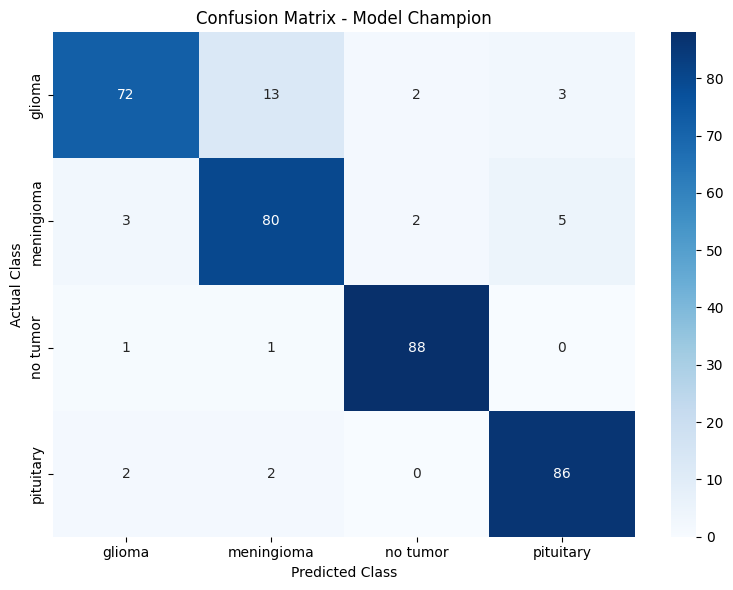


Confusion Matrix disimpan di:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/confusion_matrix_model_champion.png

TABEL METRIK MODEL CHAMPION


,Metric,Value
0,Accuracy,0.905556
1,Precision Macro,0.906956
2,Recall Macro,0.905556
3,F1 Macro,0.904793



CLASSIFICATION REPORT


,precision,recall,f1-score,support
glioma,0.923077,0.800000,0.857143,90.000000
meningioma,0.833333,0.888889,0.860215,90.000000
no tumor,0.956522,0.977778,0.967033,90.000000
pituitary,0.914894,0.955556,0.934783,90.000000
accuracy,0.905556,0.905556,0.905556,0.905556
macro avg,0.906956,0.905556,0.904793,360.000000
weighted avg,0.906956,0.905556,0.904793,360.000000



SEMUA HASIL BAGIAN 11 BERHASIL DISIMPAN

Model:
/content/drive/MyDrive/Brain_Tumor_CNN/models/cnn_champion_final.keras

Hasil evaluasi:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/final_champion_evaluation.json

Metrik CSV:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/final_champion_metrics.csv

Classification Report:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/final_champion_classification_report.csv

Confusion Matrix CSV:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/final_champion_confusion_matrix.csv

Confusion Matrix Grafik:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/confusion_matrix_model_champion.png

Bagian 11 selesai.


In [ ]:
# ============================================================
# BAGIAN 11 — EVALUASI MODEL CHAMPION
# Tidak melakukan training ulang
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive", force_remount=False)

# ============================================================
# 2. RESTORE PATH
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

DATASET_DIR = os.path.join(BASE_DIR, "dataset")
MODEL_DIR = os.path.join(BASE_DIR, "models")
GRAPH_DIR = os.path.join(BASE_DIR, "grafik")
CACHE_DIR = os.path.join(BASE_DIR, "cache")
DOC_DIR = os.path.join(BASE_DIR, "dokumen")
RESULT_DIR = os.path.join(BASE_DIR, "hasil")
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")

for folder in [
    BASE_DIR,
    DATASET_DIR,
    MODEL_DIR,
    GRAPH_DIR,
    CACHE_DIR,
    DOC_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Path berhasil dipulihkan.")
print("BASE_DIR:", BASE_DIR)


# ============================================================
# 3. KONFIGURASI
# ============================================================

IMAGE_SIZE = (128, 128)
INPUT_SHAPE = (128, 128, 3)

class_names = [
    "glioma",
    "meningioma",
    "no tumor",
    "pituitary"
]

NUM_CLASSES = len(class_names)


# ============================================================
# 4. CEK MODEL CHAMPION
# ============================================================

CHAMPION_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cnn_champion_final.keras"
)

if not os.path.exists(CHAMPION_MODEL_PATH):
    print("\n❌ MODEL CHAMPION BELUM DITEMUKAN!")
    print("File yang dicari:")
    print(CHAMPION_MODEL_PATH)
    print("\nPastikan Bagian 10 sudah selesai sampai model champion tersimpan.")
    raise FileNotFoundError(
        "cnn_champion_final.keras belum tersedia. Selesaikan Bagian 10 terlebih dahulu."
    )

print("\nModel champion ditemukan:")
print(CHAMPION_MODEL_PATH)


# ============================================================
# 5. LOAD MODEL CHAMPION
# ============================================================

print("\nMemuat model champion...")

champion_model = load_model(CHAMPION_MODEL_PATH)

print("Model berhasil dimuat.")
champion_model.summary()


# ============================================================
# 6. LOAD DATA TEST TERBAIK
# ============================================================

X_TEST_PATH = os.path.join(
    CACHE_DIR,
    "X_test_best_split.npy"
)

Y_TEST_PATH = os.path.join(
    CACHE_DIR,
    "y_test_best_split.npy"
)

if not os.path.exists(X_TEST_PATH):
    raise FileNotFoundError(
        f"Data test tidak ditemukan:\n{X_TEST_PATH}"
    )

if not os.path.exists(Y_TEST_PATH):
    raise FileNotFoundError(
        f"Label test tidak ditemukan:\n{Y_TEST_PATH}"
    )

X_test = np.load(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH)

print("\nData test berhasil dimuat.")
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)


# ============================================================
# 7. MEMBUAT TEST DATASET
# Tidak menggunakan augmentation
# ============================================================

def normalize_test_image(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = test_dataset.map(
    normalize_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(32)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)


# ============================================================
# 8. PREDIKSI MODEL CHAMPION
# ============================================================

print("\nMelakukan prediksi pada data test...")

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = champion_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy().astype(int)
    )

    y_pred.extend(
        predicted_labels.astype(int)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Prediksi selesai.")
print("Jumlah data test:", len(y_true))


# ============================================================
# 9. HITUNG METRIK
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision_macro = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# 10. TAMPILKAN HASIL EVALUASI
# ============================================================

print("\n" + "=" * 60)
print("HASIL EVALUASI MODEL CHAMPION")
print("=" * 60)

print(f"Accuracy        : {accuracy:.4f}")
print(f"Precision Macro : {precision_macro:.4f}")
print(f"Recall Macro    : {recall_macro:.4f}")
print(f"F1 Macro        : {f1_macro:.4f}")

print("=" * 60)


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print("=" * 60)
print(report_text)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

print("\nCONFUSION MATRIX")
print(cm)


# ============================================================
# 13. VISUALISASI CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Model Champion")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

confusion_path = os.path.join(
    GRAPH_DIR,
    "confusion_matrix_model_champion.png"
)

plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion Matrix disimpan di:")
print(confusion_path)


# ============================================================
# 14. SIMPAN HASIL METRIK
# ============================================================

evaluation_result = {
    "model": "cnn_champion_final",
    "test_samples": int(len(y_true)),
    "accuracy": float(accuracy),
    "precision_macro": float(precision_macro),
    "recall_macro": float(recall_macro),
    "f1_macro": float(f1_macro),
    "class_names": class_names,
    "confusion_matrix": cm.tolist(),
    "classification_report": report_dict
}

evaluation_json_path = os.path.join(
    RESULT_DIR,
    "final_champion_evaluation.json"
)

with open(
    evaluation_json_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        evaluation_result,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 15. SIMPAN TABEL METRIK
# ============================================================

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],
    "Value": [
        accuracy,
        precision_macro,
        recall_macro,
        f1_macro
    ]
})

metrics_csv_path = os.path.join(
    RESULT_DIR,
    "final_champion_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv_path,
    index=False
)


# ============================================================
# 16. SIMPAN CLASSIFICATION REPORT
# ============================================================

report_df = pd.DataFrame(report_dict).transpose()

report_csv_path = os.path.join(
    RESULT_DIR,
    "final_champion_classification_report.csv"
)

report_df.to_csv(
    report_csv_path
)


# ============================================================
# 17. SIMPAN CONFUSION MATRIX
# ============================================================

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_csv_path = os.path.join(
    RESULT_DIR,
    "final_champion_confusion_matrix.csv"
)

cm_df.to_csv(
    cm_csv_path
)


# ============================================================
# 18. TAMPILKAN TABEL
# ============================================================

print("\nTABEL METRIK MODEL CHAMPION")
display(metrics_df)

print("\nCLASSIFICATION REPORT")
display(report_df)


# ============================================================
# 19. INFORMASI FILE HASIL
# ============================================================

print("\n" + "=" * 60)
print("SEMUA HASIL BAGIAN 11 BERHASIL DISIMPAN")
print("=" * 60)

print("\nModel:")
print(CHAMPION_MODEL_PATH)

print("\nHasil evaluasi:")
print(evaluation_json_path)

print("\nMetrik CSV:")
print(metrics_csv_path)

print("\nClassification Report:")
print(report_csv_path)

print("\nConfusion Matrix CSV:")
print(cm_csv_path)

print("\nConfusion Matrix Grafik:")
print(confusion_path)

print("\nBagian 11 selesai.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Path berhasil dipulihkan.

Kelas yang digunakan:
0 = glioma
1 = meningioma
2 = no tumor
3 = pituitary

Memuat model champion...
/content/drive/MyDrive/Brain_Tumor_CNN/models/cnn_champion_final.keras
Model champion berhasil dimuat.

Data test berhasil dimuat.
X_test : (360, 128, 128, 3)
y_test : (360,)

Melakukan prediksi pada data test...
Prediksi selesai.
Jumlah data yang diprediksi: 360

CONFUSION MATRIX
[[72 13  2  3]
 [ 3 80  2  5]
 [ 1  1 88  0]
 [ 2  2  0 86]]

Tabel Confusion Matrix:


,Predicted - glioma,Predicted - meningioma,Predicted - no tumor,Predicted - pituitary
Actual - glioma,72,13,2,3
Actual - meningioma,3,80,2,5
Actual - no tumor,1,1,88,0
Actual - pituitary,2,2,0,86


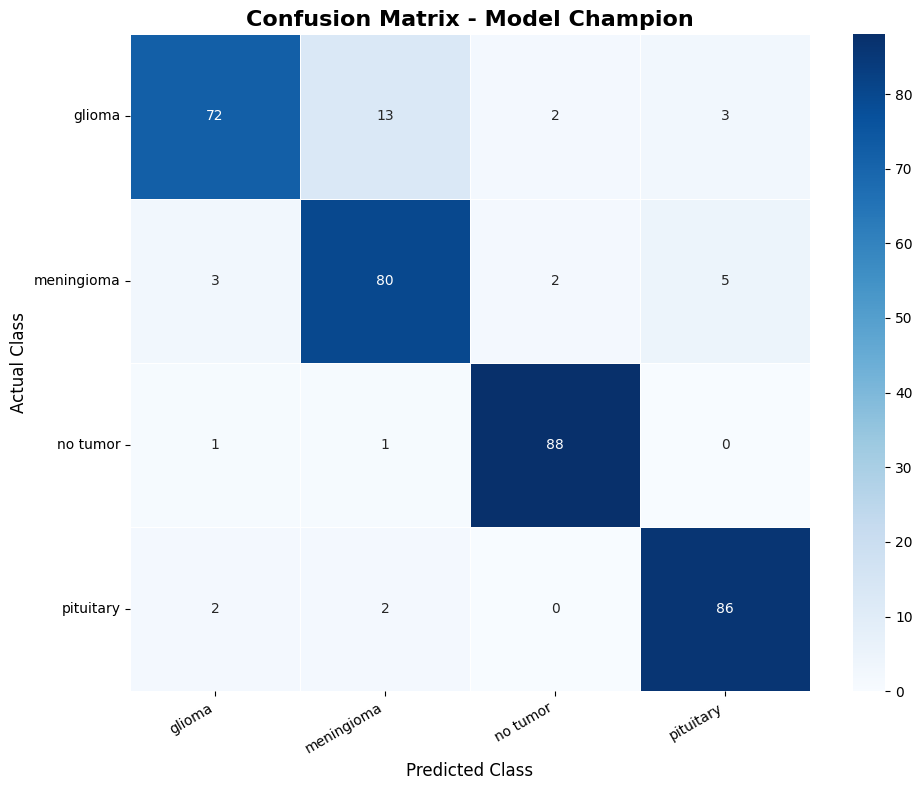


Grafik Confusion Matrix disimpan di:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_12_confusion_matrix_champion.png

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.92      0.80      0.86        90
  meningioma       0.83      0.89      0.86        90
    no tumor       0.96      0.98      0.97        90
   pituitary       0.91      0.96      0.93        90

    accuracy                           0.91       360
   macro avg       0.91      0.91      0.90       360
weighted avg       0.91      0.91      0.90       360


Tabel Classification Report:


,precision,recall,f1-score,support
glioma,0.9231,0.8000,0.8571,90.0000
meningioma,0.8333,0.8889,0.8602,90.0000
no tumor,0.9565,0.9778,0.9670,90.0000
pituitary,0.9149,0.9556,0.9348,90.0000
accuracy,0.9056,0.9056,0.9056,0.9056
macro avg,0.9070,0.9056,0.9048,360.0000
weighted avg,0.9070,0.9056,0.9048,360.0000


<Figure size 1100x600 with 0 Axes>

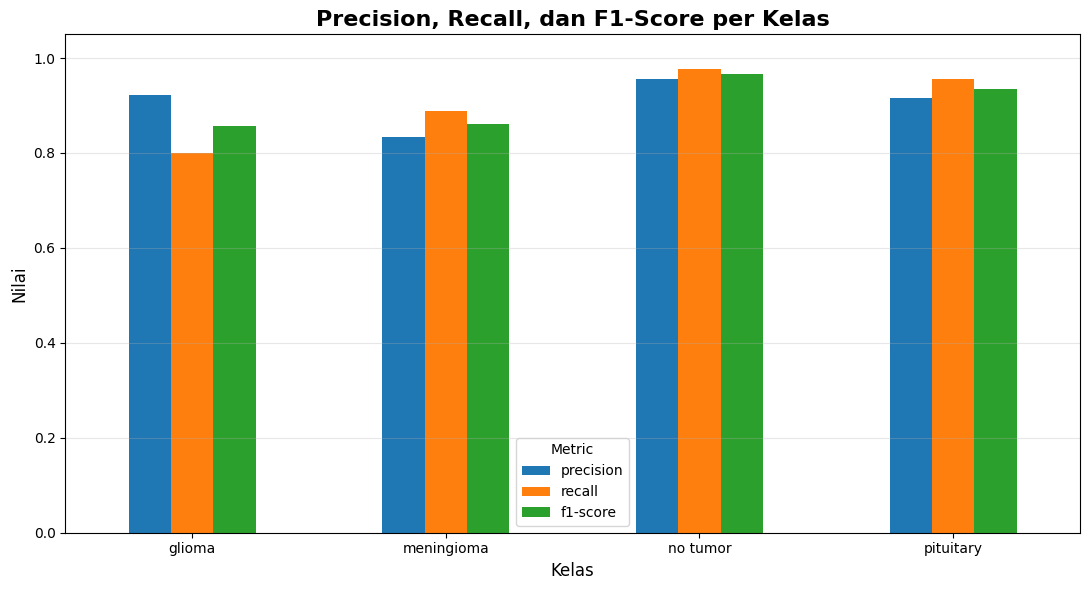


Grafik metrik per kelas disimpan di:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_12_precision_recall_f1_per_kelas.png

RINGKASAN METRIK MODEL CHAMPION


,Metric,Value
0,Accuracy,0.9056
1,Precision Macro,0.9070
2,Recall Macro,0.9056
3,F1 Macro,0.9048



Distribusi Actual vs Predicted:


,Kelas,Actual,Predicted
0,glioma,90,78
1,meningioma,90,96
2,no tumor,90,92
3,pituitary,90,94



Analisis Kesalahan Per Kelas:


,Kelas,Benar (TP),Salah FN,Salah FP,Total Actual
0,glioma,72,18,6,90
1,meningioma,80,10,16,90
2,no tumor,88,2,4,90
3,pituitary,86,4,8,90



INTERPRETASI HASIL
Model menghasilkan Accuracy sebesar 0.9056.
Precision Macro sebesar 0.9070.
Recall Macro sebesar 0.9056.
F1 Macro sebesar 0.9048.

Interpretasi per kelas:
- glioma: Precision=0.9231, Recall=0.8000, F1=0.8571
- meningioma: Precision=0.8333, Recall=0.8889, F1=0.8602
- no tumor: Precision=0.9565, Recall=0.9778, F1=0.9670
- pituitary: Precision=0.9149, Recall=0.9556, F1=0.9348

BAGIAN 12 SELESAI

File yang dihasilkan:

1. Confusion Matrix:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_12_confusion_matrix_champion.png

2. Grafik Precision, Recall, F1:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_12_precision_recall_f1_per_kelas.png

3. Confusion Matrix CSV:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_12_confusion_matrix.csv

4. Classification Report CSV:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_12_classification_report.csv

5. Summary Metrics CSV:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_12_summary_metrics.csv

6. Error Analys

In [ ]:
# ============================================================
# BAGIAN 12
# ANALISIS CONFUSION MATRIX & CLASSIFICATION REPORT
# MODEL CHAMPION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from tensorflow.keras.models import load_model

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive", force_remount=False)

# ============================================================
# 2. RESTORE PATH
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

DATASET_DIR = os.path.join(BASE_DIR, "dataset")
MODEL_DIR = os.path.join(BASE_DIR, "models")
GRAPH_DIR = os.path.join(BASE_DIR, "grafik")
CACHE_DIR = os.path.join(BASE_DIR, "cache")
DOC_DIR = os.path.join(BASE_DIR, "dokumen")
RESULT_DIR = os.path.join(BASE_DIR, "hasil")
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")

for folder in [
    BASE_DIR,
    DATASET_DIR,
    MODEL_DIR,
    GRAPH_DIR,
    CACHE_DIR,
    DOC_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Path berhasil dipulihkan.")


# ============================================================
# 3. KONFIGURASI
# ============================================================

IMAGE_SIZE = (128, 128)
INPUT_SHAPE = (128, 128, 3)

class_names = [
    "glioma",
    "meningioma",
    "no tumor",
    "pituitary"
]

NUM_CLASSES = len(class_names)

print("\nKelas yang digunakan:")
for i, class_name in enumerate(class_names):
    print(f"{i} = {class_name}")


# ============================================================
# 4. LOAD MODEL CHAMPION
# ============================================================

CHAMPION_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cnn_champion_final.keras"
)

if not os.path.exists(CHAMPION_MODEL_PATH):
    raise FileNotFoundError(
        "Model champion tidak ditemukan.\n"
        f"Lokasi yang dicari:\n{CHAMPION_MODEL_PATH}\n\n"
        "Pastikan Bagian 10 sudah selesai."
    )

print("\nMemuat model champion...")
print(CHAMPION_MODEL_PATH)

champion_model = load_model(
    CHAMPION_MODEL_PATH
)

print("Model champion berhasil dimuat.")


# ============================================================
# 5. LOAD DATA TEST
# ============================================================

X_TEST_PATH = os.path.join(
    CACHE_DIR,
    "X_test_best_split.npy"
)

Y_TEST_PATH = os.path.join(
    CACHE_DIR,
    "y_test_best_split.npy"
)

if not os.path.exists(X_TEST_PATH):
    raise FileNotFoundError(
        f"X_test tidak ditemukan:\n{X_TEST_PATH}"
    )

if not os.path.exists(Y_TEST_PATH):
    raise FileNotFoundError(
        f"y_test tidak ditemukan:\n{Y_TEST_PATH}"
    )

X_test = np.load(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH)

print("\nData test berhasil dimuat.")
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)


# ============================================================
# 6. MEMBUAT TEST DATASET
# Tanpa augmentation
# ============================================================

def normalize_test_image(image, label):
    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image, label


test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = test_dataset.map(
    normalize_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(32)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)


# ============================================================
# 7. PREDIKSI MODEL
# ============================================================

print("\nMelakukan prediksi pada data test...")

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = champion_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy().astype(int)
    )

    y_pred.extend(
        predicted_labels.astype(int)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Prediksi selesai.")
print("Jumlah data yang diprediksi:", len(y_pred))


# ============================================================
# 8. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)


# ============================================================
# 9. BUAT DATAFRAME CONFUSION MATRIX
# ============================================================

cm_df = pd.DataFrame(
    cm,
    index=[
        f"Actual - {name}"
        for name in class_names
    ],
    columns=[
        f"Predicted - {name}"
        for name in class_names
    ]
)

print("\nTabel Confusion Matrix:")
display(cm_df)


# ============================================================
# 10. VISUALISASI CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.title(
    "Confusion Matrix - Model Champion",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Predicted Class",
    fontsize=12
)

plt.ylabel(
    "Actual Class",
    fontsize=12
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

CONFUSION_GRAPH_PATH = os.path.join(
    GRAPH_DIR,
    "bagian_12_confusion_matrix_champion.png"
)

plt.savefig(
    CONFUSION_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nGrafik Confusion Matrix disimpan di:"
)
print(CONFUSION_GRAPH_PATH)


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(report_text)


# ============================================================
# 12. UBAH CLASSIFICATION REPORT MENJADI TABEL
# ============================================================

report_df = pd.DataFrame(
    report_dict
).transpose()

report_df = report_df.round(4)

print("\nTabel Classification Report:")
display(report_df)


# ============================================================
# 13. VISUALISASI PRECISION, RECALL, F1
# PER KELAS
# ============================================================

class_report_df = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score"]
]

plt.figure(figsize=(11, 6))

class_report_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Precision, Recall, dan F1-Score per Kelas",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Kelas",
    fontsize=12
)

plt.ylabel(
    "Nilai",
    fontsize=12
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Metric"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

CLASS_METRIC_GRAPH_PATH = os.path.join(
    GRAPH_DIR,
    "bagian_12_precision_recall_f1_per_kelas.png"
)

plt.savefig(
    CLASS_METRIC_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nGrafik metrik per kelas disimpan di:"
)

print(CLASS_METRIC_GRAPH_PATH)


# ============================================================
# 14. HITUNG METRIK KESELURUHAN
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision_macro = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# 15. TABEL RINGKAS METRIK
# ============================================================

summary_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],
    "Value": [
        accuracy,
        precision_macro,
        recall_macro,
        f1_macro
    ]
})

summary_metrics["Value"] = summary_metrics["Value"].round(4)

print("\n" + "=" * 70)
print("RINGKASAN METRIK MODEL CHAMPION")
print("=" * 70)

display(summary_metrics)


# ============================================================
# 16. ANALISIS JUMLAH PREDIKSI PER KELAS
# ============================================================

actual_counts = np.bincount(
    y_true,
    minlength=NUM_CLASSES
)

predicted_counts = np.bincount(
    y_pred,
    minlength=NUM_CLASSES
)

prediction_distribution = pd.DataFrame({
    "Kelas": class_names,
    "Actual": actual_counts,
    "Predicted": predicted_counts
})

print("\nDistribusi Actual vs Predicted:")
display(prediction_distribution)


# ============================================================
# 17. ANALISIS KESALAHAN PER KELAS
# ============================================================

error_analysis = []

for i, class_name in enumerate(class_names):

    true_positive = cm[i, i]

    total_actual = cm[i].sum()

    false_negative = total_actual - true_positive

    total_predicted = cm[:, i].sum()

    false_positive = total_predicted - true_positive

    error_analysis.append({
        "Kelas": class_name,
        "Benar (TP)": int(true_positive),
        "Salah FN": int(false_negative),
        "Salah FP": int(false_positive),
        "Total Actual": int(total_actual)
    })

error_df = pd.DataFrame(
    error_analysis
)

print("\nAnalisis Kesalahan Per Kelas:")
display(error_df)


# ============================================================
# 18. SIMPAN CONFUSION MATRIX CSV
# ============================================================

CM_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_12_confusion_matrix.csv"
)

cm_save_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_save_df.to_csv(
    CM_CSV_PATH
)


# ============================================================
# 19. SIMPAN CLASSIFICATION REPORT CSV
# ============================================================

REPORT_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_12_classification_report.csv"
)

report_df.to_csv(
    REPORT_CSV_PATH
)


# ============================================================
# 20. SIMPAN METRIK RINGKAS CSV
# ============================================================

METRICS_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_12_summary_metrics.csv"
)

summary_metrics.to_csv(
    METRICS_CSV_PATH,
    index=False
)


# ============================================================
# 21. SIMPAN ERROR ANALYSIS CSV
# ============================================================

ERROR_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_12_error_analysis.csv"
)

error_df.to_csv(
    ERROR_CSV_PATH,
    index=False
)


# ============================================================
# 22. SIMPAN HASIL LENGKAP DALAM JSON
# ============================================================

analysis_result = {
    "model": "cnn_champion_final",
    "test_samples": int(len(y_true)),

    "metrics": {
        "accuracy": float(accuracy),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro)
    },

    "class_names": class_names,

    "confusion_matrix": cm.tolist(),

    "classification_report": report_dict,

    "prediction_distribution": prediction_distribution.to_dict(
        orient="records"
    ),

    "error_analysis": error_df.to_dict(
        orient="records"
    )
}

JSON_PATH = os.path.join(
    RESULT_DIR,
    "bagian_12_analysis_result.json"
)

with open(
    JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        analysis_result,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 23. CETAK INTERPRETASI OTOMATIS
# ============================================================

print("\n" + "=" * 70)
print("INTERPRETASI HASIL")
print("=" * 70)

print(
    f"Model menghasilkan Accuracy sebesar "
    f"{accuracy:.4f}."
)

print(
    f"Precision Macro sebesar "
    f"{precision_macro:.4f}."
)

print(
    f"Recall Macro sebesar "
    f"{recall_macro:.4f}."
)

print(
    f"F1 Macro sebesar "
    f"{f1_macro:.4f}."
)

print("\nInterpretasi per kelas:")

for i, class_name in enumerate(class_names):

    class_precision = report_dict[
        class_name
    ]["precision"]

    class_recall = report_dict[
        class_name
    ]["recall"]

    class_f1 = report_dict[
        class_name
    ]["f1-score"]

    print(
        f"- {class_name}: "
        f"Precision={class_precision:.4f}, "
        f"Recall={class_recall:.4f}, "
        f"F1={class_f1:.4f}"
    )


# ============================================================
# 24. FILE OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("BAGIAN 12 SELESAI")
print("=" * 70)

print("\nFile yang dihasilkan:")

print("\n1. Confusion Matrix:")
print(CONFUSION_GRAPH_PATH)

print("\n2. Grafik Precision, Recall, F1:")
print(CLASS_METRIC_GRAPH_PATH)

print("\n3. Confusion Matrix CSV:")
print(CM_CSV_PATH)

print("\n4. Classification Report CSV:")
print(REPORT_CSV_PATH)

print("\n5. Summary Metrics CSV:")
print(METRICS_CSV_PATH)

print("\n6. Error Analysis CSV:")
print(ERROR_CSV_PATH)

print("\n7. Hasil Lengkap JSON:")
print(JSON_PATH)

print("\nSemua hasil tersimpan di Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BAGIAN 13 — TRAINING & VALIDATION CURVES

BASE_DIR      : /content/drive/MyDrive/Brain_Tumor_CNN
CHECKPOINT_DIR: /content/drive/MyDrive/Brain_Tumor_CNN/checkpoints
GRAPH_DIR     : /content/drive/MyDrive/Brain_Tumor_CNN/grafik
RESULT_DIR    : /content/drive/MyDrive/Brain_Tumor_CNN/hasil

Model yang dianalisis:
cnn_champion_final

File history champion tidak ditemukan dengan nama standar.

File history yang tersedia:
1. S1_Split_70_15_15_history.json
2. S1_Split_80_10_10_history.json
3. S1_Split_90_05_05_history.json
4. S2_Augmentation_Tanpa_Augmentasi_history.json
5. S2_Augmentation_Dengan_Augmentasi_history.json
6. S3_Optimizer_Adam_history.json
7. S3_Optimizer_RMSprop_history.json
8. S3_Optimizer_SGD_Momentum_history.json
9. S4_Dropout_Dropout_0_0_history.json
10. S4_Dropout_Dropout_0_3_history.json
11. S4_Dropout_Dropout_0_5_history.json

Kandidat history y

,Epoch,Train Loss,Validation Loss,Train Accuracy,Validation Accuracy
0,1,1.3454,1.3019,0.2890,0.3667
1,2,1.2045,1.0950,0.4829,0.5972
2,3,1.0137,0.9180,0.5969,0.6611
3,4,0.9029,0.8304,0.6438,0.6611
4,5,0.8279,0.7607,0.6816,0.6833
5,6,0.7677,0.7143,0.7059,0.7583
6,7,0.7201,0.6909,0.7302,0.7306
7,8,0.6680,0.6112,0.7537,0.7806
8,9,0.6204,0.5908,0.7693,0.8028
9,10,0.5991,0.6195,0.7801,0.7611


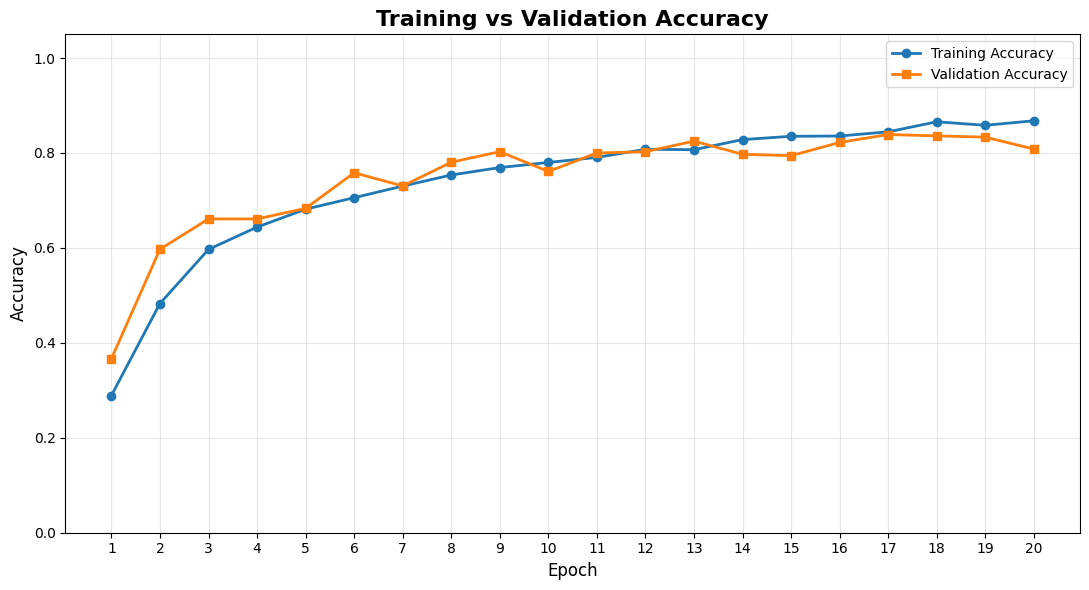


✓ Grafik accuracy disimpan:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_13_training_validation_accuracy.png


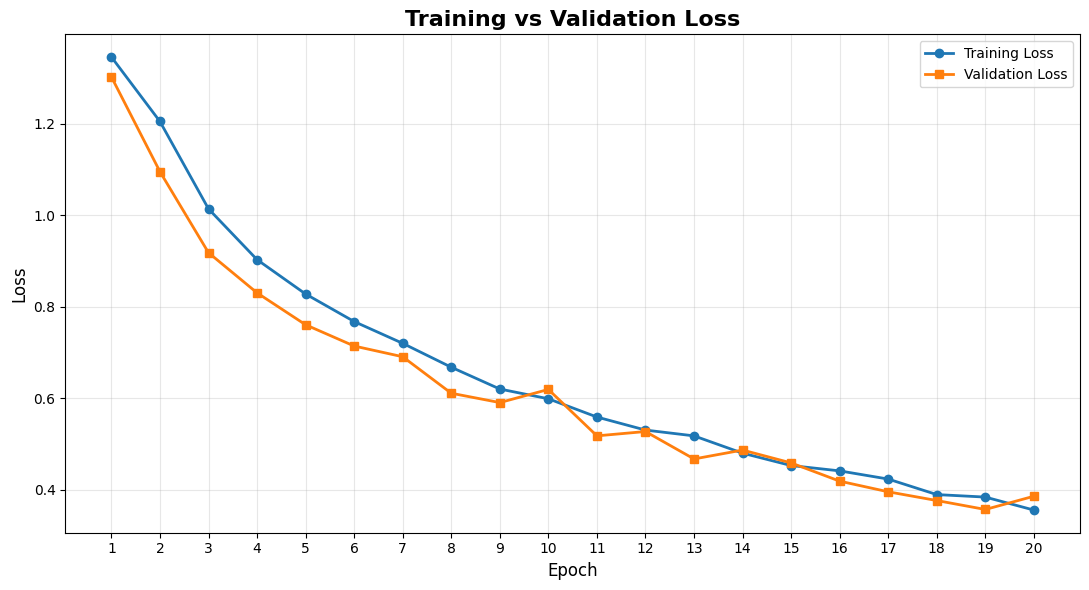


✓ Grafik loss disimpan:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_13_training_validation_loss.png

BEST EPOCH
Best Epoch berdasarkan Validation Loss     : 19
Best Validation Loss                       : 0.3574
Best Epoch berdasarkan Validation Accuracy : 17
Best Validation Accuracy                   : 0.8389

ANALISIS AKHIR TRAINING
Training Accuracy akhir   : 0.8679
Validation Accuracy akhir : 0.8083
Accuracy Gap              : 0.0596
Training Loss akhir       : 0.3561
Validation Loss akhir     : 0.3863
Loss Gap                  : 0.0302

INTERPRETASI KURVA
⚠ Terdapat selisih training dan validation accuracy ≥ 5%.
  Terdapat indikasi overfitting yang perlu diperhatikan.
✓ Perbedaan validation loss dan training loss masih relatif terkendali.

✓ Training history disimpan:
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_13_training_history.csv

BAGIAN 13 SELESAI

Output yang dihasilkan:

1. Grafik Accuracy:
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_13_training_

In [ ]:
# ============================================================
# BAGIAN 13
# VISUALISASI TRAINING & VALIDATION CURVES
# MODEL CHAMPION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive


# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive", force_remount=False)


# ============================================================
# 2. RESTORE PATH
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models"
)

GRAPH_DIR = os.path.join(
    BASE_DIR,
    "grafik"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "hasil"
)

CHECKPOINT_DIR = os.path.join(
    BASE_DIR,
    "checkpoints"
)

for folder in [
    MODEL_DIR,
    GRAPH_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )


print("=" * 70)
print("BAGIAN 13 — TRAINING & VALIDATION CURVES")
print("=" * 70)

print("\nBASE_DIR      :", BASE_DIR)
print("CHECKPOINT_DIR:", CHECKPOINT_DIR)
print("GRAPH_DIR     :", GRAPH_DIR)
print("RESULT_DIR    :", RESULT_DIR)


# ============================================================
# 3. IDENTITAS MODEL CHAMPION
# ============================================================

CHAMPION_MODEL = "cnn_champion_final"

print("\nModel yang dianalisis:")
print(CHAMPION_MODEL)


# ============================================================
# 4. MENCARI FILE HISTORY
# ============================================================

possible_history_files = [

    os.path.join(
        CHECKPOINT_DIR,
        "cnn_champion_final_history.json"
    ),

    os.path.join(
        CHECKPOINT_DIR,
        "S4_Dropout_0.0_history.json"
    ),

    os.path.join(
        CHECKPOINT_DIR,
        "S4_Dropout_0.3_history.json"
    ),

    os.path.join(
        CHECKPOINT_DIR,
        "S4_Dropout_0.5_history.json"
    )
]


history_path = None

for path in possible_history_files:

    if os.path.exists(path):

        history_path = path
        break


# ============================================================
# 5. JIKA HISTORY CHAMPION TIDAK DITEMUKAN
#    CARI SEMUA FILE HISTORY
# ============================================================

if history_path is None:

    all_history_files = []

    for filename in os.listdir(
        CHECKPOINT_DIR
    ):

        if filename.endswith(
            "_history.json"
        ):

            all_history_files.append(
                os.path.join(
                    CHECKPOINT_DIR,
                    filename
                )
            )

    if len(all_history_files) > 0:

        print(
            "\nFile history champion "
            "tidak ditemukan dengan nama standar."
        )

        print(
            "\nFile history yang tersedia:"
        )

        for i, path in enumerate(
            all_history_files,
            start=1
        ):

            print(
                f"{i}. {os.path.basename(path)}"
            )

        # Ambil file terakhir sebagai kandidat
        history_path = all_history_files[-1]

        print(
            "\nKandidat history yang digunakan:"
        )

        print(history_path)


# ============================================================
# 6. CEK HISTORY
# ============================================================

if history_path is None:

    raise FileNotFoundError(
        "\nTidak ditemukan file history training "
        "di folder checkpoints.\n\n"
        "Pastikan Bagian 10 sudah menyimpan "
        "file *_history.json."
    )


print("\n✓ History ditemukan:")
print(history_path)


# ============================================================
# 7. LOAD HISTORY
# ============================================================

with open(
    history_path,
    "r",
    encoding="utf-8"
) as f:

    history_data = json.load(f)


print("\n✓ History berhasil dimuat.")

print("\nMetric yang tersedia:")

for key in history_data.keys():

    print(
        " -",
        key
    )


# ============================================================
# 8. NORMALISASI NAMA METRIK
# ============================================================

# Beberapa versi TensorFlow bisa menggunakan
# accuracy / acc dan val_accuracy / val_acc.

if (
    "accuracy" not in history_data
    and "acc" in history_data
):

    history_data["accuracy"] = (
        history_data["acc"]
    )


if (
    "val_accuracy" not in history_data
    and "val_acc" in history_data
):

    history_data["val_accuracy"] = (
        history_data["val_acc"]
    )


# ============================================================
# 9. CEK METRIC WAJIB
# ============================================================

required_metrics = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy"
]

missing_metrics = [
    metric
    for metric in required_metrics
    if metric not in history_data
]


if missing_metrics:

    print(
        "\n⚠ Metric yang tidak ditemukan:"
    )

    for metric in missing_metrics:

        print(
            " -",
            metric
        )

    raise KeyError(
        "History tidak memiliki metric lengkap."
    )


# ============================================================
# 10. MENYAMAKAN JUMLAH EPOCH
# ============================================================

num_epochs = min(
    len(history_data["loss"]),
    len(history_data["accuracy"]),
    len(history_data["val_loss"]),
    len(history_data["val_accuracy"])
)


epochs = np.arange(
    1,
    num_epochs + 1
)


print(
    f"\nJumlah epoch yang tersedia: "
    f"{num_epochs}"
)


# ============================================================
# 11. MEMBUAT DATAFRAME HISTORY
# ============================================================

history_df = pd.DataFrame({

    "Epoch": epochs,

    "Train Loss":
        history_data["loss"][:num_epochs],

    "Validation Loss":
        history_data["val_loss"][:num_epochs],

    "Train Accuracy":
        history_data["accuracy"][:num_epochs],

    "Validation Accuracy":
        history_data["val_accuracy"][:num_epochs]

})


print("\nTabel Training History:")
display(
    history_df.round(4)
)


# ============================================================
# 12. GRAFIK ACCURACY
# ============================================================

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    epochs,
    history_df["Train Accuracy"],
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_df["Validation Accuracy"],
    marker="s",
    linewidth=2,
    label="Validation Accuracy"
)

plt.title(
    "Training vs Validation Accuracy",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "Accuracy",
    fontsize=12
)

plt.xticks(
    epochs
)

plt.ylim(
    0,
    1.05
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


ACCURACY_GRAPH_PATH = os.path.join(
    GRAPH_DIR,
    "bagian_13_training_validation_accuracy.png"
)

plt.savefig(
    ACCURACY_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\n✓ Grafik accuracy disimpan:"
)

print(
    ACCURACY_GRAPH_PATH
)


# ============================================================
# 13. GRAFIK LOSS
# ============================================================

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    epochs,
    history_df["Train Loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    history_df["Validation Loss"],
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

plt.title(
    "Training vs Validation Loss",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "Loss",
    fontsize=12
)

plt.xticks(
    epochs
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


LOSS_GRAPH_PATH = os.path.join(
    GRAPH_DIR,
    "bagian_13_training_validation_loss.png"
)

plt.savefig(
    LOSS_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\n✓ Grafik loss disimpan:"
)

print(
    LOSS_GRAPH_PATH
)


# ============================================================
# 14. MENCARI BEST EPOCH BERDASARKAN VAL LOSS
# ============================================================

best_epoch_loss_index = int(
    np.argmin(
        history_df["Validation Loss"].values
    )
)

best_epoch_loss = (
    best_epoch_loss_index + 1
)

best_val_loss = float(
    history_df.loc[
        best_epoch_loss_index,
        "Validation Loss"
    ]
)


# ============================================================
# 15. MENCARI BEST EPOCH BERDASARKAN VAL ACCURACY
# ============================================================

best_epoch_accuracy_index = int(
    np.argmax(
        history_df["Validation Accuracy"].values
    )
)

best_epoch_accuracy = (
    best_epoch_accuracy_index + 1
)

best_val_accuracy = float(
    history_df.loc[
        best_epoch_accuracy_index,
        "Validation Accuracy"
    ]
)


# ============================================================
# 16. HASIL BEST EPOCH
# ============================================================

print("\n" + "=" * 70)
print("BEST EPOCH")
print("=" * 70)

print(
    f"Best Epoch berdasarkan Validation Loss     : "
    f"{best_epoch_loss}"
)

print(
    f"Best Validation Loss                       : "
    f"{best_val_loss:.4f}"
)

print(
    f"Best Epoch berdasarkan Validation Accuracy : "
    f"{best_epoch_accuracy}"
)

print(
    f"Best Validation Accuracy                   : "
    f"{best_val_accuracy:.4f}"
)


# ============================================================
# 17. ANALISIS GAP TRAINING VS VALIDATION
# ============================================================

final_train_accuracy = float(
    history_df.iloc[-1]["Train Accuracy"]
)

final_val_accuracy = float(
    history_df.iloc[-1]["Validation Accuracy"]
)

final_train_loss = float(
    history_df.iloc[-1]["Train Loss"]
)

final_val_loss = float(
    history_df.iloc[-1]["Validation Loss"]
)

accuracy_gap = (
    final_train_accuracy
    - final_val_accuracy
)

loss_gap = (
    final_val_loss
    - final_train_loss
)


print("\n" + "=" * 70)
print("ANALISIS AKHIR TRAINING")
print("=" * 70)

print(
    f"Training Accuracy akhir   : "
    f"{final_train_accuracy:.4f}"
)

print(
    f"Validation Accuracy akhir : "
    f"{final_val_accuracy:.4f}"
)

print(
    f"Accuracy Gap              : "
    f"{accuracy_gap:.4f}"
)

print(
    f"Training Loss akhir       : "
    f"{final_train_loss:.4f}"
)

print(
    f"Validation Loss akhir     : "
    f"{final_val_loss:.4f}"
)

print(
    f"Loss Gap                  : "
    f"{loss_gap:.4f}"
)


# ============================================================
# 18. ANALISIS INDIKATIF OVERFITTING
# ============================================================

print("\n" + "=" * 70)
print("INTERPRETASI KURVA")
print("=" * 70)

if accuracy_gap < 0.05:

    print(
        "✓ Selisih training dan validation "
        "accuracy relatif kecil (< 5%)."
    )

    print(
        "  Tidak terlihat indikasi overfitting "
        "yang kuat berdasarkan accuracy akhir."
    )

else:

    print(
        "⚠ Terdapat selisih training dan validation "
        "accuracy ≥ 5%."
    )

    print(
        "  Terdapat indikasi overfitting yang "
        "perlu diperhatikan."
    )


if (
    final_val_loss
    > final_train_loss * 1.5
):

    print(
        "⚠ Validation loss cukup lebih tinggi "
        "daripada training loss."
    )

else:

    print(
        "✓ Perbedaan validation loss dan "
        "training loss masih relatif terkendali."
    )


# ============================================================
# 19. SIMPAN HISTORY KE CSV
# ============================================================

HISTORY_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_13_training_history.csv"
)

history_df.to_csv(
    HISTORY_CSV_PATH,
    index=False
)

print(
    "\n✓ Training history disimpan:"
)

print(
    HISTORY_CSV_PATH
)


# ============================================================
# 20. SIMPAN RINGKASAN ANALISIS
# ============================================================

curve_summary = {

    "model": CHAMPION_MODEL,

    "history_file": history_path,

    "epochs": int(num_epochs),

    "best_epoch_validation_loss":
        int(best_epoch_loss),

    "best_validation_loss":
        float(best_val_loss),

    "best_epoch_validation_accuracy":
        int(best_epoch_accuracy),

    "best_validation_accuracy":
        float(best_val_accuracy),

    "final_training_accuracy":
        float(final_train_accuracy),

    "final_validation_accuracy":
        float(final_val_accuracy),

    "final_training_loss":
        float(final_train_loss),

    "final_validation_loss":
        float(final_val_loss),

    "accuracy_gap":
        float(accuracy_gap),

    "loss_gap":
        float(loss_gap)
}


SUMMARY_JSON_PATH = os.path.join(
    RESULT_DIR,
    "bagian_13_curve_analysis.json"
)


with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        curve_summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 21. SELESAI
# ============================================================

print("\n" + "=" * 70)
print("BAGIAN 13 SELESAI")
print("=" * 70)

print("\nOutput yang dihasilkan:")

print(
    "\n1. Grafik Accuracy:"
)

print(
    ACCURACY_GRAPH_PATH
)

print(
    "\n2. Grafik Loss:"
)

print(
    LOSS_GRAPH_PATH
)

print(
    "\n3. Training History CSV:"
)

print(
    HISTORY_CSV_PATH
)

print(
    "\n4. Analisis Curve JSON:"
)

print(
    SUMMARY_JSON_PATH
)

print(
    "\n✓ Tidak ada training ulang."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BAGIAN 14 — VISUALISASI PREDIKSI CITRA MRI

Model berhasil dimuat:
/content/drive/MyDrive/Brain_Tumor_CNN/models/cnn_champion_final.keras

Bentuk X_test: (360, 128, 128, 3)
Bentuk y_test: (360,)

Data test siap digunakan.
Rentang piksel: 0.0 sampai 1.0
Jumlah citra: 360

Melakukan prediksi...
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 345ms/step

Prediksi selesai.
Prediksi benar: 326 dari 360
Prediksi salah: 34 dari 360

Contoh tabel hasil prediksi:


,Indeks_Citra,Kelas_Aktual,Kelas_Prediksi,Confidence_Persen,Status
0,0,pituitary,pituitary,99.690002,Benar
1,1,meningioma,meningioma,77.910004,Benar
2,2,pituitary,pituitary,99.720001,Benar
3,3,pituitary,pituitary,99.300003,Benar
4,4,pituitary,pituitary,99.949997,Benar
5,5,glioma,glioma,96.330002,Benar
6,6,no tumor,no tumor,97.949997,Benar
7,7,glioma,glioma,53.900002,Benar
8,8,pituitary,pituitary,98.099998,Benar
9,9,glioma,meningioma,69.029999,Salah


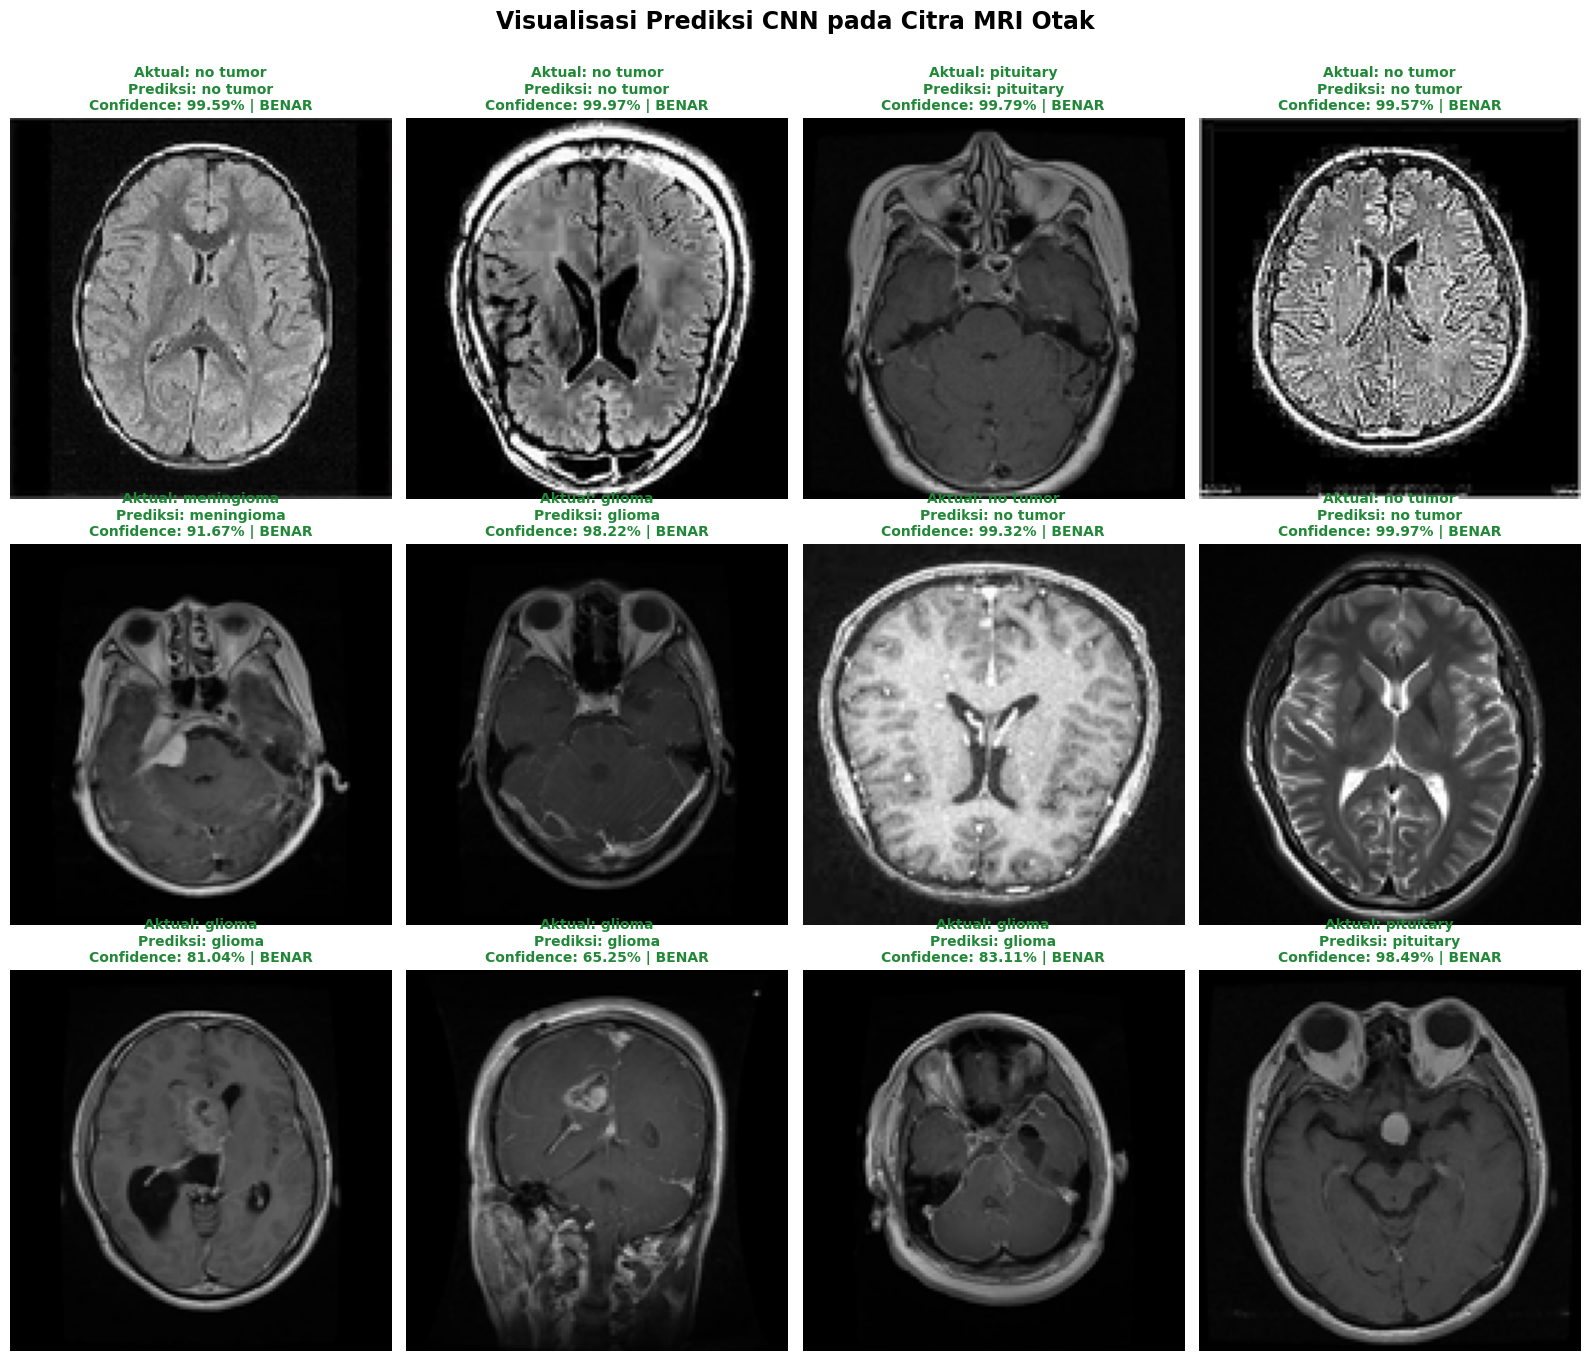

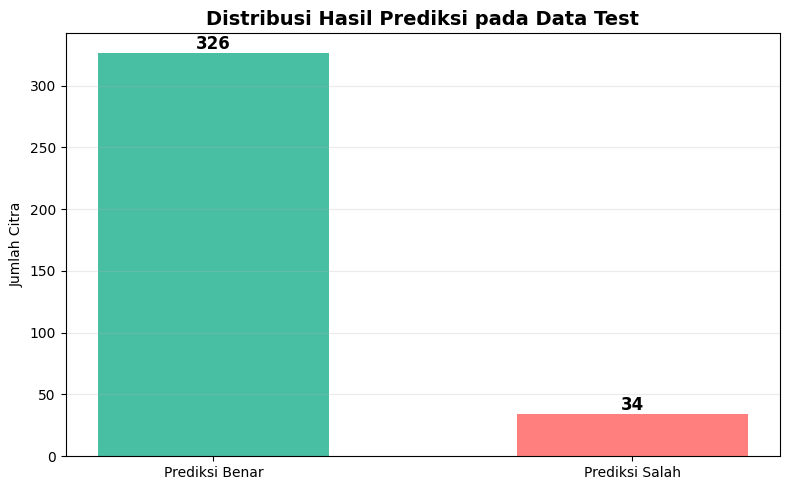


BAGIAN 14 SELESAI
Jumlah data test       : 360
Prediksi benar         : 326
Prediksi salah         : 34
Proporsi benar         : 90.56%
Confidence rata-rata   : 88.57%

FILE YANG TERSIMPAN
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_14_visualisasi_prediksi_mri.png
/content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_14_distribusi_prediksi.png
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_14_hasil_prediksi.csv
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_14_sampel_visualisasi.csv
/content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_14_ringkasan_prediksi.json


In [ ]:
# ============================================================
# BAGIAN 14 — VISUALISASI PREDIKSI CITRA MRI
# Brain Tumor MRI - Progressive Optimization CNN
# Tidak melakukan training ulang
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive
from tensorflow.keras.models import load_model

# ============================================================
# 1. GOOGLE DRIVE & KONFIGURASI PATH
# ============================================================

drive.mount("/content/drive", force_remount=False)

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

MODEL_DIR = os.path.join(BASE_DIR, "models")
CACHE_DIR = os.path.join(BASE_DIR, "cache")
GRAPH_DIR = os.path.join(BASE_DIR, "grafik")
RESULT_DIR = os.path.join(BASE_DIR, "hasil")

for folder in [MODEL_DIR, CACHE_DIR, GRAPH_DIR, RESULT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("=" * 70)
print("BAGIAN 14 — VISUALISASI PREDIKSI CITRA MRI")
print("=" * 70)

# ============================================================
# 2. KONFIGURASI KELAS
# Urutan harus sama dengan pemetaan label saat preprocessing
# ============================================================

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "no tumor",
    "pituitary"
]

NUM_CLASSES = len(CLASS_NAMES)

# ============================================================
# 3. MEMUAT MODEL CHAMPION
# ============================================================

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cnn_champion_final.keras"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "Model champion belum ditemukan!\n"
        f"Lokasi: {MODEL_PATH}\n"
        "Pastikan Bagian 10 berhasil menyimpan model final."
    )

model = load_model(MODEL_PATH)

print("\nModel berhasil dimuat:")
print(MODEL_PATH)

# ============================================================
# 4. MEMUAT DATA TEST
# ============================================================

X_TEST_PATH = os.path.join(
    CACHE_DIR,
    "X_test_best_split.npy"
)

Y_TEST_PATH = os.path.join(
    CACHE_DIR,
    "y_test_best_split.npy"
)

if not os.path.exists(X_TEST_PATH):
    raise FileNotFoundError(
        f"Data X_test tidak ditemukan: {X_TEST_PATH}"
    )

if not os.path.exists(Y_TEST_PATH):
    raise FileNotFoundError(
        f"Data y_test tidak ditemukan: {Y_TEST_PATH}"
    )

X_test = np.load(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH)

print("\nBentuk X_test:", X_test.shape)
print("Bentuk y_test:", y_test.shape)

if X_test.ndim != 4:
    raise ValueError(
        "X_test harus berbentuk (jumlah_data, tinggi, lebar, channel)."
    )

if X_test.shape[-1] != 3:
    raise ValueError(
        "Model ini mengharapkan citra RGB dengan 3 channel."
    )

# ============================================================
# 5. NORMALISASI DATA
# Mencegah normalisasi ganda jika data sudah dalam [0, 1]
# ============================================================

X_test = X_test.astype(np.float32)

if X_test.size == 0:
    raise ValueError("X_test kosong.")

if not np.isfinite(X_test).all():
    raise ValueError("X_test mengandung NaN atau nilai tak terhingga.")

if X_test.min() < 0:
    raise ValueError("Ditemukan nilai piksel negatif.")

if X_test.max() > 1.0:
    if X_test.max() <= 255.0:
        X_test = X_test / 255.0
    else:
        raise ValueError(
            "Rentang piksel tidak sesuai. Periksa preprocessing."
        )

# Menangani label integer atau one-hot encoding
if y_test.ndim > 1 and y_test.shape[-1] == NUM_CLASSES:
    y_true = np.argmax(y_test, axis=1)
elif y_test.ndim == 2 and y_test.shape[-1] == 1:
    y_true = y_test.reshape(-1).astype(int)
elif y_test.ndim == 1:
    y_true = y_test.astype(int)
else:
    raise ValueError(
        f"Format label tidak dikenali: {y_test.shape}"
    )

if len(X_test) != len(y_true):
    raise ValueError("Jumlah citra dan label tidak sama.")

if np.any(y_true < 0) or np.any(y_true >= NUM_CLASSES):
    raise ValueError(
        "Label di luar rentang kelas. Periksa pemetaan label."
    )

print("\nData test siap digunakan.")
print("Rentang piksel:", X_test.min(), "sampai", X_test.max())
print("Jumlah citra:", len(X_test))

# ============================================================
# 6. PREDIKSI SELURUH DATA TEST
# Tidak menggunakan model.fit()
# ============================================================

print("\nMelakukan prediksi...")

probabilities = model.predict(
    X_test,
    batch_size=32,
    verbose=1
)

if probabilities.ndim != 2 or probabilities.shape[1] != NUM_CLASSES:
    raise ValueError(
        f"Output model tidak sesuai. Bentuk output: {probabilities.shape}"
    )

y_pred = np.argmax(probabilities, axis=1)
confidence = np.max(probabilities, axis=1) * 100

is_correct = y_true == y_pred

print("\nPrediksi selesai.")
print(f"Prediksi benar: {is_correct.sum()} dari {len(y_true)}")
print(f"Prediksi salah: {(~is_correct).sum()} dari {len(y_true)}")

# ============================================================
# 7. MENYUSUN TABEL PREDIKSI
# ============================================================

prediction_df = pd.DataFrame({
    "Indeks_Citra": np.arange(len(y_true)),
    "Kelas_Aktual": [CLASS_NAMES[i] for i in y_true],
    "Kelas_Prediksi": [CLASS_NAMES[i] for i in y_pred],
    "Confidence_Persen": np.round(confidence, 2),
    "Status": np.where(is_correct, "Benar", "Salah")
})

print("\nContoh tabel hasil prediksi:")
display(prediction_df.head(15))

# ============================================================
# 8. MEMILIH SAMPEL UNTUK VISUALISASI
# Mengambil maksimal 12 gambar secara acak dan reproducible
# ============================================================

N_SAMPLES = min(12, len(X_test))
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)
sample_indices = np.sort(
    rng.choice(len(X_test), size=N_SAMPLES, replace=False)
)

# ============================================================
# 9. VISUALISASI PREDIKSI MRI
# Hijau = benar, merah = salah
# ============================================================

cols = 4
rows = int(np.ceil(N_SAMPLES / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 4.5 * rows)
)

axes = np.array(axes).reshape(-1)

for plot_idx, data_idx in enumerate(sample_indices):
    ax = axes[plot_idx]

    ax.imshow(np.clip(X_test[data_idx], 0, 1))

    actual_name = CLASS_NAMES[y_true[data_idx]]
    predicted_name = CLASS_NAMES[y_pred[data_idx]]
    conf = confidence[data_idx]

    correct = is_correct[data_idx]
    title_color = "#218838" if correct else "#D62828"
    status = "BENAR" if correct else "SALAH"

    ax.set_title(
        f"Aktual: {actual_name}\n"
        f"Prediksi: {predicted_name}\n"
        f"Confidence: {conf:.2f}% | {status}",
        color=title_color,
        fontsize=10,
        fontweight="bold"
    )

    ax.axis("off")

for idx in range(N_SAMPLES, len(axes)):
    axes[idx].axis("off")

fig.suptitle(
    "Visualisasi Prediksi CNN pada Citra MRI Otak",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

PREDICTION_GRAPH_PATH = os.path.join(
    GRAPH_DIR,
    "bagian_14_visualisasi_prediksi_mri.png"
)

plt.savefig(
    PREDICTION_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. VISUALISASI DISTRIBUSI PREDIKSI BENAR DAN SALAH
# ============================================================

correct_count = int(is_correct.sum())
incorrect_count = int((~is_correct).sum())

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Prediksi Benar", "Prediksi Salah"],
    [correct_count, incorrect_count],
    color=["#48BFA3", "#FF7F7F"],
    width=0.55
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "Distribusi Hasil Prediksi pada Data Test",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Jumlah Citra")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

CORRECT_GRAPH_PATH = os.path.join(
    GRAPH_DIR,
    "bagian_14_distribusi_prediksi.png"
)

plt.savefig(
    CORRECT_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. MENYIMPAN HASIL KE GOOGLE DRIVE
# ============================================================

PREDICTION_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_14_hasil_prediksi.csv"
)

SAMPLE_CSV_PATH = os.path.join(
    RESULT_DIR,
    "bagian_14_sampel_visualisasi.csv"
)

SUMMARY_JSON_PATH = os.path.join(
    RESULT_DIR,
    "bagian_14_ringkasan_prediksi.json"
)

prediction_df.to_csv(
    PREDICTION_CSV_PATH,
    index=False
)

prediction_df.iloc[sample_indices].to_csv(
    SAMPLE_CSV_PATH,
    index=False
)

summary = {
    "model_path": MODEL_PATH,
    "jumlah_data_test": int(len(y_true)),
    "jumlah_prediksi_benar": correct_count,
    "jumlah_prediksi_salah": incorrect_count,
    "proporsi_prediksi_benar": float(np.mean(is_correct)),
    "confidence_rata_rata_persen": float(np.mean(confidence)),
    "indeks_sampel_visualisasi": sample_indices.tolist(),
    "catatan": (
        "Proporsi prediksi benar pada data test bukan pengganti "
        "evaluasi metrik lengkap. Confidence bukan jaminan "
        "probabilitas model telah terkalibrasi."
    )
}

with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )

# ============================================================
# 12. RINGKASAN AKHIR
# ============================================================

print("\n" + "=" * 70)
print("BAGIAN 14 SELESAI")
print("=" * 70)

print(f"Jumlah data test       : {len(y_true)}")
print(f"Prediksi benar         : {correct_count}")
print(f"Prediksi salah         : {incorrect_count}")
print(f"Proporsi benar         : {np.mean(is_correct) * 100:.2f}%")
print(f"Confidence rata-rata   : {np.mean(confidence):.2f}%")

print("\nFILE YANG TERSIMPAN")

for path in [
    PREDICTION_GRAPH_PATH,
    CORRECT_GRAPH_PATH,
    PREDICTION_CSV_PATH,
    SAMPLE_CSV_PATH,
    SUMMARY_JSON_PATH
]:
    print(path)

In [ ]:
# ============================================================
# BAGIAN 15: REKAPITULASI DAN PENENTUAN MODEL TERBAIK
# Progressive Ablation Study - Brain Tumor MRI
# ============================================================

import os
import json
import glob
import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. PENGATURAN DIREKTORI
# ------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"
RESULT_DIR = os.path.join(BASE_DIR, "hasil")
MODEL_DIR = os.path.join(BASE_DIR, "models")
DOC_DIR = os.path.join(BASE_DIR, "dokumen")

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(DOC_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. CARI FILE HASIL EKSPERIMEN
# ------------------------------------------------------------
# Mencari file CSV/JSON yang mungkin berisi hasil metrik.
# File mentah tidak otomatis dianggap sebagai hasil eksperimen.

files = []
for ext in ("*.csv", "*.json"):
    files.extend(glob.glob(os.path.join(RESULT_DIR, "**", ext),
                           recursive=True))

print(f"Jumlah file CSV/JSON ditemukan: {len(files)}")
for f in sorted(files):
    print("-", os.path.relpath(f, BASE_DIR))

# ------------------------------------------------------------
# 3. BACA HASIL YANG FORMATNYA BISA DIKENALI
# ------------------------------------------------------------
frames = []
json_records = []

metric_aliases = {
    "accuracy": ["accuracy", "test_accuracy", "val_accuracy"],
    "precision_macro": [
        "precision_macro", "macro_precision", "precision"
    ],
    "recall_macro": [
        "recall_macro", "macro_recall", "recall"
    ],
    "f1_macro": ["f1_macro", "macro_f1", "f1_score", "f1"]
}

def find_value(data, aliases):
    """Ambil metrik jika nama kolom/key cocok."""
    lower_data = {str(k).lower(): v for k, v in data.items()}
    for alias in aliases:
        if alias in lower_data:
            value = lower_data[alias]
            try:
                value = float(value)
                if np.isfinite(value):
                    return value
            except (TypeError, ValueError):
                pass
    return np.nan

for path in sorted(files):
    try:
        if path.lower().endswith(".csv"):
            df = pd.read_csv(path)
            if df.empty:
                continue

            # Terima CSV hasil eksperimen jika memiliki kolom metrik.
            for _, row in df.iterrows():
                record = row.to_dict()
                metrics = {
                    key: find_value(record, aliases)
                    for key, aliases in metric_aliases.items()
                }
                if any(np.isfinite(v) for v in metrics.values()):
                    record["source_file"] = os.path.relpath(path, BASE_DIR)
                    frames.append({**record, **metrics})

        else:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            # Mendukung satu objek metrik atau daftar objek.
            records = data if isinstance(data, list) else [data]

            for record in records:
                if not isinstance(record, dict):
                    continue

                metrics = {
                    key: find_value(record, aliases)
                    for key, aliases in metric_aliases.items()
                }
                if any(np.isfinite(v) for v in metrics.values()):
                    record = dict(record)
                    record["source_file"] = os.path.relpath(path, BASE_DIR)
                    json_records.append({**record, **metrics})

    except Exception as e:
        print(f"File dilewati: {os.path.basename(path)} ({e})")

all_records = frames + json_records

# ------------------------------------------------------------
# 4. TAMPILKAN HASIL YANG BERHASIL DITEMUKAN
# ------------------------------------------------------------
if all_records:
    results_df = pd.DataFrame(all_records)

    # Kolom inti diletakkan di depan.
    core_cols = [
        "scenario", "experiment", "configuration", "model_name",
        "split", "augmentation", "optimizer", "dropout",
        "accuracy", "precision_macro", "recall_macro", "f1_macro",
        "source_file"
    ]
    display_cols = [c for c in core_cols if c in results_df.columns]
    display_cols += [c for c in results_df.columns if c not in display_cols]
    results_df = results_df[display_cols]

    print("\nHASIL EKSPERIMEN YANG BERHASIL DIBACA")
    display(results_df)

    csv_out = os.path.join(RESULT_DIR, "rekapitulasi_eksperimen.csv")
    results_df.to_csv(csv_out, index=False)
    print("Rekap disimpan:", csv_out)

    # --------------------------------------------------------
    # 5. RANKING DESKRIPTIF BERDASARKAN F1 MACRO
    # --------------------------------------------------------
    # Peringkat hanya layak jika hasilnya berasal dari metrik
    # VALIDASI dan eksperimen yang dapat dibandingkan.
    if "f1_macro" in results_df.columns:
        valid_f1 = results_df[
            np.isfinite(pd.to_numeric(
                results_df["f1_macro"], errors="coerce"
            ))
        ].copy()

        if not valid_f1.empty:
            print(
                "\nPERHATIAN: tabel berikut hanya mengurutkan nilai "
                "F1 Macro yang ditemukan. Pastikan metrik berasal "
                "dari validation set dan konfigurasi eksperimennya "
                "dapat dibandingkan sebelum memilih pemenang."
            )
            valid_f1["f1_macro"] = pd.to_numeric(
                valid_f1["f1_macro"], errors="coerce"
            )
            display(valid_f1.sort_values(
                "f1_macro", ascending=False
            ))

else:
    print(
        "\nBelum ditemukan file hasil dengan kolom metrik yang "
        "dikenali secara otomatis."
    )
    print(
        "Periksa lokasi penyimpanan hasil dan format CSV/JSON "
        "dari Bagian 9–10. Jangan membuat hasil eksperimen "
        "secara manual hanya untuk melengkapi tabel."
    )

# ------------------------------------------------------------
# 6. STATUS 11 EKSPERIMEN YANG DIRANCANG
# ------------------------------------------------------------
planned_experiments = [
    ("Skenario 1", "Split 70:15:15"),
    ("Skenario 1", "Split 80:10:10"),
    ("Skenario 1", "Split 90:05:05"),
    ("Skenario 2", "Tanpa augmentasi"),
    ("Skenario 2", "Dengan augmentasi"),
    ("Skenario 3", "Adam"),
    ("Skenario 3", "RMSprop"),
    ("Skenario 3", "SGD Momentum"),
    ("Skenario 4", "Dropout 0.0"),
    ("Skenario 4", "Dropout 0.3"),
    ("Skenario 4", "Dropout 0.5"),
]

plan_df = pd.DataFrame(
    planned_experiments,
    columns=["Skenario", "Konfigurasi"]
)
plan_df["Status verifikasi"] = "Perlu dicocokkan dengan file hasil"

print("\nDAFTAR EKSPERIMEN YANG DIRANCANG")
display(plan_df)

plan_path = os.path.join(DOC_DIR, "daftar_eksperimen_direncanakan.csv")
plan_df.to_csv(plan_path, index=False)
print("Daftar eksperimen disimpan:", plan_path)

print(
    "\nBagian 15 selesai dijalankan. Periksa tabel dan file sumber "
    "sebelum menetapkan model final."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah file CSV/JSON ditemukan: 53
- hasil/S1_Split_70_15_15_classification_report.csv
- hasil/S1_Split_70_15_15_confusion_matrix.csv
- hasil/S1_Split_70_15_15_metrics.csv
- hasil/S1_Split_80_10_10_classification_report.csv
- hasil/S1_Split_80_10_10_confusion_matrix.csv
- hasil/S1_Split_80_10_10_metrics.csv
- hasil/S1_Split_90_05_05_classification_report.csv
- hasil/S1_Split_90_05_05_confusion_matrix.csv
- hasil/S1_Split_90_05_05_metrics.csv
- hasil/S2_Augmentation_Dengan_Augmentasi_classification_report.csv
- hasil/S2_Augmentation_Dengan_Augmentasi_confusion_matrix.csv
- hasil/S2_Augmentation_Dengan_Augmentasi_metrics.csv
- hasil/S2_Augmentation_Tanpa_Augmentasi_classification_report.csv
- hasil/S2_Augmentation_Tanpa_Augmentasi_confusion_matrix.csv
- hasil/S2_Augmentation_Tanpa_Augmentasi_metrics.csv
- hasil/arsitektur_cnn_baseline.csv
- hasil/arsitektur_cnn

,scenario,augmentation,optimizer,dropout,accuracy,precision_macro,recall_macro,f1_macro,source_file,Unnamed: 0,...,Learning Rate,Dropout,Dropout Rate,model,test_samples,class_names,confusion_matrix,classification_report,learning_rate,best_split
0,NaN,NaN,NaN,NaN,NaN,0.984733,0.955556,NaN,hasil/S1_Split_70_15_15_classification_report.csv,glioma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,0.960000,0.977778,NaN,hasil/S1_Split_70_15_15_classification_report.csv,meningioma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,0.985294,0.992593,NaN,hasil/S1_Split_70_15_15_classification_report.csv,no tumor,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,0.996310,1.000000,NaN,hasil/S1_Split_70_15_15_classification_report.csv,pituitary,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,0.981481,0.981481,NaN,hasil/S1_Split_70_15_15_classification_report.csv,accuracy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,NaN,NaN,NaN,NaN,0.883333,NaN,NaN,NaN,hasil/scenario_4_dropout_results.csv,NaN,...,NaN,Dropout 0.5,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
86,NaN,NaN,NaN,NaN,0.905556,0.906956,0.905556,0.904793,hasil/final_champion_evaluation.json,NaN,...,NaN,NaN,NaN,cnn_champion_final,360.0,"[glioma, meningioma, no tumor, pituitary]","[[72, 13, 2, 3], [3, 80, 2, 5], [1, 1, 88, 0],...","{'glioma': {'precision': 0.9230769230769231, '...",NaN,NaN
87,Scenario 3,Tanpa Augmentasi,Adam,0.3,0.966667,0.967601,0.966667,0.966412,hasil/scenario3_Adam_evaluation.json,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,90:05:05
88,Scenario 3,Tanpa Augmentasi,RMSprop,0.3,0.950000,0.950265,0.950000,0.949563,hasil/scenario3_RMSprop_evaluation.json,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,90:05:05


Rekap disimpan: /content/drive/MyDrive/Brain_Tumor_CNN/hasil/rekapitulasi_eksperimen.csv

PERHATIAN: tabel berikut hanya mengurutkan nilai F1 Macro yang ditemukan. Pastikan metrik berasal dari validation set dan konfigurasi eksperimennya dapat dibandingkan sebelum memilih pemenang.


,scenario,augmentation,optimizer,dropout,accuracy,precision_macro,recall_macro,f1_macro,source_file,Unnamed: 0,...,Learning Rate,Dropout,Dropout Rate,model,test_samples,class_names,confusion_matrix,classification_report,learning_rate,best_split
89,Scenario 3,Tanpa Augmentasi,SGD Momentum,0.3,0.969444,0.969766,0.969444,0.969370,hasil/scenario3_SGD_Momentum_evaluation.json,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,90:05:05
87,Scenario 3,Tanpa Augmentasi,Adam,0.3,0.966667,0.967601,0.966667,0.966412,hasil/scenario3_Adam_evaluation.json,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,90:05:05
88,Scenario 3,Tanpa Augmentasi,RMSprop,0.3,0.950000,0.950265,0.950000,0.949563,hasil/scenario3_RMSprop_evaluation.json,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,90:05:05
86,NaN,NaN,NaN,NaN,0.905556,0.906956,0.905556,0.904793,hasil/final_champion_evaluation.json,NaN,...,NaN,NaN,NaN,cnn_champion_final,360.0,"[glioma, meningioma, no tumor, pituitary]","[[72, 13, 2, 3], [3, 80, 2, 5], [1, 1, 88, 0],...","{'glioma': {'precision': 0.9230769230769231, '...",NaN,NaN



DAFTAR EKSPERIMEN YANG DIRANCANG


,Skenario,Konfigurasi,Status verifikasi
0,Skenario 1,Split 70:15:15,Perlu dicocokkan dengan file hasil
1,Skenario 1,Split 80:10:10,Perlu dicocokkan dengan file hasil
2,Skenario 1,Split 90:05:05,Perlu dicocokkan dengan file hasil
3,Skenario 2,Tanpa augmentasi,Perlu dicocokkan dengan file hasil
4,Skenario 2,Dengan augmentasi,Perlu dicocokkan dengan file hasil
5,Skenario 3,Adam,Perlu dicocokkan dengan file hasil
6,Skenario 3,RMSprop,Perlu dicocokkan dengan file hasil
7,Skenario 3,SGD Momentum,Perlu dicocokkan dengan file hasil
8,Skenario 4,Dropout 0.0,Perlu dicocokkan dengan file hasil
9,Skenario 4,Dropout 0.3,Perlu dicocokkan dengan file hasil


Daftar eksperimen disimpan: /content/drive/MyDrive/Brain_Tumor_CNN/dokumen/daftar_eksperimen_direncanakan.csv

Bagian 15 selesai dijalankan. Periksa tabel dan file sumber sebelum menetapkan model final.


In [ ]:
# ============================================================
# BAGIAN 16: EVALUASI MODEL FINAL
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"
MODEL_PATH = os.path.join(BASE_DIR, "models", "cnn_champion_final.keras")
CACHE_DIR = os.path.join(BASE_DIR, "cache")
RESULT_DIR = os.path.join(BASE_DIR, "hasil")

os.makedirs(RESULT_DIR, exist_ok=True)

X_PATH = os.path.join(CACHE_DIR, "X_test_best_split.npy")
Y_PATH = os.path.join(CACHE_DIR, "y_test_best_split.npy")

# Periksa berkas terlebih dahulu
for path in [MODEL_PATH, X_PATH, Y_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File tidak ditemukan: {path}\n"
            "Pastikan model final dan data test sudah tersimpan."
        )

# Muat model dan data test
model = tf.keras.models.load_model(MODEL_PATH)
X_test = np.load(X_PATH)
y_raw = np.load(Y_PATH)

# Sesuaikan format label menjadi integer
if y_raw.ndim == 2 and y_raw.shape[1] > 1:
    y_test = np.argmax(y_raw, axis=1)
elif y_raw.ndim == 2 and y_raw.shape[1] == 1:
    y_test = y_raw.reshape(-1).astype(int)
else:
    y_test = y_raw.astype(int).reshape(-1)

# Pastikan input sesuai dengan preprocessing saat training
X_test = X_test.astype("float32")
if X_test.max() > 1.0:
    X_test /= 255.0

# Prediksi
probabilities = model.predict(X_test, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

if len(y_test) != len(y_pred):
    raise ValueError("Jumlah label test tidak cocok dengan prediksi model.")

# Metrik evaluasi
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision_macro": float(
        precision_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "recall_macro": float(
        recall_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "f1_macro": float(
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    )
}

print("\n=== HASIL EVALUASI MODEL FINAL ===")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

# Laporan per kelas
class_names = ["glioma", "meningioma", "no tumor", "pituitary"]

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

# Simpan metrik
metrics_path = os.path.join(RESULT_DIR, "bagian_16_metrik_final.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

# Simpan prediksi per gambar
pred_df = pd.DataFrame({
    "label_asli": y_test,
    "label_prediksi": y_pred,
    "confidence": np.max(probabilities, axis=1)
})
pred_df.to_csv(
    os.path.join(RESULT_DIR, "bagian_16_prediksi_final.csv"),
    index=False
)

print("\nHasil tersimpan di folder:", RESULT_DIR)

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 426ms/step

=== HASIL EVALUASI MODEL FINAL ===
accuracy: 0.9056
precision_macro: 0.9070
recall_macro: 0.9056
f1_macro: 0.9048

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      glioma       0.92      0.80      0.86        90
  meningioma       0.83      0.89      0.86        90
    no tumor       0.96      0.98      0.97        90
   pituitary       0.91      0.96      0.93        90

    accuracy                           0.91       360
   macro avg       0.91      0.91      0.90       360
weighted avg       0.91      0.91      0.90       360


Hasil tersimpan di folder: /content/drive/MyDrive/Brain_Tumor_CNN/hasil


=== RINGKASAN EVALUASI ===
Jumlah data test: 360
Jumlah prediksi benar: 326
Jumlah prediksi salah: 34
Accuracy: 0.9056
Precision Macro: 0.9070
Recall Macro: 0.9056
F1 Macro: 0.9048


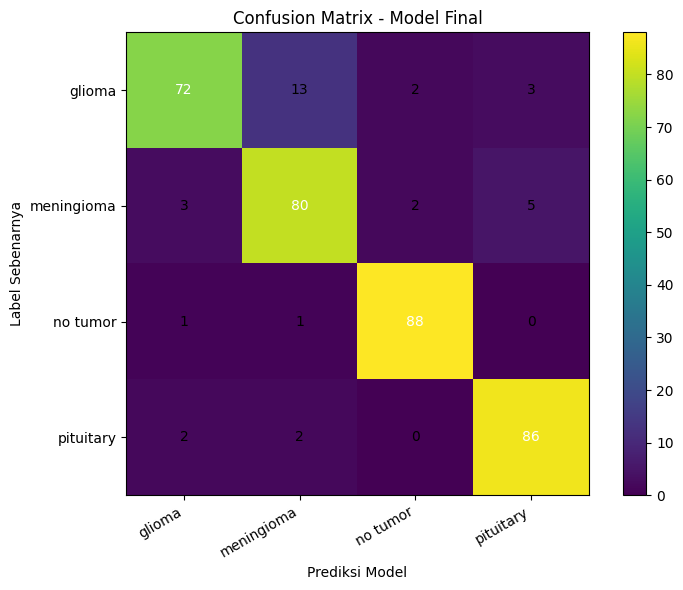


=== PERFORMA SETIAP KELAS ===


,Kelas,Precision,Recall,F1-score,Jumlah data
0,glioma,0.9231,0.8000,0.8571,90.0
1,meningioma,0.8333,0.8889,0.8602,90.0
2,no tumor,0.9565,0.9778,0.9670,90.0
3,pituitary,0.9149,0.9556,0.9348,90.0


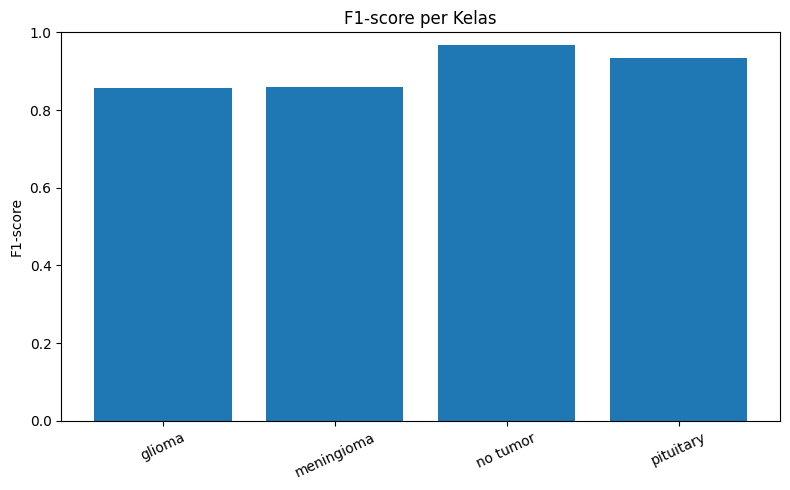


=== ANALISIS KESALAHAN ===
Jumlah prediksi salah: 34

Pasangan label yang paling sering tertukar:


,nama_label_asli,nama_label_prediksi,jumlah
0,glioma,meningioma,13
5,meningioma,pituitary,5
3,meningioma,glioma,3
2,glioma,pituitary,3
1,glioma,no tumor,2
4,meningioma,no tumor,2
9,pituitary,meningioma,2
8,pituitary,glioma,2
7,no tumor,meningioma,1
6,no tumor,glioma,1



=== FILE TERSIMPAN ===
Confusion matrix: /content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_17_confusion_matrix.png
Grafik F1 per kelas: /content/drive/MyDrive/Brain_Tumor_CNN/grafik/bagian_17_f1_per_kelas.png
Metrik per kelas: /content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_17_metrik_per_kelas.csv
Prediksi salah: /content/drive/MyDrive/Brain_Tumor_CNN/hasil/bagian_17_prediksi_salah.csv
Ringkasan analisis: /content/drive/MyDrive/Brain_Tumor_CNN/dokumen/bagian_17_ringkasan_analisis.json


In [ ]:
# ============================================================
# BAGIAN 17: ANALISIS DAN PEMBAHASAN HASIL
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"
RESULT_DIR = os.path.join(BASE_DIR, "hasil")
GRAPH_DIR = os.path.join(BASE_DIR, "grafik")
DOC_DIR = os.path.join(BASE_DIR, "dokumen")

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(DOC_DIR, exist_ok=True)

PRED_PATH = os.path.join(
    RESULT_DIR, "bagian_16_prediksi_final.csv"
)

if not os.path.exists(PRED_PATH):
    raise FileNotFoundError(
        "File prediksi Bagian 16 belum ditemukan. "
        "Jalankan Bagian 16 terlebih dahulu."
    )

# ------------------------------------------------------------
# 1. MEMUAT HASIL PREDIKSI
# ------------------------------------------------------------
df = pd.read_csv(PRED_PATH)

required_cols = ["label_asli", "label_prediksi"]
if not all(col in df.columns for col in required_cols):
    raise ValueError(
        f"CSV harus memiliki kolom: {required_cols}"
    )

y_true = df["label_asli"].astype(int).to_numpy()
y_pred = df["label_prediksi"].astype(int).to_numpy()

class_names = [
    "glioma", "meningioma", "no tumor", "pituitary"
]
class_ids = [0, 1, 2, 3]

if len(y_true) != len(y_pred):
    raise ValueError("Jumlah label dan prediksi tidak sama.")

if not np.isin(y_true, class_ids).all():
    raise ValueError("Label asli di luar rentang kelas 0–3.")

if not np.isin(y_pred, class_ids).all():
    raise ValueError("Label prediksi di luar rentang kelas 0–3.")

# ------------------------------------------------------------
# 2. METRIK KESELURUHAN
# ------------------------------------------------------------
metrics = {
    "Jumlah data test": int(len(y_true)),
    "Jumlah prediksi benar": int(np.sum(y_true == y_pred)),
    "Jumlah prediksi salah": int(np.sum(y_true != y_pred)),
    "Accuracy": float(accuracy_score(y_true, y_pred)),
    "Precision Macro": float(
        precision_score(
            y_true, y_pred, labels=class_ids,
            average="macro", zero_division=0
        )
    ),
    "Recall Macro": float(
        recall_score(
            y_true, y_pred, labels=class_ids,
            average="macro", zero_division=0
        )
    ),
    "F1 Macro": float(
        f1_score(
            y_true, y_pred, labels=class_ids,
            average="macro", zero_division=0
        )
    )
}

print("=== RINGKASAN EVALUASI ===")
for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.4f}")
    else:
        print(f"{name}: {value}")

# ------------------------------------------------------------
# 3. CONFUSION MATRIX
# ------------------------------------------------------------
cm = confusion_matrix(
    y_true, y_pred, labels=class_ids
)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm, interpolation="nearest")
fig.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Prediksi Model",
    ylabel="Label Sebenarnya",
    title="Confusion Matrix - Model Final"
)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

threshold = cm.max() / 2 if cm.size and cm.max() > 0 else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.tight_layout()
cm_path = os.path.join(
    GRAPH_DIR, "bagian_17_confusion_matrix.png"
)
fig.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. METRIK SETIAP KELAS
# ------------------------------------------------------------
report_dict = classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_df = pd.DataFrame([
    {
        "Kelas": name,
        "Precision": report_dict[name]["precision"],
        "Recall": report_dict[name]["recall"],
        "F1-score": report_dict[name]["f1-score"],
        "Jumlah data": report_dict[name]["support"]
    }
    for name in class_names
])

print("\n=== PERFORMA SETIAP KELAS ===")
display(class_df.round(4))

class_csv = os.path.join(
    RESULT_DIR, "bagian_17_metrik_per_kelas.csv"
)
class_df.to_csv(class_csv, index=False)

# Grafik F1-score per kelas
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(class_df["Kelas"], class_df["F1-score"])
ax.set_ylim(0, 1)
ax.set_ylabel("F1-score")
ax.set_title("F1-score per Kelas")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()

f1_path = os.path.join(
    GRAPH_DIR, "bagian_17_f1_per_kelas.png"
)
fig.savefig(f1_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. ANALISIS KESALAHAN PREDIKSI
# ------------------------------------------------------------
errors = df.loc[y_true != y_pred].copy()
errors.insert(
    0, "indeks_data_test",
    np.flatnonzero(y_true != y_pred)
)

id_to_name = dict(enumerate(class_names))
errors["nama_label_asli"] = errors["label_asli"].map(id_to_name)
errors["nama_label_prediksi"] = errors["label_prediksi"].map(
    id_to_name
)

error_path = os.path.join(
    RESULT_DIR, "bagian_17_prediksi_salah.csv"
)
errors.to_csv(error_path, index=False)

print("\n=== ANALISIS KESALAHAN ===")
print(f"Jumlah prediksi salah: {len(errors)}")

if len(errors) > 0:
    print("\nPasangan label yang paling sering tertukar:")
    pairs = (
        errors.groupby(
            ["nama_label_asli", "nama_label_prediksi"]
        )
        .size()
        .reset_index(name="jumlah")
        .sort_values("jumlah", ascending=False)
    )
    display(pairs)
else:
    print("Tidak ada kesalahan pada prediksi test set ini.")

# ------------------------------------------------------------
# 6. SIMPAN RINGKASAN UNTUK PEMBAHASAN
# ------------------------------------------------------------
summary = {
    "metrik_keseluruhan": metrics,
    "confusion_matrix": cm.tolist(),
    "kelas": class_names,
    "catatan": (
        "Analisis berdasarkan file prediksi Bagian 16. "
        "Pastikan pemetaan label kelas sesuai preprocessing."
    )
}

summary_path = os.path.join(
    DOC_DIR, "bagian_17_ringkasan_analisis.json"
)
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4, ensure_ascii=False)

print("\n=== FILE TERSIMPAN ===")
print("Confusion matrix:", cm_path)
print("Grafik F1 per kelas:", f1_path)
print("Metrik per kelas:", class_csv)
print("Prediksi salah:", error_path)
print("Ringkasan analisis:", summary_path)

In [ ]:
# ============================================================
# BAGIAN 18: KESIMPULAN PENELITIAN
# ============================================================

import os
import json

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"
RESULT_DIR = os.path.join(BASE_DIR, "hasil")
DOC_DIR = os.path.join(BASE_DIR, "dokumen")
os.makedirs(DOC_DIR, exist_ok=True)

METRIC_PATH = os.path.join(
    RESULT_DIR, "bagian_16_metrik_final.json"
)

if not os.path.exists(METRIC_PATH):
    raise FileNotFoundError(
        "Hasil evaluasi Bagian 16 belum ditemukan. "
        "Jalankan evaluasi model final terlebih dahulu."
    )

with open(METRIC_PATH, "r", encoding="utf-8") as f:
    metrics = json.load(f)

def fmt(key):
    value = metrics.get(key)
    if value is None:
        return "Belum tersedia"
    return f"{float(value):.4f} ({float(value)*100:.2f}%)"

accuracy = metrics.get("accuracy")
precision = metrics.get("precision_macro")
recall = metrics.get("recall_macro")
f1 = metrics.get("f1_macro")

conclusion = f"""
KESIMPULAN PENELITIAN
Progressive Ablation Study CNN untuk Klasifikasi MRI Tumor Otak

1. Evaluasi Model Final
Model final yang dievaluasi menghasilkan:
- Accuracy: {fmt("accuracy")}
- Precision Macro: {fmt("precision_macro")}
- Recall Macro: {fmt("recall_macro")}
- F1 Macro: {fmt("f1_macro")}

2. Interpretasi
Accuracy menunjukkan proporsi prediksi yang benar secara keseluruhan.
Precision Macro merangkum ketepatan prediksi antar kelas.
Recall Macro merangkum kemampuan model mengenali sampel dari tiap kelas.
F1 Macro merangkum keseimbangan precision dan recall antar kelas.

3. Hasil Progressive Ablation Study
Konfigurasi terbaik harus ditetapkan berdasarkan hasil validasi
dari seluruh eksperimen yang selesai dan dapat dibandingkan.
Jangan menyatakan suatu konfigurasi sebagai pemenang jika hasil
eksperimennya belum lengkap atau belum terverifikasi.

4. Keterbatasan
Hasil ini berasal dari dataset dan pembagian data yang digunakan
dalam penelitian. Performa pada dataset ini tidak menjamin performa
yang sama pada rumah sakit, perangkat MRI, atau populasi lain.
Model ini merupakan alat penelitian dan bukan pengganti diagnosis
oleh tenaga medis.

5. Hal yang Perlu Dilengkapi
- Nama konfigurasi model final berdasarkan rekap eksperimen.
- Perbandingan hasil seluruh skenario ablation.
- Temuan confusion matrix dan metrik tiap kelas.
- Keterbatasan serta saran penelitian selanjutnya.
""".strip()

output_path = os.path.join(
    DOC_DIR, "bagian_18_kesimpulan.txt"
)

with open(output_path, "w", encoding="utf-8") as f:
    f.write(conclusion)

print(conclusion)
print("\nKesimpulan disimpan di:", output_path)

KESIMPULAN PENELITIAN
Progressive Ablation Study CNN untuk Klasifikasi MRI Tumor Otak

1. Evaluasi Model Final
Model final yang dievaluasi menghasilkan:
- Accuracy: 0.9056 (90.56%)
- Precision Macro: 0.9070 (90.70%)
- Recall Macro: 0.9056 (90.56%)
- F1 Macro: 0.9048 (90.48%)

2. Interpretasi
Accuracy menunjukkan proporsi prediksi yang benar secara keseluruhan.
Precision Macro merangkum ketepatan prediksi antar kelas.
Recall Macro merangkum kemampuan model mengenali sampel dari tiap kelas.
F1 Macro merangkum keseimbangan precision dan recall antar kelas.

3. Hasil Progressive Ablation Study
Konfigurasi terbaik harus ditetapkan berdasarkan hasil validasi
dari seluruh eksperimen yang selesai dan dapat dibandingkan.
Jangan menyatakan suatu konfigurasi sebagai pemenang jika hasil
eksperimennya belum lengkap atau belum terverifikasi.

4. Keterbatasan
Hasil ini berasal dari dataset dan pembagian data yang digunakan
dalam penelitian. Performa pada dataset ini tidak menjamin performa
yang sama 

In [ ]:
# ============================================================
# BAGIAN 19: BACKUP ARTEFAK PENELITIAN
# ============================================================

import os
import json
import zipfile
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN"

FOLDERS_TO_BACKUP = [
    "models",
    "grafik",
    "hasil",
    "dokumen"
]

BACKUP_DIR = os.path.join(BASE_DIR, "backup")
os.makedirs(BACKUP_DIR, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
zip_path = os.path.join(
    BACKUP_DIR,
    f"backup_brain_tumor_cnn_{timestamp}.zip"
)

manifest = {
    "nama_proyek": "Progressive Ablation Study CNN",
    "dataset": "Brain Tumor MRI",
    "waktu_backup": datetime.now().isoformat(timespec="seconds"),
    "folder_dicadangkan": FOLDERS_TO_BACKUP,
    "catatan": (
        "Backup mencakup model, grafik, hasil, dan dokumen. "
        "Folder cache dan dataset tidak disertakan karena dapat "
        "berukuran besar; simpan keduanya secara terpisah."
    )
}

manifest_path = os.path.join(BACKUP_DIR, "manifest_backup.json")
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=4, ensure_ascii=False)

file_count = 0
missing_folders = []

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for folder_name in FOLDERS_TO_BACKUP:
        folder_path = os.path.join(BASE_DIR, folder_name)

        if not os.path.isdir(folder_path):
            missing_folders.append(folder_name)
            continue

        for root, _, files in os.walk(folder_path):
            for filename in files:
                full_path = os.path.join(root, filename)
                relative_path = os.path.relpath(full_path, BASE_DIR)
                zf.write(full_path, arcname=relative_path)
                file_count += 1

    zf.write(
        manifest_path,
        arcname="backup/manifest_backup.json"
    )

print("=== BACKUP SELESAI ===")
print("Lokasi ZIP:", zip_path)
print("Jumlah file:", file_count)

if missing_folders:
    print("Folder yang tidak ditemukan:", missing_folders)

print("\nIsi backup mencakup folder yang tersedia:")
for folder_name in FOLDERS_TO_BACKUP:
    print("-", folder_name)

print("\nPenting:")
print("- Periksa apakah file model final benar-benar ada.")
print("- Pastikan hasil eksperimen yang diperlukan sudah tersimpan.")
print("- Backup tidak menyertakan dataset dan folder cache.")

=== BACKUP SELESAI ===
Lokasi ZIP: /content/drive/MyDrive/Brain_Tumor_CNN/backup/backup_brain_tumor_cnn_20260930_095951.zip
Jumlah file: 111

Isi backup mencakup folder yang tersedia:
- models
- grafik
- hasil
- dokumen

Penting:
- Periksa apakah file model final benar-benar ada.
- Pastikan hasil eksperimen yang diperlukan sudah tersimpan.
- Backup tidak menyertakan dataset dan folder cache.
